In [137]:
%load_ext autoreload
%autoreload 2
import numpy as np
import jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
from sklearn.linear_model import Lasso, Ridge, LinearRegression, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPClassifier
import warnings
from sklearn.exceptions import ConvergenceWarning   # For part D4 so it will run
warnings.simplefilter("ignore", ConvergenceWarning)
import seaborn as sns
import time

# ==============================================================================

import plot_params
from config import SEED, K_FOLDS, FIGURES_PATH, RESULTS_PATH, DATA_PATH
from Data.data import load_mnist, train_val_split, one_hot, to_column
from Machine.network import NeuralNetwork, make_nn, NeuralNetClassifier
from Machine.optimizers import train
from Machine.metrics import (mse_score, accuracy, confusion_matrix, precision_recall_f1,
                             se, binomial_se, paired_diff)
import utils as u           # Reused functions from Project 1 + helper functions
import Data.plots as P

RERUN = False               # load saved results when they exist
COL = plot_params.COL       # our latex template column width in inches

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


<div style="background-color:#F0DAE2; color:#823C55; border-radius:12px; padding:16px; width:90%;">

**Part b)** Neural network

</div>

Runge data from Project 1, with a validation split of the training data for
tuning

In [104]:
runge_x_train, runge_x_test, runge_y_train, runge_y_test = u.create_dataset(rescale=False)

# (n, 1) for the network and sklearn
runge_X_train, runge_X_test = to_column(runge_x_train), to_column(runge_x_test)
runge_Y_train, runge_Y_test = to_column(runge_y_train), to_column(runge_y_test)

# Split 25% of train set for validation
runge_X_fit, runge_X_val, runge_Y_fit, runge_Y_val = train_val_split(
    runge_X_train, runge_Y_train, val_size=0.25, seed=SEED, stratify=False)

cv_folds = KFold(K_FOLDS, shuffle=True, random_state=SEED)

Helper functions for CV analysis

In [105]:
def cv_scores(model, X, y, cv=cv_folds, cap=1.0, n_jobs=None):
    '''Train and validation MSE in every fold. A diverged fold (MSE above cap) becomes NaN'''
    with warnings.catch_warnings(): # ignore diverged fold warnings
        warnings.simplefilter("ignore")
        res = cross_validate(model, X, y, cv=cv, scoring="neg_mean_squared_error",
                             return_train_score=True, error_score=np.nan, n_jobs=n_jobs)
    train_mse, val_mse = -res["train_score"], -res["test_score"]
    diverged = ~(val_mse <= cap)
    train_mse[diverged], val_mse[diverged] = np.nan, np.nan
    return train_mse, val_mse


def cv_mean_and_se(val_mse):
    '''Mean and standard error over the folds. One diverged fold makes the cell NaN'''
    k = val_mse.shape[-1]
    return val_mse.mean(axis=-1), val_mse.std(axis=-1, ddof=1) / np.sqrt(k)


def fold_arrays(X, y, train_idx, val_idx):
    '''
    Scaling and centering fitted on the training part only, as make_nn does inside
    cross_validate.
    For runs where we need the history per epoch, which cross_validate does not give.
    '''
    scaler = StandardScaler().fit(X[train_idx])
    y_mean = y[train_idx].mean()
    return(scaler.transform(X[train_idx]), to_column(y[train_idx] - y_mean),
           scaler.transform(X[val_idx]), to_column(y[val_idx] - y_mean))

OLS benchmark: best polynomial degree by k-fold CV on the training data

In [106]:
MAX_DEGREE = 20

def compute_ols_cv():
    cv_mse, cv_se = u.k_fold_degrees(runge_X_train, runge_y_train, K_FOLDS,
                                     LinearRegression(), maxdegree=MAX_DEGREE, return_se=True)
    return {"cv_mse": cv_mse, "cv_se": cv_se, "degrees": np.arange(1, MAX_DEGREE + 1)}

ols_cv = u.cached_arrays(RESULTS_PATH / "b_ols_cv.npz", compute_ols_cv, RERUN)
best_ols = u.best_cell(ols_cv["cv_mse"], degree=ols_cv["degrees"])
best_degree = int(best_ols["degree"])
ols_se = ols_cv["cv_se"][best_ols["index"]]

# the lowest degree whose CV MSE is within one SE of the best
simplest_degree = int(ols_cv["degrees"][ols_cv["cv_mse"] <= best_ols["value"] + ols_se][0])

# ==============================================================================

# Refit on whole training set, and look at test set once
ols_model = u.poly_model(best_degree, LinearRegression()).fit(runge_X_train, runge_y_train)
ols_train_mse = mse_score(runge_y_train, ols_model.predict(runge_X_train))
ols_test_mse = mse_score(runge_y_test, ols_model.predict(runge_X_test))
print(f"OLS: best degree {best_degree} (CV MSE {best_ols['value']:.4f} ± {ols_se:.4f}), "
      f"1-SE degree {simplest_degree}, train MSE {ols_train_mse:.4f}, test MSE {ols_test_mse:.4f}")

OLS: best degree 12 (CV MSE 0.0141 ± 0.0016), 1-SE degree 10, train MSE 0.0104, test MSE 0.0093


Learning rate sweep

Best: SGD + Adam, gamma = 3.2e-03, CV MSE 0.0134 ± 0.0015


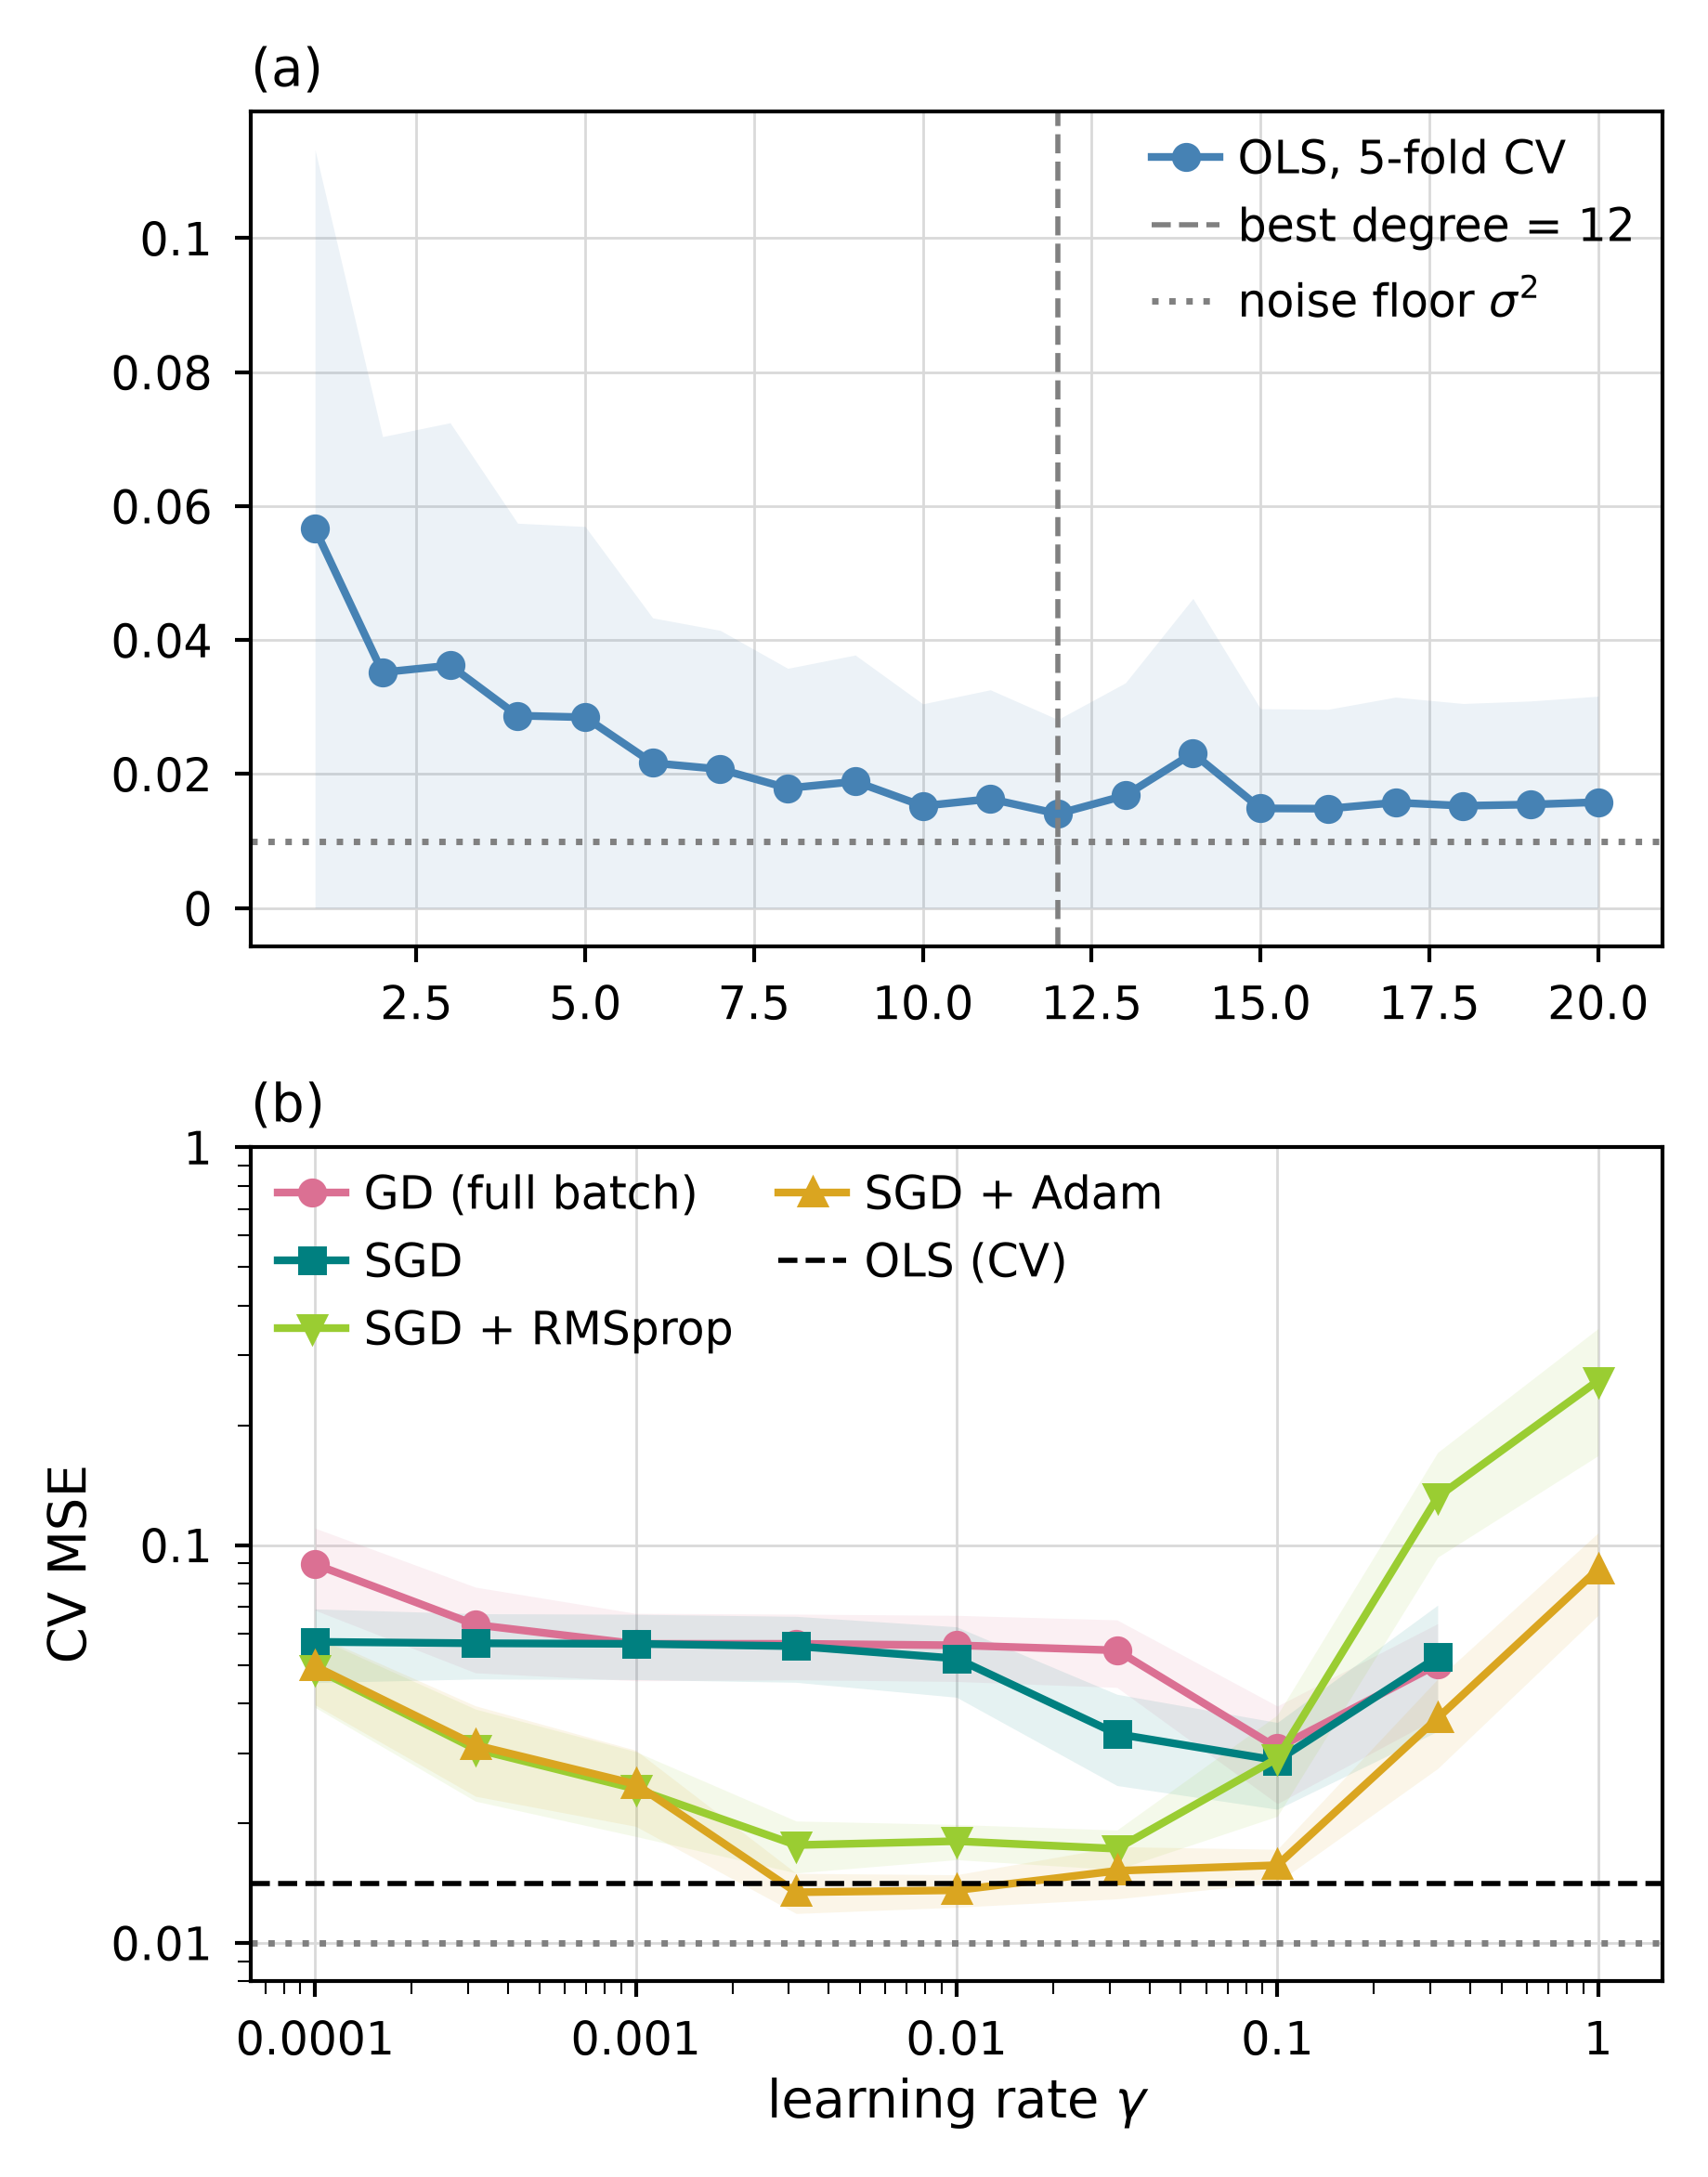

In [107]:
OPTIMIZERS = {                        # label: (model, batch size)
    "GD (full batch)": ("plain", None),
    "SGD": ("plain", 10),
    "SGD + RMSprop": ("rmsprop", 10),
    "SGD + Adam": ("adam", 10)
}
OPT_COLORS = ["palevioletred", "teal", "yellowgreen", "goldenrod"]
LEARNING_RATES = np.geomspace(1e-4, 1.0, 9)
EPOCHS_B = 1000

def compute_lr_sweep():
    shape = (len(OPTIMIZERS), len(LEARNING_RATES), K_FOLDS)
    train_mse, val_mse = np.full(shape, np.nan), np.full(shape, np.nan)
    for i, (method, batch_size) in enumerate(OPTIMIZERS.values()):
        for j, gamma in enumerate(LEARNING_RATES):
            model = make_nn(hidden=(50,), method=method, gamma=gamma,
                            epochs=EPOCHS_B, batch_size=batch_size)
            train_mse[i, j], val_mse[i, j] = cv_scores(model, runge_X_train, runge_y_train)
    return {"train_mse": train_mse, "val_mse": val_mse}

lr_sweep = u.cached_arrays(RESULTS_PATH / "b_lr_sweep.npz", compute_lr_sweep, RERUN)
lr_mean, lr_sr = cv_mean_and_se(lr_sweep["val_mse"])

best_b = u.best_cell(lr_mean, optimizer=list(OPTIMIZERS), gamma=LEARNING_RATES)
print(f"Best: {best_b['optimizer']}, gamma = {best_b['gamma']:.1e}, "
      f"CV MSE {best_b['value']:.4f} ± {lr_se[best_b['index']]:.4f}")

# ==============================================================================

fig, (ax_ols, ax_lr) = plt.subplots(2, 1, figsize=(COL, 4.6))

# OLS: CV error against polynomial degree
P.band(ax_ols, ols_cv["degrees"], ols_cv["cv_mse"], ols_cv["cv_mse"],
       color="steelblue", marker="o", label="OLS, 5-fold CV")
ax_ols.axvline(best_degree, ls="--", color="gray", lw=0.8, label=f"best degree = {best_degree}")
P.noise_floor(ax_ols)
ax_ols.set_title("(a)", loc="left")
P.plain_log_ticks(ax_ols, "y")
ax_ols.legend()

# NN: CV error against learning rate. Gaps = diverged
for i, (label, color, marker) in enumerate(zip(OPTIMIZERS, OPT_COLORS, "osv^")):
    P.band(ax_lr, LEARNING_RATES, lr_mean[i], lr_se[i], label=label, color=color, marker=marker)
P.noise_floor(ax_lr, label=False)
ax_lr.axhline(best_ols["value"], color="k", ls="--", lw=0.8, label="OLS (CV)")
ax_lr.set(xscale="log", yscale="log", ylim=(0.008, 1), xlabel=r"learning rate $\gamma$", ylabel="CV MSE")
ax_lr.set_title("(b)", loc="left")
P.plain_log_ticks(ax_lr, "x"); P.plain_log_ticks(ax_lr, "y")
ax_lr.legend(loc="upper left", ncol=2)
fig.savefig(FIGURES_PATH / "B-tuning.pdf")

Architectures: for each, pick $\gamma$ on the validation set, retrain on the
full training set, then evaluate once on the test set

In [120]:
ARCHITECTURES = {               # label: layer sizes [input, hiden..., output]
    "1 x 50":   [1, 50, 1],
    "1 x 500":  [1, 500, 1],
    "2 x 50":   [1, 50, 50, 1],
    "2 x 100":  [1, 100, 100, 1]
}
# Best optimizer from the learning-rate sweep
best_method, best_batch_size = OPTIMIZERS[best_b["optimizer"]]
print(best_method, best_batch_size)

# Dense grid for smooth curves
grid_x = np.linspace(-1, 1, 400)
runge_true_curve = 1 / (1 + 25 * grid_x**2)

def compute_architectures():
    n_arch = len(ARCHITECTURES)
    cv_val = np.full((n_arch, len(LEARNING_RATES), K_FOLDS), np.nan)
    best_gammas, train_mse, test_mse = np.zeros(n_arch), np.zeros(n_arch), np.zeros(n_arch)
    curves = np.zeros((n_arch, len(grid_x)))
    for i, sizes in enumerate(ARCHITECTURES.values()):
        # 1: choose gamma by cross-validation on the training set
        for j, gamma in enumerate(LEARNING_RATES):
            net = make_nn(hidden=tuple(sizes[1:-1]), method=best_method, gamma=gamma,
                          epochs=EPOCHS_B, batch_size=best_batch_size)
            _, cv_val[i, j] = cv_scores(net, runge_X_train, runge_y_train)
        best_gammas[i] = u.best_cell(cv_val[i].mean(axis=-1), gamma=LEARNING_RATES)["gamma"]
        
        # 2: refit on the whole training set, then look at test set once
        model = make_nn(hidden=tuple(sizes[1:-1]), method=best_method, gamma=best_gammas[i],
                        epochs=EPOCHS_B, batch_size=best_batch_size).fit(runge_X_train, runge_y_train)
        train_mse[i] = mse_score(runge_y_train, model.predict(runge_X_train))
        test_mse[i] = mse_score(runge_y_test, model.predict(runge_X_test))
        curves[i] = model.predict(to_column(grid_x))
    return {"best_gammas": best_gammas, "train_mse": train_mse, "test_mse": test_mse,
            "curves": curves, "cv_val":cv_val}
    
arch_results = u.cached_arrays(RESULTS_PATH / "b_architectures.npz", compute_architectures, RERUN)

adam 10


Results table and fitted curves, for OLS vs the four networks

Best method: adam 
Best batch size: 10
----------------------------------------
model             gamma  train MSE   CV MSE          test MSE
OLS deg 12                  0.0104   0.0141 ± 0.0016    0.0093
NN 1 x 50       3.2e-03     0.0111   0.0134 ± 0.0015    0.0083
NN 1 x 500      1.0e-03     0.0181   0.0214 ± 0.0050    0.0143
NN 2 x 50       1.0e-02     0.0103   0.0139 ± 0.0010    0.0204
NN 2 x 100      1.0e-03     0.0108   0.0125 ± 0.0006    0.0153


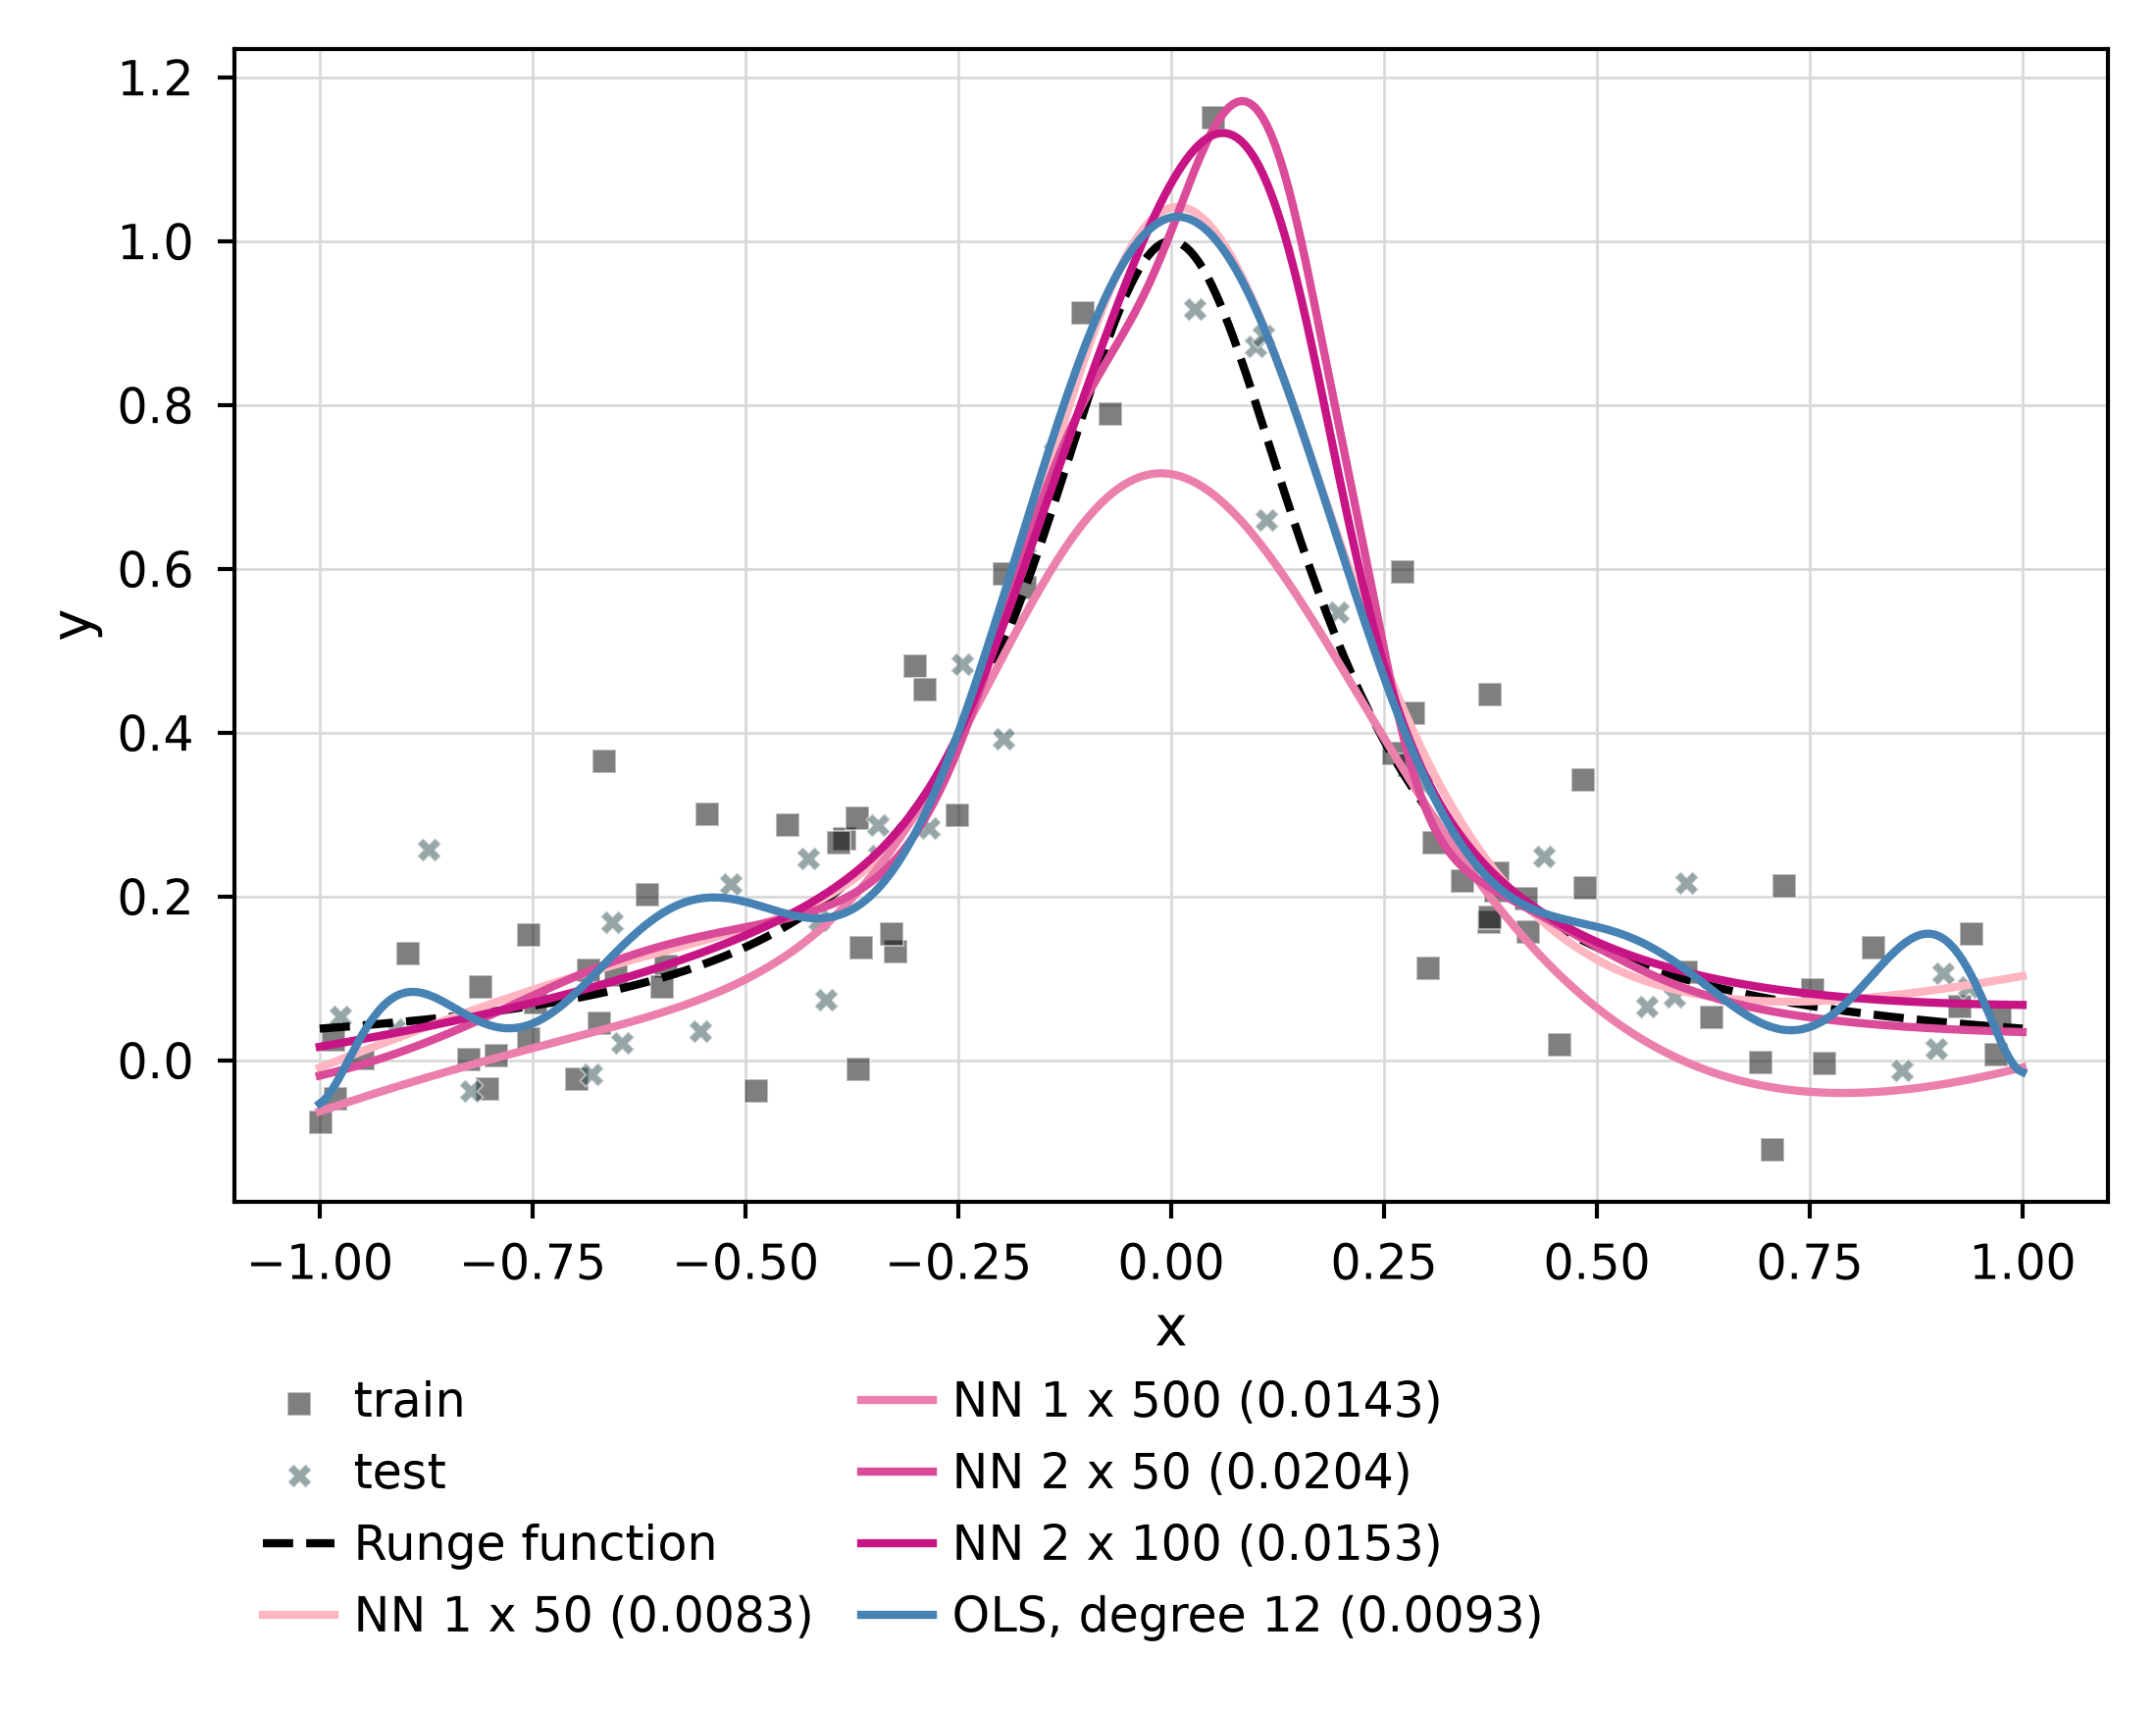

In [123]:
ols_curve = ols_model.predict(grid_x.reshape(-1, 1))
nn_colors = sns.blend_palette(["lightpink", "mediumvioletred"], len(ARCHITECTURES))

arch_mean, arch_se = cv_mean_and_se(arch_results["cv_val"])
chosen = [np.argmin(np.where(np.isfinite(m), m, np.inf)) for m in arch_mean]

print(f"Best method: {best_method} \nBest batch size: {best_batch_size}\n" + '-'*40)
print(f"{'model':<14}{'gamma':>9}{'train MSE':>11}{'CV MSE':>9}{'':>8}{'test MSE':>10}")
print(f"{'OLS deg ' + str(best_degree):<14}{'':>9}{ols_train_mse:>11.4f}"
      f"{best_ols['value']:>9.4f} ± {ols_se:.4f}{ols_test_mse:>10.4f}")
for i, label in enumerate(ARCHITECTURES):
    print(f"{'NN ' + label:<14}{arch_results['best_gammas'][i]:>9.1e}{arch_results['train_mse'][i]:>11.4f}"
          f"{arch_mean[i, chosen[i]]:>9.4f} ± {arch_se[i, chosen[i]]:.4f}{arch_results["test_mse"][i]:>10.4f}")

fig, ax = plt.subplots(figsize=(COL * 1.2, 3.4))
sns.scatterplot(x=runge_x_train, y=runge_y_train, color="k", alpha=0.5, marker="s", label="train", ax=ax)
sns.scatterplot(x=runge_x_test, y=runge_y_test, color="darkslategray", alpha=0.5, marker="X", label="test", ax=ax)
ax.plot(grid_x, runge_true_curve, "k--", label="Runge function")
for (label, curve, te), color in zip(zip(ARCHITECTURES, arch_results["curves"], arch_results["test_mse"]), nn_colors):
    sns.lineplot(x=grid_x, y=curve, color=color, label=f"NN {label} ({te:.4f})", ax=ax)
sns.lineplot(x=grid_x, y=ols_curve, color="steelblue", 
             label=f"OLS, degree {best_degree} ({ols_test_mse:.4f})", ax=ax)
ax.set(xlabel="x", ylabel="y")
ax.legend(loc="upper left", bbox_to_anchor=(0.0, -0.13), ncol=2)
fig.savefig(FIGURES_PATH / "B-fits.pdf")

<div style="background-color:#F0DAE2; color:#823C55; border-radius:12px; padding:16px; width:90%;">

**Part c)** Activation functions and depths

</div>

Sweep over activation, depth and $\gamma$, ran over several seeds

In [124]:
ACTIVATIONS = ["sigmoid", "relu", "leaky_relu"]
ACT_COLORS = ["olivedrab", "palevioletred", "steelblue"]
DEPTHS = [1, 2, 3, 4]                   # number of hidden layers
WIDTHS = [10, 25, 50, 100]              # nodes per hidden layer
GAMMAS_C = np.geomspace(1e-3, 1.0, 4)
EPOCHS_C = 500

def compute_depth_width_sweep():
    shape = (len(ACTIVATIONS), len(DEPTHS), len(WIDTHS), len(GAMMAS_C), K_FOLDS)
    train_mse, val_mse = np.full(shape, np.nan), np.full(shape, np.nan)
    for a, d, w, g in np.ndindex(shape[:-1]):       # loop over every grid point
        with np.errstate(all="ignore"):
            model = make_nn(hidden=(WIDTHS[w],) * DEPTHS[d], activation=ACTIVATIONS[a],
                            method=best_method, gamma=GAMMAS_C[g], epochs=EPOCHS_C,
                            batch_size=best_batch_size)
            train_mse[a, d, w, g], val_mse[a, d, w, g] = cv_scores(model, runge_X_train, runge_y_train)
    return {"train_mse": train_mse, "val_mse": val_mse}

depth_width = u.cached_arrays(RESULTS_PATH / "c_depth_width.npz", compute_depth_width_sweep, RERUN)

Best $\gamma$ for every (activation, depth, width), shown as heat maps.
The overall winner is stored in `best_c`.

Overall best: sigmoid, depth 4, width 100, gamma 1e-03, CV MSE 0.0131 ± 0.0008
---------------------------------------------------------------
sigmoid    best: depth 4, width 100, gamma 1e-03, CV MSE 0.0131 ± 0.0008
relu       best: depth 4, width 50, gamma 1e-03, CV MSE 0.0156 ± 0.0015
leaky_relu best: depth 3, width 25, gamma 1e-02, CV MSE 0.0158 ± 0.0014
4 of 48 cells are within one SE of the best
Median CV/train MSE ratio at the best gamma: 1.6


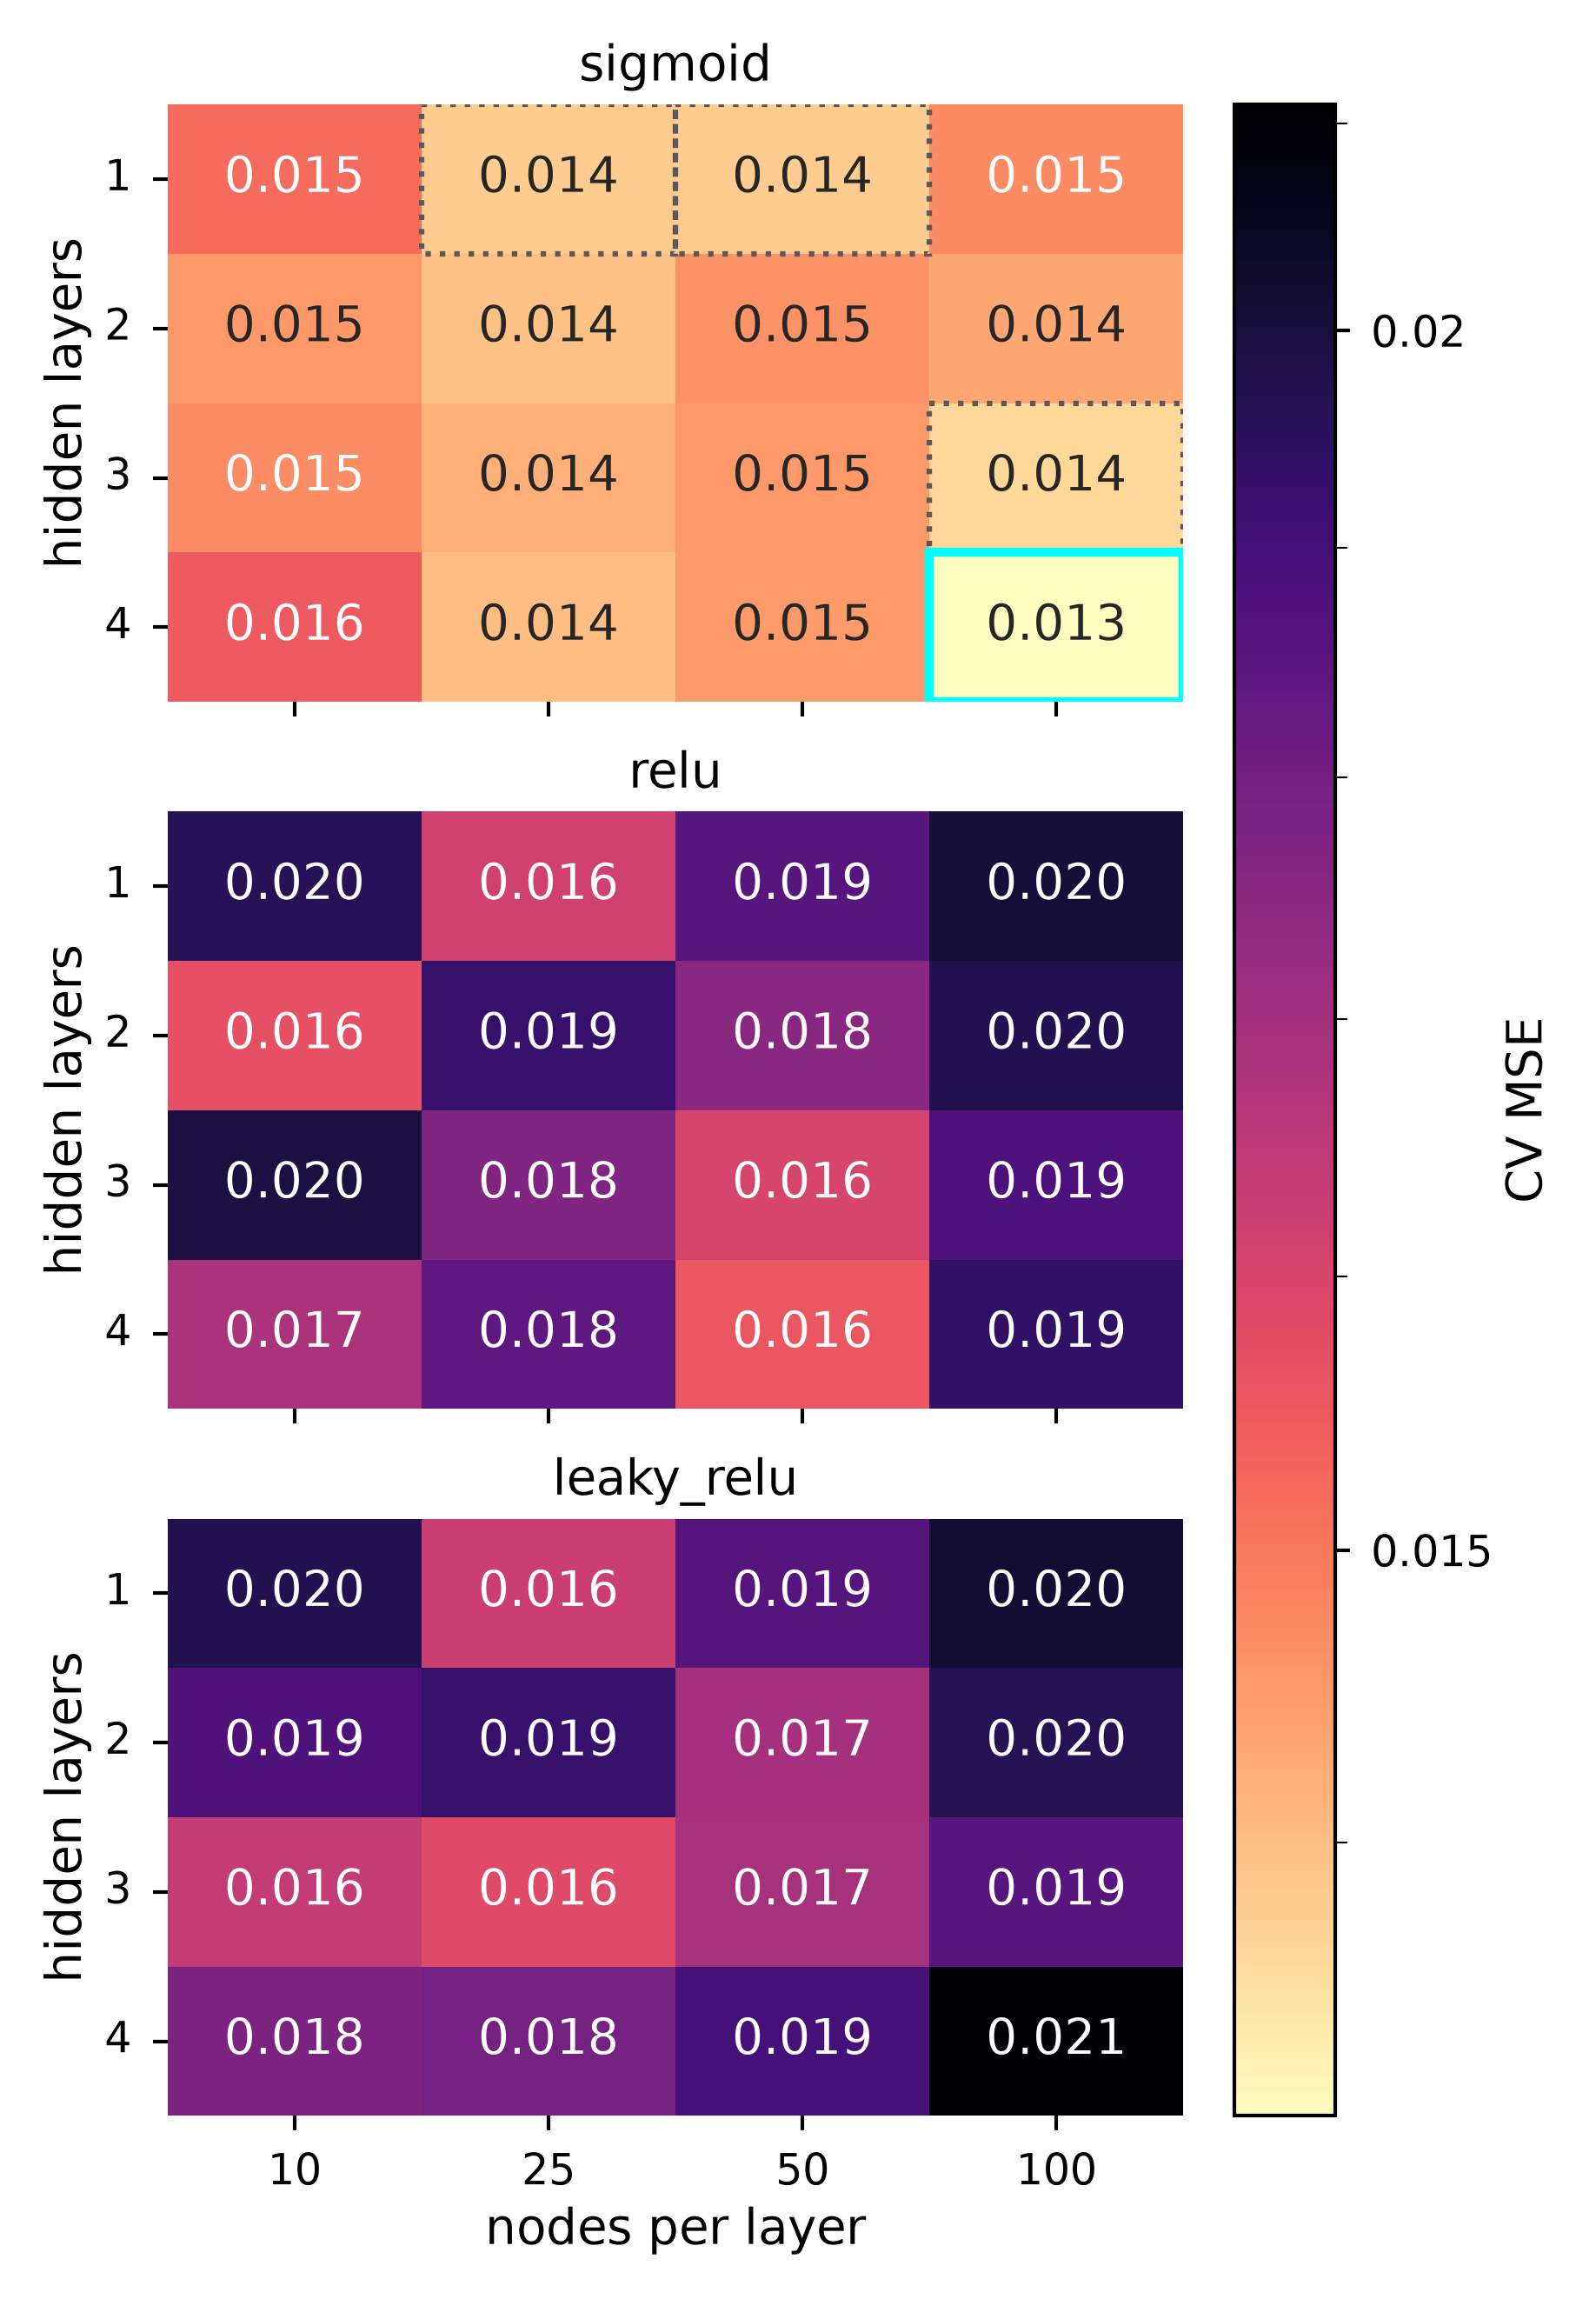

In [125]:
val_mean, val_se = cv_mean_and_se(depth_width["val_mse"])
best_c = u.best_cell(val_mean, activation=ACTIVATIONS, depth=DEPTHS, width=WIDTHS, gamma=GAMMAS_C)
best_c_se = val_se[best_c["index"]]
print(f"Overall best: {best_c['activation']}, depth {best_c['depth']}, "
      f"width {best_c['width']}, gamma {best_c['gamma']:.0e}, "
      f"CV MSE {best_c['value']:.4f} ± {best_c_se:.4f}")
print("---------------------------------------------------------------")
for a, activation in enumerate(ACTIVATIONS):
      best = u.best_cell(val_mean[a], depth=DEPTHS, width=WIDTHS, gamma=GAMMAS_C)
      print(f"{activation:10s} best: depth {best['depth']}, width {best['width']}, "
            f"gamma {best['gamma']:.0e}, CV MSE {best['value']:.4f} ± {val_se[a][best['index']]:.4f}")

# Best gamma in every (activation, depth, width) cell
best_g = np.argmin(np.where(np.isfinite(val_mean), val_mean, np.inf), axis=-1)
a_i, d_i, w_i = np.indices(best_g.shape)
val_best_gamma = val_mean[a_i, d_i, w_i, best_g]
train_best_gamma = depth_width["train_mse"].mean(axis=-1)[a_i, d_i, w_i, best_g]

# Cells within one SE of the overall best are statistically tied with it
within = val_best_gamma <= best_c["value"] + best_c_se
print(f"{within.sum()} of {within.size} cells are within one SE of the best")
print(f"Median CV/train MSE ratio at the best gamma: {np.nanmedian(val_best_gamma / train_best_gamma):.1f}")

heat_min, heat_max = np.nanmin(val_best_gamma), min(np.nanmax(val_best_gamma), 1.0)
fig, axes = plt.subplots(3, 1, figsize=(COL, 5.2), sharex=True)
for a, (ax, activation) in enumerate(zip(axes, ACTIVATIONS)):
      sns.heatmap(val_best_gamma[a], ax=ax, cmap="magma_r", norm=LogNorm(heat_min, heat_max),
                  annot=True, fmt=".3f", cbar=False,
                  xticklabels=WIDTHS, yticklabels=DEPTHS)
      P.heatmap_marks(ax, within[a], best=best_c["index"][1:3] if a == best_c["index"][0] else None)
      ax.set(title=activation, ylabel="hidden layers")
      ax.tick_params(axis="y", rotation=0)
axes[-1].set_xlabel("nodes per layer")
ticks = [t for t in (0.01, 0.015, 0.02, 0.03, 0.05, 0.1, 0.2, 0.5, 1) if heat_min <= t <= heat_max]
cbar = fig.colorbar(axes[0].collections[0], ax=axes, label="CV MSE", ticks=ticks)
P.plain_log_ticks(cbar.ax, "y")
fig.savefig(FIGURES_PATH / "C-activation_depth_width.pdf")

Overfitting: train a long run of the biggest network per activation and compare
train and validation MSE

In [126]:
EPOCHS_OVERFIT = 3000

def compute_overfitting_curves():
    shape = (len(ACTIVATIONS), K_FOLDS, EPOCHS_OVERFIT)
    train_curves, val_curves = np.full(shape, np.nan), np.full(shape, np.nan)
    for a, activation in enumerate(ACTIVATIONS):
        for k, (fit_idx, val_idx) in enumerate(cv_folds.split(runge_X_train)):
            X_fit, Y_fit, X_val, Y_val = fold_arrays(runge_X_train, runge_y_train, fit_idx, val_idx)
            
            # gamma = 1e-3 for all activations, so the panels ar ecomparable
            net = NeuralNetwork([1] + [WIDTHS[-1]] * DEPTHS[-1] + [1],
                                [activation] * DEPTHS[-1] + ["identity"],
                                "mse", seed=SEED)
            with np.errstate(all="ignore"):
                history = train(net, X_fit, Y_fit, method=best_method, gamma=GAMMAS_C[0],
                                epochs=EPOCHS_OVERFIT, batch_size=best_batch_size, seed=SEED,
                                X_val=X_val, Y_val=Y_val)
            n = len(history["val_cost"])
            train_curves[a, k, :n], val_curves[a, k, :n] = history["train_cost"], history["val_cost"]
    return {"train_curves": train_curves, "val_curves": val_curves}

overfit = u.cached_arrays(RESULTS_PATH / "c_overfitting_curves.npz", compute_overfitting_curves, RERUN)

Vanishing gradients: gradient per layer at initialization in a deep network

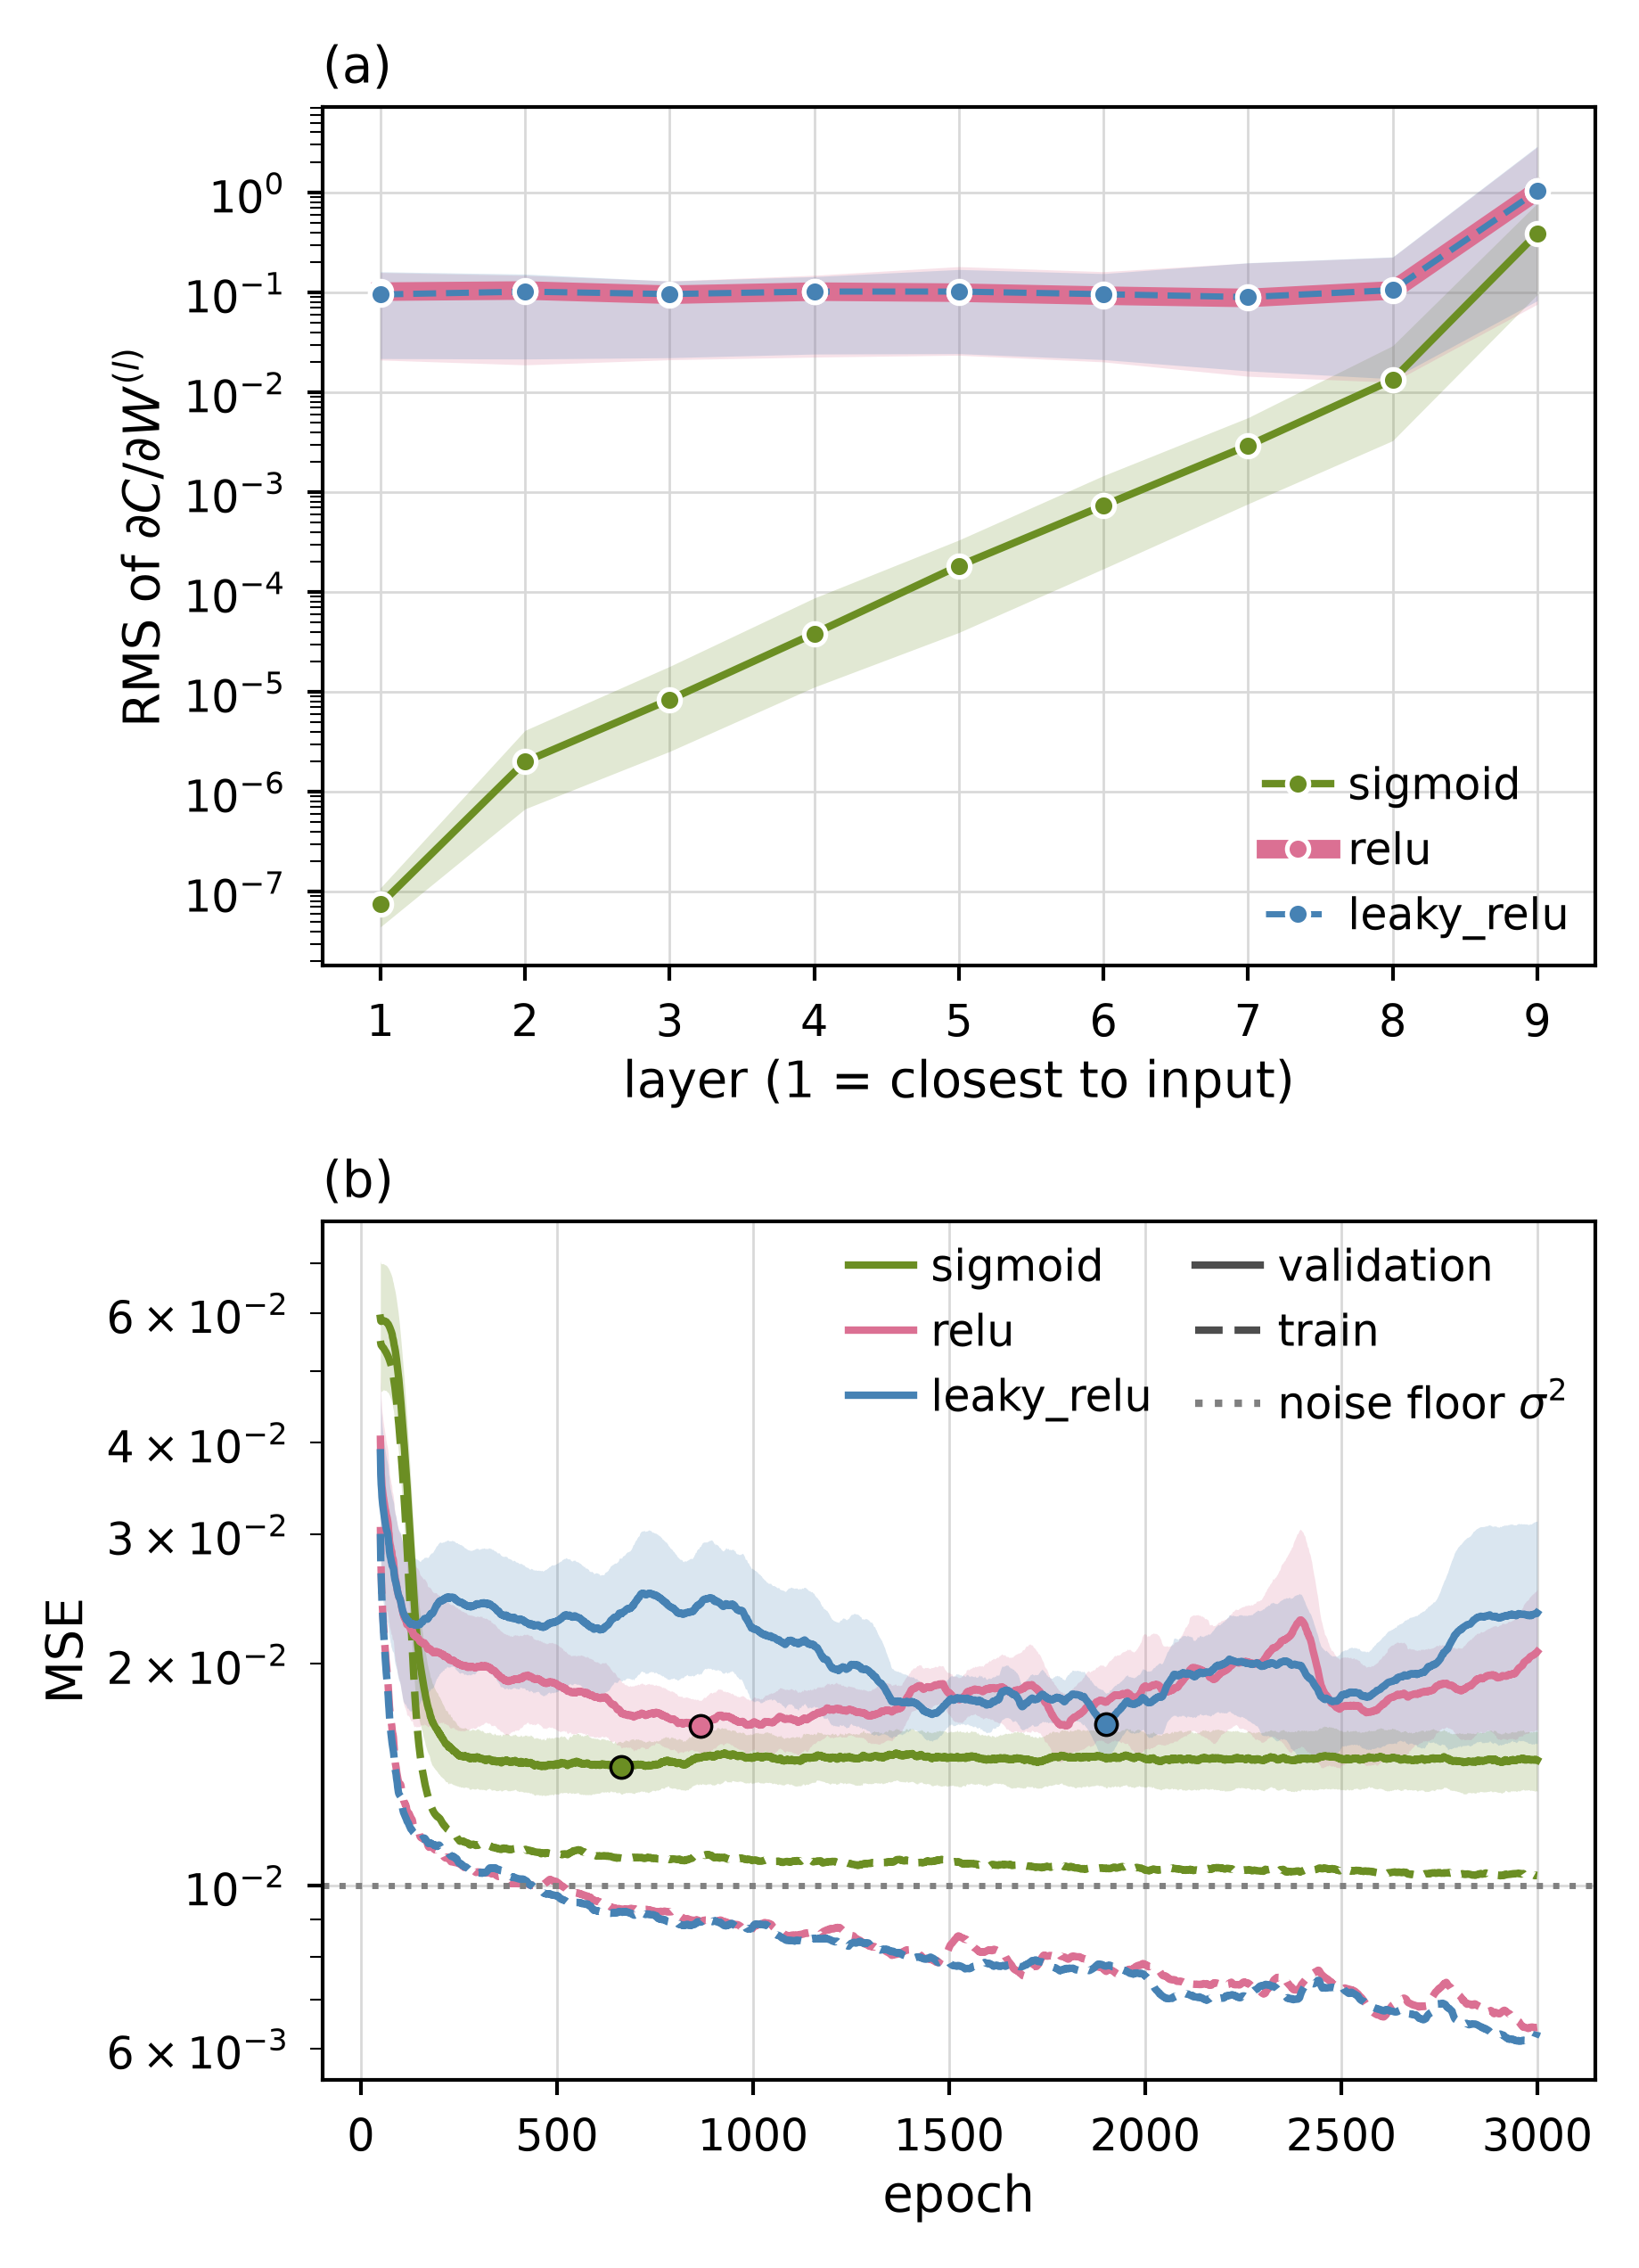

In [127]:
N_INIT = 10

def layer_rms_grads(activation, depth=8, width=50, seed=SEED):
    '''Norm of dC/dW in every layer at initialization (no training)'''
    X = StandardScaler().fit_transform(runge_X_train)
    Y = to_column(runge_y_train - runge_y_train.mean())
    net = NeuralNetwork([1] + [width] * depth + [1], 
                        [activation] * depth + ["identity"], "mse", seed=seed)
    gradients = net.compute_gradient(X, Y)
    return [np.sqrt(np.mean(dW ** 2)) for dW, _ in gradients]

grad_rms = np.array([[layer_rms_grads(act, seed=s) for s in range(N_INIT)] for act in ACTIVATIONS])
layers = np.arange(1, grad_rms.shape[-1] + 1)       # (activation, init, layer)

def smooth(y, k=50):
    '''Moving average over k epochs, so the RMSProp noise doesn't hide the trend'''
    return np.convolve(y, np.ones(k) / k, mode="valid")

K_S = 50
epochs = np.arange(1, EPOCHS_OVERFIT + 1)
x_s = epochs[K_S - 1:]

fig, (ax_g, ax_c) = plt.subplots(2, 1, figsize=(COL, 5.0))

# (a) gradient per layer: median over initialization
for a, (activation, color, ls, lw) in enumerate(zip(ACTIVATIONS, ACT_COLORS, ["-", "-", "--"], [1.2, 3, 1])):
    sns.lineplot(x=layers, y=np.median(grad_rms[a], axis=0), color=color, ls=ls, lw=lw, marker="o", label=activation, ax=ax_g)
    ax_g.fill_between(layers, grad_rms[a].min(axis=0), grad_rms[a].max(axis=0), color=color, alpha=0.2, lw=0)
ax_g.set(yscale="log", xlabel="layer (1 = closest to input)", ylabel=r"RMS of $\partial C/\partial W^{(l)}$")
ax_g.set_title("(a)", loc="left")
ax_g.legend(loc="lower right")

# (b) train (dashed) and validation (solid) MSE, mean over folds, band = SE of the validation curve
for a, (activation, color) in enumerate((zip(ACTIVATIONS, ACT_COLORS))):
    val = np.nanmean(overfit["val_curves"][a], axis=0)
    val_se = np.nanstd(overfit["val_curves"][a], axis=0, ddof=1) / np.sqrt(K_FOLDS)
    train_ = np.nanmean(overfit["train_curves"][a], axis=0)
    v_s = smooth(val, K_S)
    ax_c.plot(x_s, v_s, color=color, label=activation)
    ax_c.fill_between(x_s, v_s - smooth(val_se, K_S), v_s + smooth(val_se, K_S),
                      color=color, alpha=0.2, lw=0)
    ax_c.plot(x_s, smooth(train_, K_S), color=color, ls="--")
    ax_c.plot(x_s[np.argmin(v_s)], v_s.min(), "o", color=color, mec="k", mew=0.5, zorder=3) # lowest validation MSE
P.noise_floor(ax_c, label=False)
ax_c.set(yscale="log", xlabel="epoch", ylabel="MSE")
ax_c.set_title("(b)", loc="left")
ax_c.legend(handles=ax_c.get_legend_handles_labels()[0][:3] + [Line2D([], [], color="0.3", label="validation"),
                                                               Line2D([], [], color="0.3", ls="--", label="train"),
                                                               Line2D([], [], color="gray", ls=":", label=r"noise floor $\sigma^2$")],
            ncol=2, loc="upper right")
fig.savefig(FIGURES_PATH / "C-dynamics.pdf")

<div style="background-color:#F0DAE2; color:#823C55; border-radius:12px; padding:16px; width:90%;">

**Part d)** Different norms

</div>

Get the best architecture from Part C for penalty study

In [128]:
ARCH_ACTIVATION, ARCH_DEPTH, ARCH_WIDTH = best_c["activation"], best_c["depth"], best_c["width"]
print(f"{ARCH_ACTIVATION}, {ARCH_DEPTH} hidden layers x {ARCH_WIDTH} nodes")

sigmoid, 4 hidden layers x 100 nodes


Sweep over penalty strength $\lambda$ and learning rate $\gamma$, for $\ell_2$ and $\ell_1$

In [129]:
NORMS = ["l2", "l1"]
LAMBDAS = np.concatenate([[0], np.logspace(-6, -2, 9)])
GAMMAS_D = np.geomspace(1e-4, 1e-1, 7)
SEEDS_D = [0, 1, 2]
EPOCHS_D = 500
PENALIZE_BIAS = False

def compute_penalty_sweep():
    shape = (len(NORMS), len(LAMBDAS), len(GAMMAS_D), K_FOLDS)
    train_mse, val_mse = np.full(shape, np.nan), np.full(shape, np.nan)
    for n, l, g in np.ndindex(shape[:-1]):
        with np.errstate(all="ignore"):
            lam1, lam2 = (LAMBDAS[l], 0.0) if NORMS[n] == "l1" else (0.0, LAMBDAS[l])
            model = make_nn(hidden=(ARCH_WIDTH,) * ARCH_DEPTH, activation=ARCH_ACTIVATION,
                            method=best_method, gamma=GAMMAS_D[g], lmbd1=lam1, lmbd2=lam2,
                            epochs=EPOCHS_D, batch_size=best_batch_size, seed=SEED, penalize_bias=PENALIZE_BIAS)
            
            # The score is the plain MSE on the validation fold, without the
            # penalty term
            train_mse[n, l, g], val_mse[n, l, g] = cv_scores(model, runge_X_train, runge_y_train)
    return {"train_mse": train_mse, "val_mse": val_mse}

penalty_sweep = u.cached_arrays(RESULTS_PATH / "d_penalty_sweep.npz", compute_penalty_sweep, RERUN)

Heat maps of validation MSE over $(\lambda\,\gamma)$ + paired comparison.

l2: best lambda 1e-06, gamma 1e-03, CV MSE 0.0131 ± 0.0008, 7 cells within one SE
l1: best lambda 0e+00, gamma 1e-03, CV MSE 0.0131 ± 0.0008, 5 cells within one SE

l2: no penalty - penalized = +0.0000 ± 0.0000 (paired over folds)
l1: no penalty - penalized = -0.0001 ± 0.0001 (paired over folds)


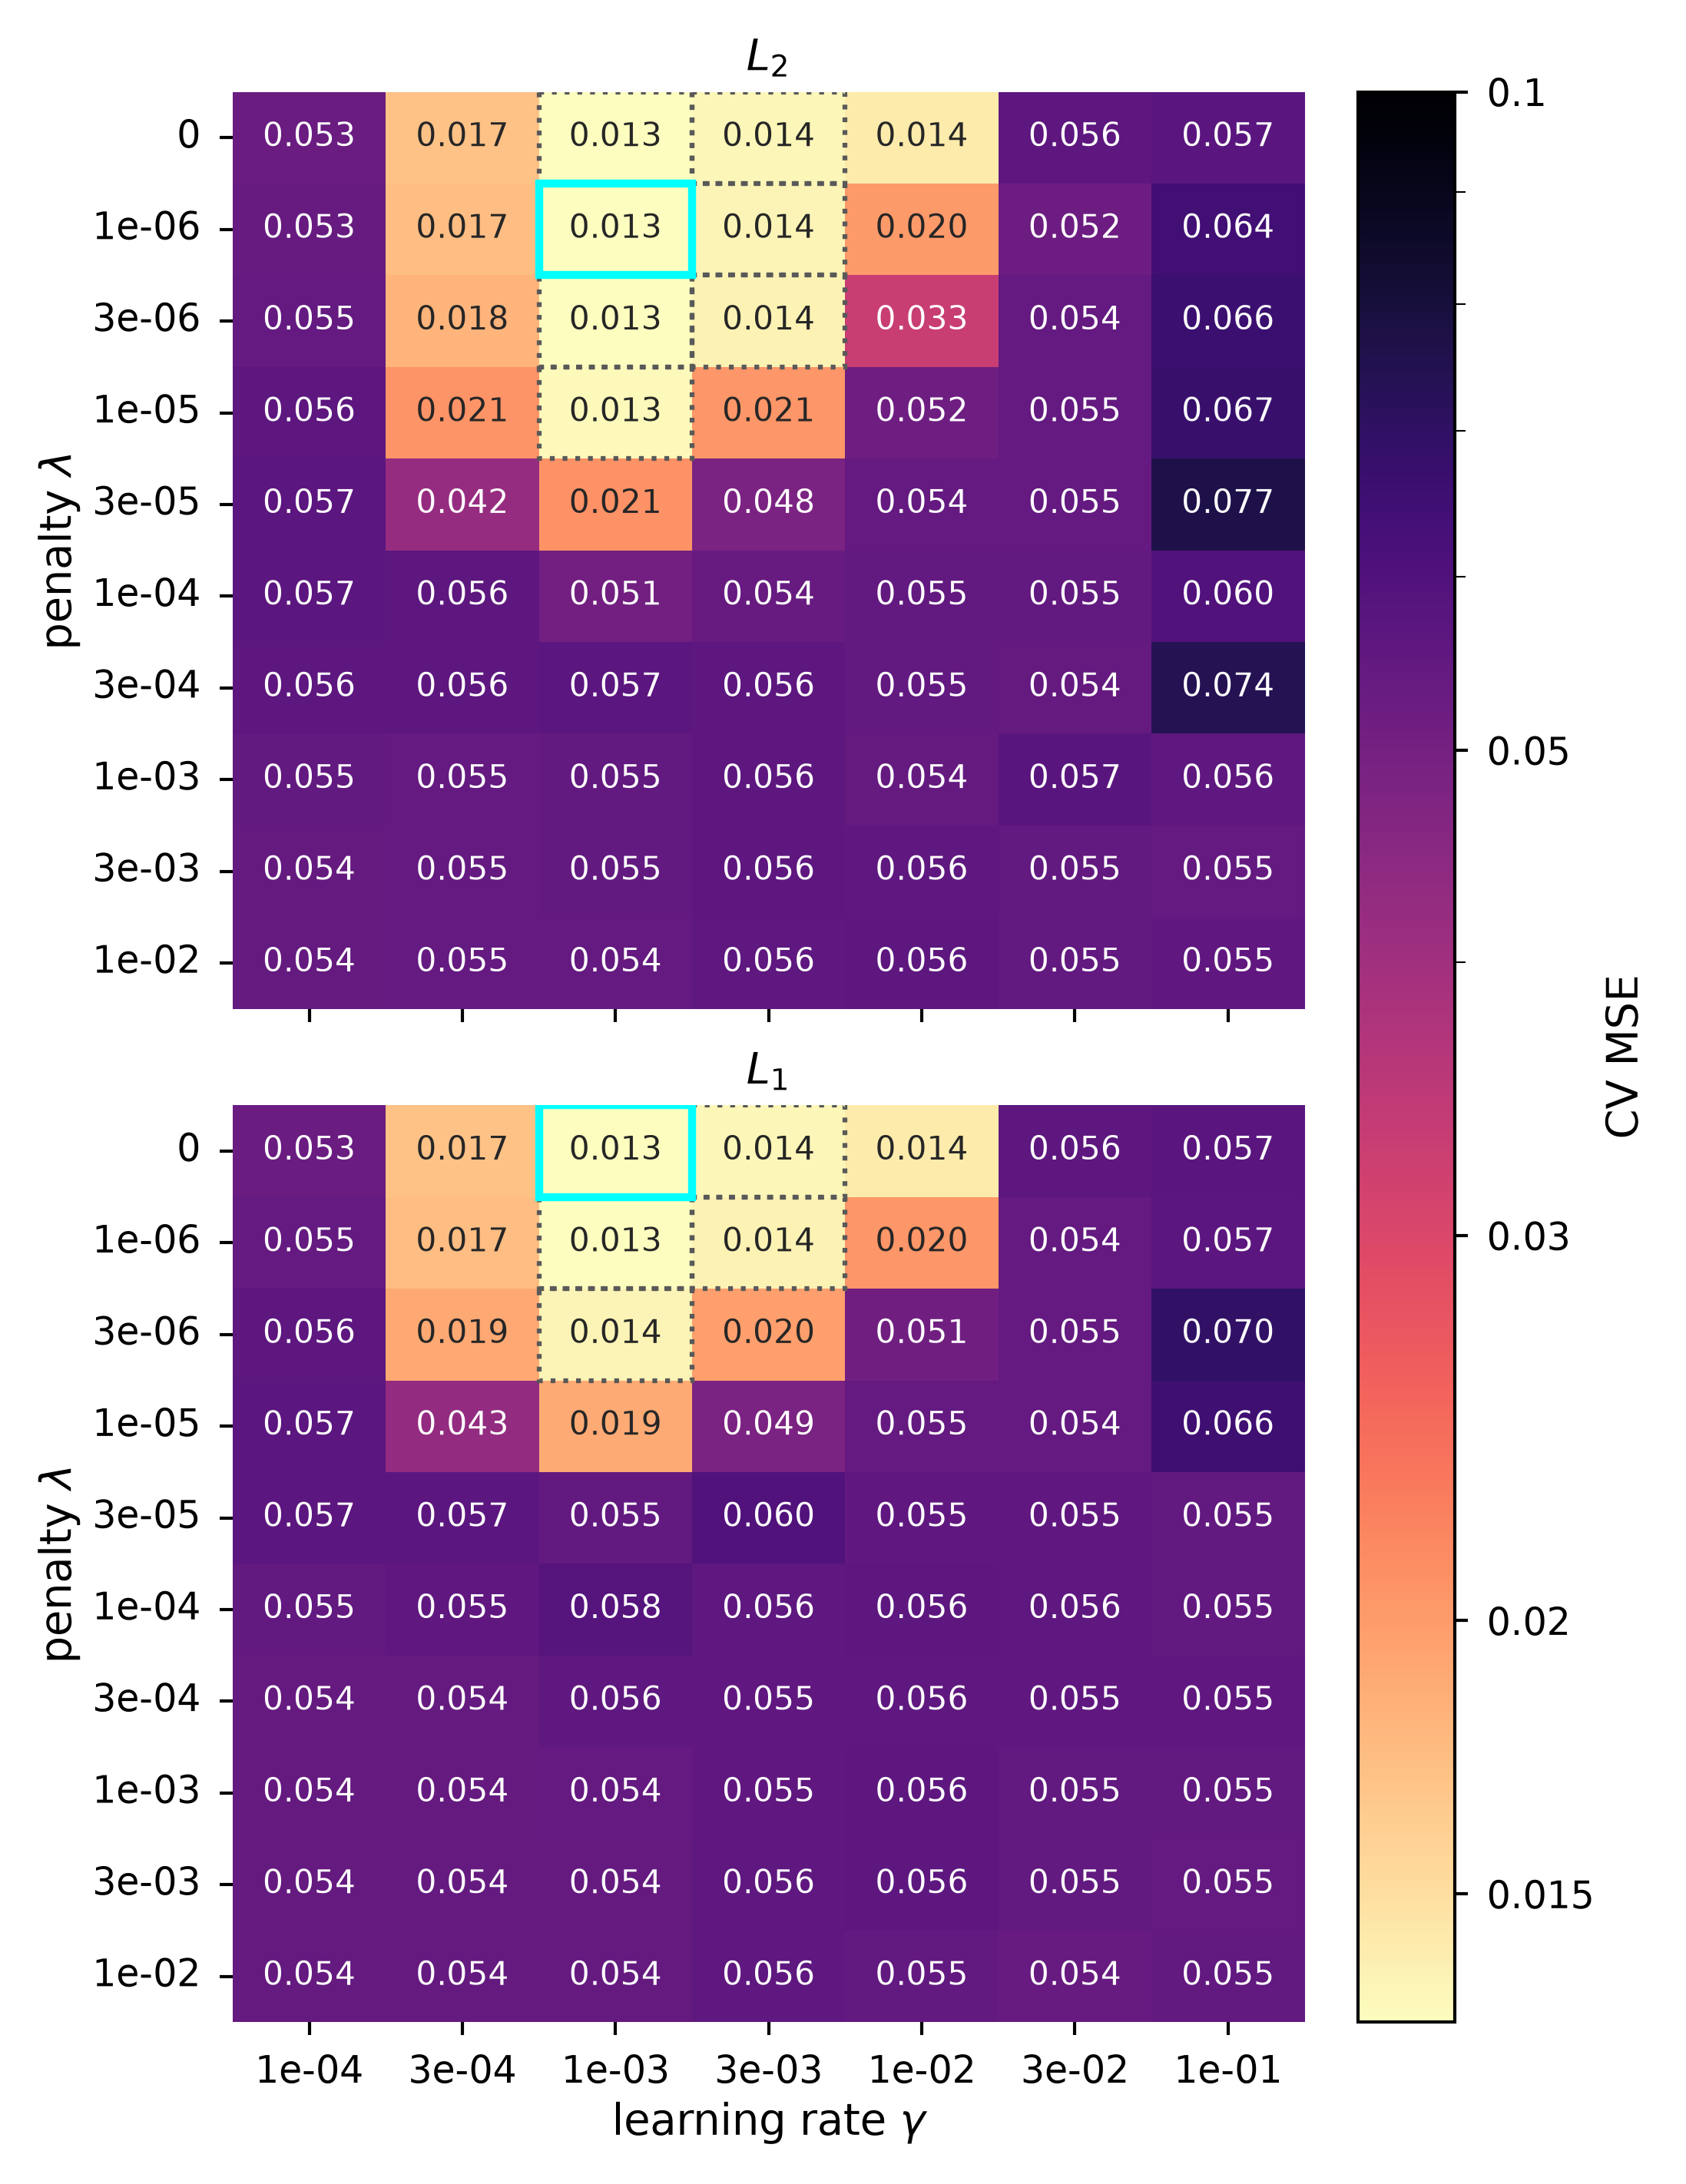

In [130]:
MSE_CAP = 0.1   # above this, the network is no better than predicting the mean
val_mean_d, val_se_d = cv_mean_and_se(penalty_sweep["val_mse"])
best_overall, best_penalized = {}, {}

fig, axes = plt.subplots(2, 1, figsize=(COL * 1.2, 5.6), sharex=True)
for n, (ax, norm) in enumerate(zip(axes, NORMS)):
    grid = val_mean_d[n]
    labels = np.where(np.isnan(grid), "", np.where(grid < MSE_CAP, np.char.mod("%.3f", grid), ">0.1"))
    sns.heatmap(grid, ax=ax, cmap="magma_r", norm=LogNorm(np.nanmin(val_mean_d), MSE_CAP),
                annot=labels, annot_kws={"fontsize": 6}, fmt="", cbar=False,
                xticklabels=[f"{g:.0e}" for g in GAMMAS_D],
                yticklabels=[f"{l:.0e}" if l > 0 else "0" for l in LAMBDAS])
    ax.set(title=rf"$L_{norm[1]}$", ylabel=r"penalty $\lambda$")
    ax.tick_params(axis="y", rotation=0)
    
    best_overall[norm] = u.best_cell(grid, lam=LAMBDAS, gamma=GAMMAS_D)
    best_penalized[norm] = u.best_cell(grid[1:], lam=LAMBDAS[1:], gamma=GAMMAS_D)
    i, j = best_overall[norm]["index"]
    within = grid <= best_overall[norm]["value"] + val_se_d[n][i, j]  # tied with best
    P.heatmap_marks(ax, within, best=(i, j))
    print(f"{norm}: best lambda {best_overall[norm]['lam']:.0e}, "
          f"gamma {best_overall[norm]['gamma']:.0e}, "
          f"CV MSE {best_overall[norm]['value']:.4f} ± {val_se_d[n][i, j]:.4f}, "
          f"{within.sum()} cells within one SE")
axes[-1].set_xlabel(r"learning rate $\gamma$")
ticks = [t for t in (0.01, 0.015, 0.02, 0.03, 0.05, 0.1) if np.nanmin(val_mean_d) <= t <= MSE_CAP]
cbar = fig.colorbar(axes[0].collections[0], ax=axes, label="CV MSE", ticks=ticks)
P.plain_log_ticks(cbar.ax, "y")
fig.savefig(FIGURES_PATH / "D-lambda_gamma.pdf")

# ==============================================================================

# Does the penalty help? Compare fold by fold: (no penalty) - (penalized)
# Positive = penalty helps
best_unpenalized = u.best_cell(val_mean_d[0, 0], gamma=GAMMAS_D)
folds_none = penalty_sweep["val_mse"][0, 0, best_unpenalized["index"][0]]
print()
for n, norm in enumerate(NORMS):
    i, j = best_penalized[norm]["index"]
    d = folds_none - penalty_sweep["val_mse"][n, 1 + i, j]
    print(f"{norm}: no penalty - penalized = {d.mean():+.4f} ± {se(d):.4f} (paired over folds)")

Comparison with Project 1: Ridge and Lasso chosen by CV vs. the best penalized
networks, all evaluated once on the test set

model                  degree   lambda           CV MSE            test MSE     test, minus OLS
OLS (Project 1)            12  0.0e+00    0.0141 ± 0.0016    0.0093      0.0000 ± 0.0000
Ridge (Project 1)          12  1.9e-10    0.0141 ± 0.0016    0.0092     -0.0000 ± 0.0000
Lasso (Project 1)          12  8.0e-07    0.0161 ± 0.0022    0.0081     -0.0012 ± 0.0015
NN, no penalty                 0.0e+00    0.0131 ± 0.0008    0.0122      0.0029 ± 0.0021
NN, L2                         1.0e-06    0.0131 ± 0.0008    0.0121      0.0028 ± 0.0021
NN, L1                         1.0e-06    0.0132 ± 0.0008    0.0124      0.0032 ± 0.0021


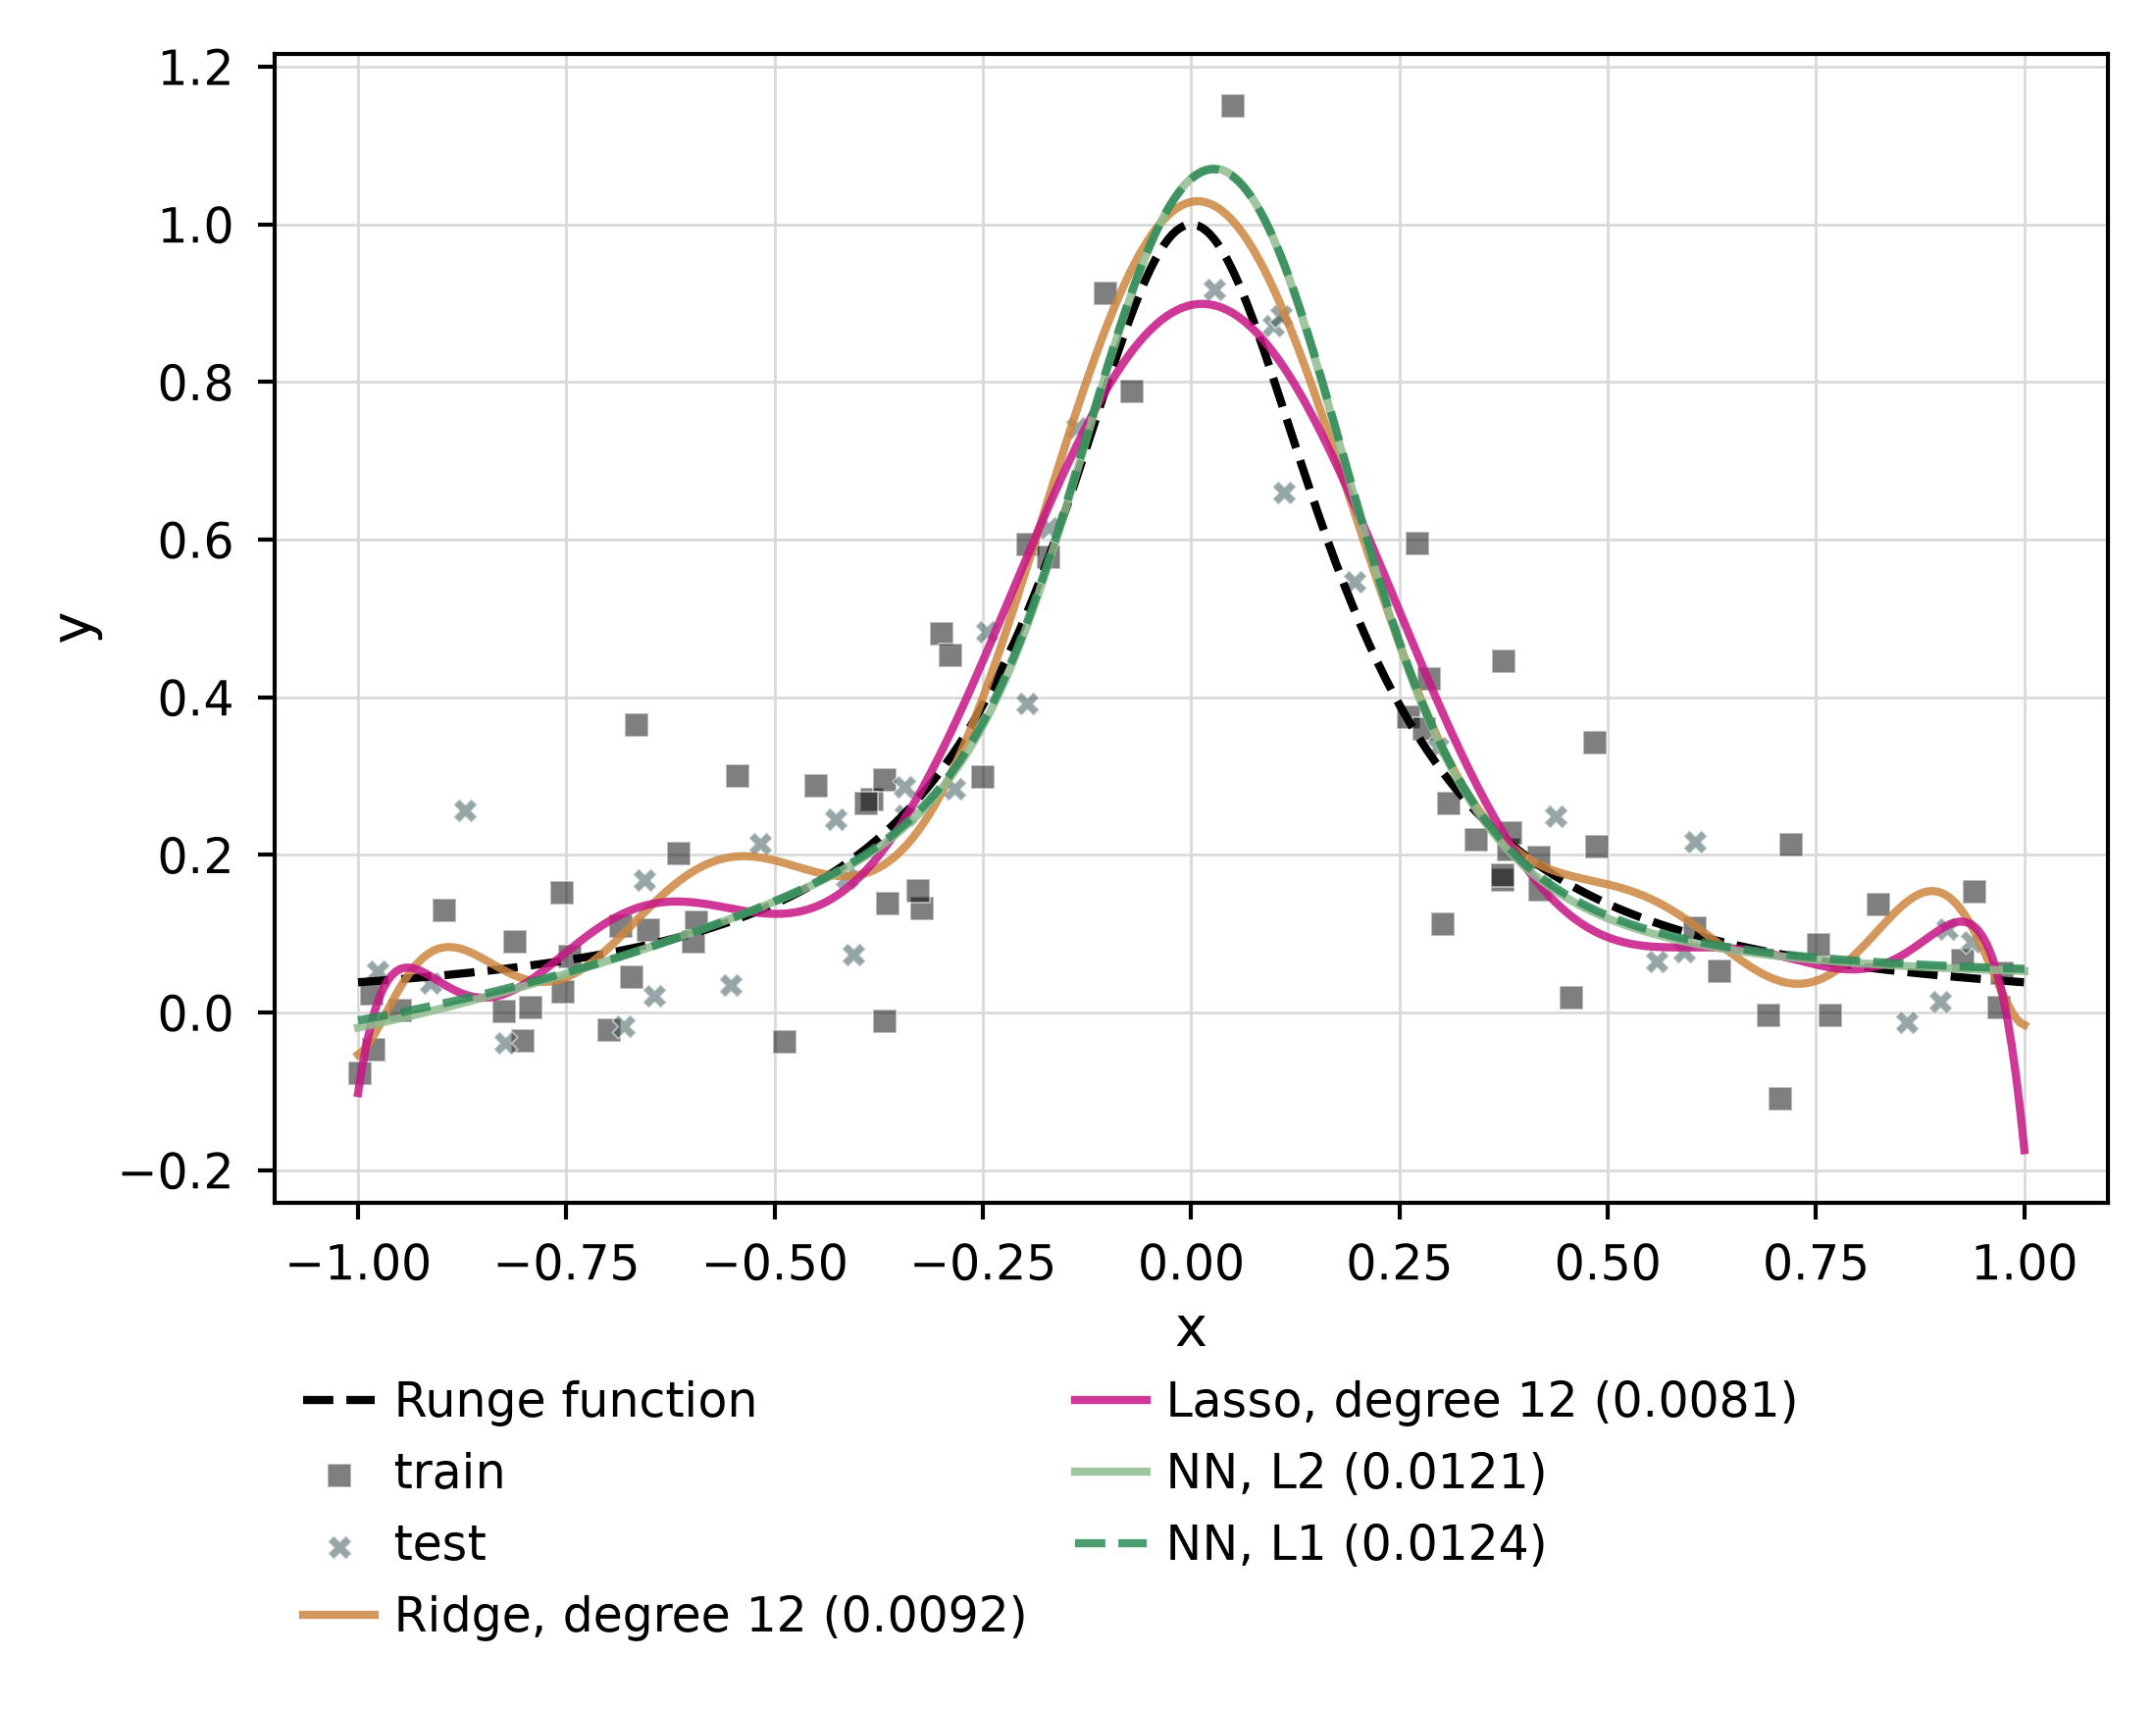

In [150]:
ALPHAS_P1 = np.logspace(-8, 0, 6)
degrees = np.arange(1, MAX_DEGREE + 1)

# Our cost is MSE (a mean) + lambda * penalty. sklearn writes the cost differently, so alpha != lambda
#       Ridge: ||y - Xw||^2 + alpha ||w||^2         -> lambda = alpha / n_fit
#       Lasso: ||y - Xw||^2 / (2 n) + alpha ||w||_1 -> lambda = 2 * alpha
N_FIT = len(runge_y_train) * (K_FOLDS - 1) / K_FOLDS  # training points per CV fold
LAMBDA_EQ = {"OLS": lambda a: 0.0, "Ridge": lambda a: a / N_FIT, "Lasso": lambda a: 2 * a}

def compute_ridge_lasso_cv():
    out = {}
    for key, Model, extra in [("ridge", Ridge, {}), ("lasso", Lasso, {"max_iter": 100_000})]:
        mse = np.zeros((MAX_DEGREE, len(ALPHAS_P1)))
        se = np.zeros_like(mse)
        for j, alpha in enumerate(ALPHAS_P1):
            mse[:, j], se[:, j] = u.k_fold_degrees(runge_X_train, runge_y_train, K_FOLDS,
                                                   Model(alpha=alpha, **extra),
                                                   maxdegree=MAX_DEGREE, return_se=True)
        out[key], out[key + "_se"] = mse, se
    return out

ridge_lasso_cv = u.cached_arrays(RESULTS_PATH / "d_ridge_lasso_cv.npz", compute_ridge_lasso_cv, RERUN)

# For each method: pick (degree, alpha) by CV, refit on training set, evaluate once on test set
sq_err_ols = (runge_y_test - ols_model.predict(runge_X_test)) ** 2  # squared error per test point
benchmarks = {"OLS": {"degree": best_degree, "lam": 0.0, "model": ols_model, 
                      "cv": best_ols["value"], "cv_se": ols_se, "sq_err": sq_err_ols}}
for name, key, Model, extra in [("Ridge", "ridge", Ridge, {}), ("Lasso", "lasso", Lasso, {"max_iter": 100_000})]:
    best = u.best_cell(ridge_lasso_cv[key], degree=degrees, alpha=ALPHAS_P1)
    model = u.poly_model(int(best["degree"]), Model(alpha=best["alpha"], **extra)).fit(runge_X_train, runge_y_train)
    benchmarks[name] = {"degree": int(best["degree"]), "lam": LAMBDA_EQ[name](best["alpha"]),
                        "model": model, "cv": best["value"], "cv_se": ridge_lasso_cv[key + "_se"][best["index"]],
                        "sq_err": (runge_y_test - model.predict(runge_X_test)) ** 2}

# ==============================================================================

def refit_nn(lam1, lam2, gamma, seeds=SEEDS_D):
    '''Refit on the whole training set for several initializations, then look at the test set'''
    models = [make_nn(hidden=(ARCH_WIDTH,) * ARCH_DEPTH, activation=ARCH_ACTIVATION,
                      method=best_method, gamma=gamma, lmbd1=lam1, lmbd2=lam2,
                      epochs=EPOCHS_D, batch_size=best_batch_size, seed=s,
                      penalize_bias=PENALIZE_BIAS).fit(runge_X_train, runge_y_train) for s in seeds]
    sq_errs = np.array([(runge_y_test - m.predict(runge_X_test)) ** 2 for m in models]) # (seeds, n_test)
    return {"model": models[0], "sq_err": sq_errs.mean(axis=0), "init_std": sq_errs.mean(axis=1).std()}


def cv_at(n, i, j):
    '''CV mean and SE of cell (lambda index i, gamma index j) in the penalty sweep for norm n'''
    return val_mean_d[n, i, j], val_se_d[n, i, j]

pen = {norm: best_penalized[norm]["index"] for norm in NORMS}
nn_settings = {             # name: (lambda_1, lambda_2, gamma, (CV mean, CV SE))
    "NN, no penalty": (0.0, 0.0, best_unpenalized["gamma"], cv_at(0, 0, best_unpenalized["index"][0])),
    "NN, L2": (0.0, best_penalized["l2"]["lam"], best_penalized["l2"]["gamma"], cv_at(0, 1 + pen["l2"][0], pen["l2"][1])),
    "NN, L1": (best_penalized["l1"]["lam"], 0.0, best_penalized["l1"]["gamma"], cv_at(1, 1 + pen["l1"][0], pen["l1"][1]))}
nn_results = {name: refit_nn(l1, l2, g) for name, (l1, l2, g, _) in nn_settings.items()}

print(f"{'model':<22}{'degree':>7}{'lambda':>9}{'CV MSE':>17}{'test MSE':>20}{'test, minus OLS':>20}")
for name, info in benchmarks.items():
    diff, diff_se = paired_diff(info["sq_err"], sq_err_ols)
    print(f"{name + ' (Project 1)':<22}{info['degree']:>7}{info['lam']:>9.1e}{info['cv']:>10.4f} ± {info['cv_se']:.4f}"
          f"{info['sq_err'].mean():10.4f}{diff:>12.4f} ± {diff_se:.4f}")
for name, (l1, l2, _, (cv, cv_se)) in nn_settings.items():
    res = nn_results[name]
    diff, diff_se = paired_diff(res["sq_err"], sq_err_ols)
    print(f"{name:<22}{'':>7}{max(l1, l2):>9.1e}{cv:>10.4f} ± {cv_se:.4f}"
          f"{res['sq_err'].mean():>10.4f}{diff:>12.4f} ± {diff_se:.4f}")
    
# ==============================================================================

PEN_COLORS = {"Ridge": "peru", "Lasso": "mediumvioletred", "NN, L2": "darkseagreen", "NN, L1": "seagreen"}
PEN_STYLES = {"Ridge": "-", "Lasso": "-", "NN, L2": "-", "NN, L1": "--"}

fig, ax = plt.subplots(figsize=(COL * 1.2, 3.4))
ax.plot(grid_x, runge_true_curve, "k--", label="Runge function")
sns.scatterplot(x=runge_x_train, y=runge_y_train, color="k", alpha=0.5, marker="s", label="train", ax=ax)
sns.scatterplot(x=runge_x_test, y=runge_y_test, color="darkslategray", alpha=0.5, marker="X", label="test", ax=ax)
for name in ("Ridge", "Lasso"):
    info = benchmarks[name]
    sns.lineplot(x=grid_x, y=info["model"].predict(grid_x.reshape(-1, 1)),
                 color=PEN_COLORS[name], ls=PEN_STYLES[name], alpha=0.85, 
                 label=f"{name}, degree {info['degree']} ({info['sq_err'].mean():.4f})", ax=ax)
for name in ("NN, L2", "NN, L1"):
    sns.lineplot(x=grid_x, y=nn_results[name]["model"].predict(to_column(grid_x)).ravel(),
                 color=PEN_COLORS[name], ls=PEN_STYLES[name], alpha=0.85,
                 label=f"{name} ({nn_results[name]['sq_err'].mean():.4f})", ax=ax)
ax.set(xlabel="x", ylabel="y")
ax.legend(loc="upper left", bbox_to_anchor=(0.0, -0.13), ncol=2)
fig.savefig(FIGURES_PATH / "D-NN_vs_Ridge_Lasso.pdf")

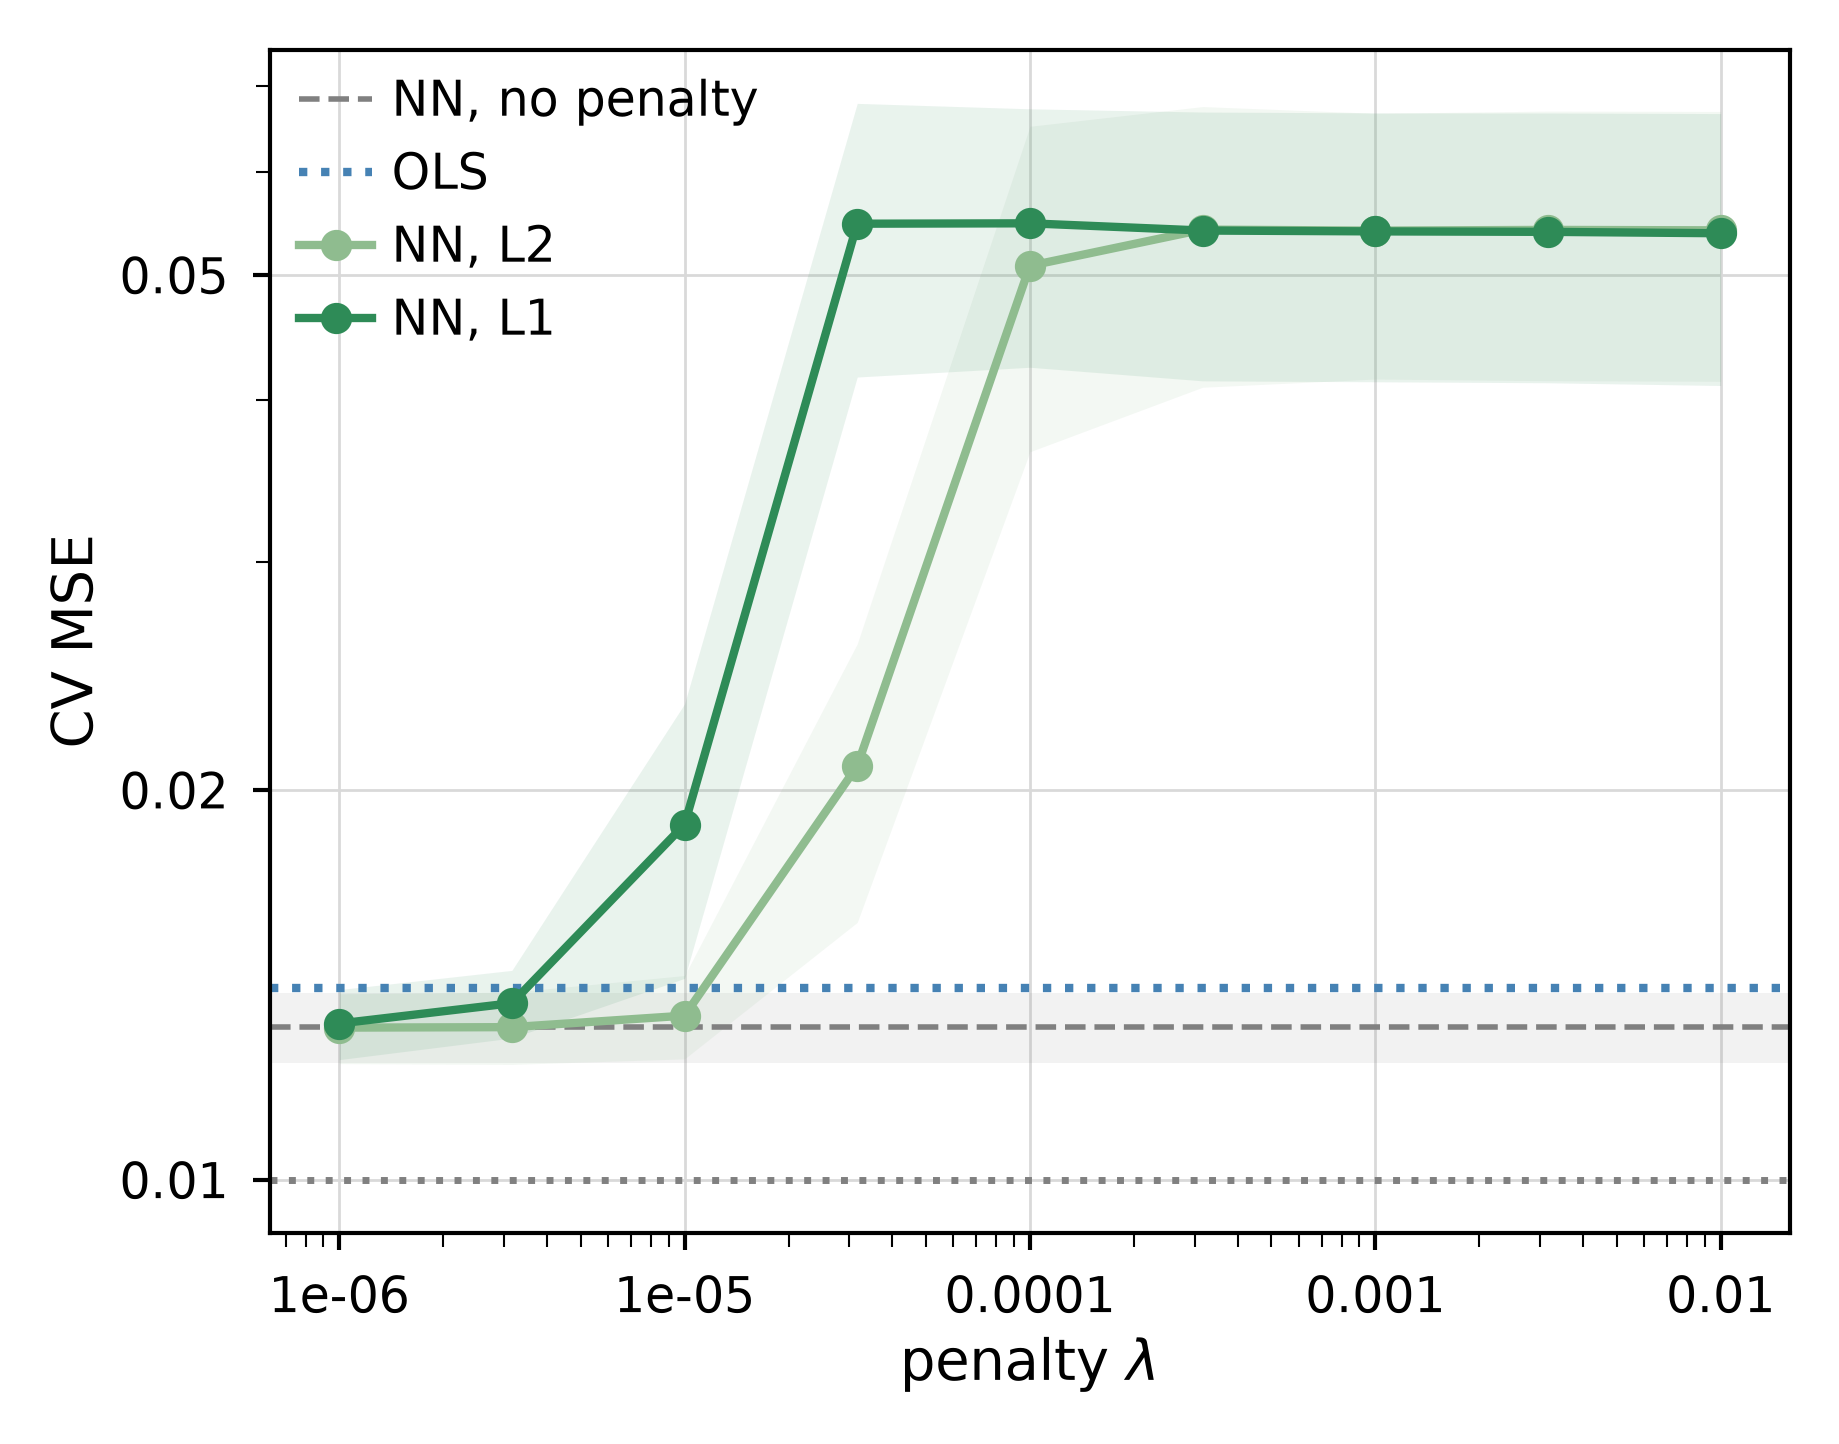

In [158]:
def min_over_last(mean, se):
    '''Smallest mean along the last axis and the SE at that position'''
    idx = np.argmin(np.where(np.isfinite(mean), mean, np.inf), axis=-1)[..., None]
    return np.take_along_axis(mean, idx, -1)[..., 0], np.take_along_axis(se, idx, -1)[..., 0]

nn_curve = {norm: min_over_last(val_mean_d[n, 1:], val_se_d[n, 1:]) for n, norm in enumerate(NORMS)}   # best gamma per lambda
p1_curve = {name: min_over_last(ridge_lasso_cv[key].T, ridge_lasso_cv[key + "_se"].T)
            for name, key in [("Ridge", "ridge"), ("Lasso", "lasso")]}
lam_p1 = {name: np.array([LAMBDA_EQ[name](a) for a in ALPHAS_P1]) for name in ("Ridge", "Lasso")}
none_mean, none_se = cv_at(0, 0, best_unpenalized["index"][0])

fig, ax = plt.subplots(figsize=(COL, 2.8))
ax.axhline(none_mean, color="gray", ls="--", lw=0.8, label="NN, no penalty")
ax.axhspan(none_mean - none_se, none_mean + none_se, color="gray", alpha=0.1, lw=0)
ax.axhline(best_ols["value"], color="steelblue", ls=":", lw=1.2, label="OLS")
for norm, name in zip(NORMS, ["NN, L2", "NN, L1"]):
    P.band(ax, LAMBDAS[1:], *nn_curve[norm], color=PEN_COLORS[name], marker="o", label=name)
P.noise_floor(ax, label=False)
ax.set(xscale="log", yscale="log", xlabel=r"penalty $\lambda$", ylabel="CV MSE")
P.plain_log_ticks(ax, "x"); P.plain_log_ticks(ax, "y"); ax.set_yticks([0.01, 0.02, 0.05])
ax.legend(loc="upper left")
fig.savefig(FIGURES_PATH / "D-lambda_curve.pdf")

<div style="background-color:#F0DAE2; color:#823C55; border-radius:12px; padding:16px; width:90%;">

**Part e)** Classification analysis

</div>

Load mnist dataset, scaled and centered. Split into train, val, and test sets.

In [ ]:
x_train, y_train, x_test, y_test = load_mnist(DATA_PATH)
x_fit, x_val, y_fit, y_val = train_val_split(x_train, y_train, val_size=0.25, seed=SEED, stratify=False)
Y_fit, Y_val, Y_train = one_hot(y_fit), one_hot(y_val), one_hot(y_train)    # train needs (n, 10)

print("Train: ", x_fit.shape, y_fit.shape)
print("Val:   ", x_val.shape, y_val.shape)
print("Test:  ", x_test.shape, y_test.shape)

Train:  (45000, 784) (45000,)
Val:    (15000, 784) (15000,)
Test:   (10000, 784) (10000,)


Logistic regression.

To save the model from the run, we need to save it in form of $W$ and $b$, such
that instead of predicting with `model.predict(x_test)`, we instead predict the
traditional way: $y_\mathrm{pred}=x_\mathrm{test}\cdot \boldsymbol{W}^\top + b$.

This has been tested against saving the model directly, and returns the same
accuracy.

In [ ]:
def compute_logistic_regression():
    model = LogisticRegression(solver="saga", max_iter=1000, random_state=42)
    model.fit(x_train, y_train)
    return {"coef": model.coef_, "intercept": model.intercept_} # shapes (10, 784) and (10,)

logreg = u.cached_arrays(RESULTS_PATH / "e_logreg_params.npz", compute_logistic_regression, RERUN)

logreg_scores = x_test @ logreg["coef"].T + logreg["intercept"]
logreg_predictions = np.argmax(logreg_scores, axis=1)
logreg_accuracy = accuracy(y_test, logreg_predictions)
print(f"Model Accuracy: {logreg_accuracy:.4f}")

Model Accuracy: 0.9257


Train one classifier on the fit set. Returns the network and its per-epoch history

In [ ]:
def accuracy_metric(net, X, Y_onehot):
    '''Accuracy of a net on X. Targets are one-hot because train needs them that way.'''
    return accuracy(np.argmax(Y_onehot, axis=1), np.argmax(net.predict(X), axis=1))


def run_one_mnist(activation, hidden, lam, gamma, epochs, batch_size, seed, method="adam"):
    '''
    activation : hidden-layer activation, e.g. "relu"
    hidden     : hidden layer sizes, e.g. (128, 64); () means no hidden layer (= logistic regression)
    lam        : (lambda1, lambda2) for the L1 and L2 penalties
    '''
    l1, l2 = lam
    sizes = [x_fit.shape[1], *hidden, 10]       # 10 output nodes
    acts = [activation] * len(hidden) + ["softmax"]
    net = NeuralNetwork(sizes, acts, "cross_entropy", lmbd1=l1, lmbd2=l2, seed=seed)
    history = train(net, x_fit, Y_fit, method=method, gamma=gamma, epochs=epochs,
                    batch_size=batch_size, seed=seed, X_val=x_val, Y_val=Y_val,
                    metric=accuracy_metric)
    return net, history

Learning curves: No hidden layer (= logistic regression) vs. one hidden layer

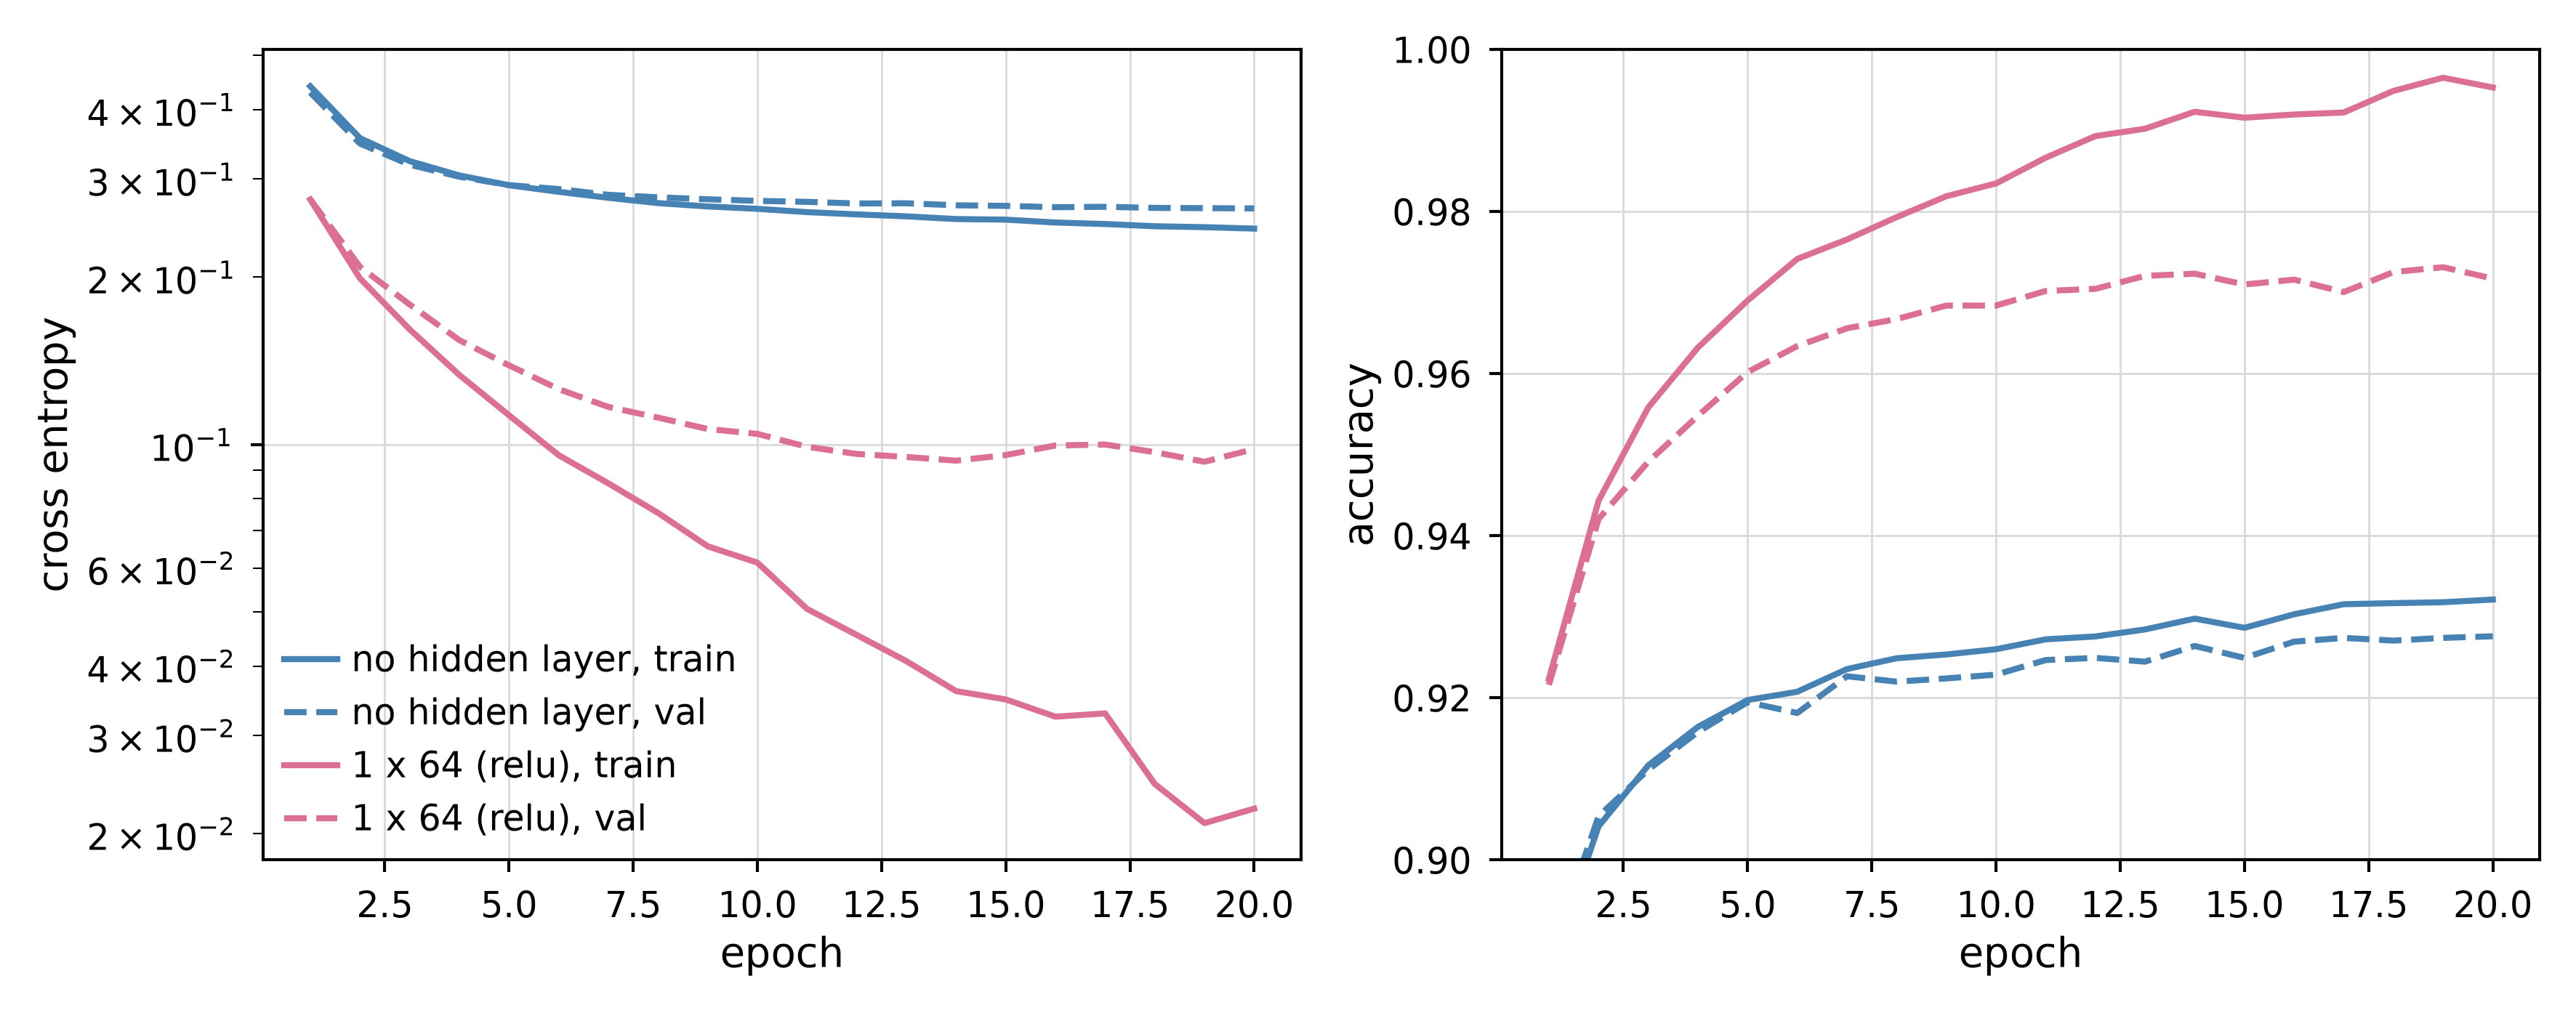

In [ ]:
EPOCHS_BASE, BATCH_E = 20, 128
BASELINES = {"no hidden layer": ((), "relu"),   # label: (hidden, activation)
             "1 x 64 (relu)": ((64,), "relu")}

def compute_baseline_curves():
    names = ("train_cost", "val_cost", "train_accuracy", "val_accuracy")
    curves = {name: np.zeros((len(BASELINES), EPOCHS_BASE)) for name in names}
    for i, (hidden, activation) in enumerate(BASELINES.values()):
        _, history = run_one_mnist(activation, hidden, (0.0, 0.0), 1e-3, 
                                   EPOCHS_BASE, BATCH_E, SEED)
        curves["train_cost"][i], curves["val_cost"][i] = history["train_cost"], history["val_cost"]
        curves["train_accuracy"][i], curves["val_accuracy"][i] = history["train_metric"], history["val_metric"]
    return curves

baseline = u.cached_arrays(RESULTS_PATH / "e_baseline_curves.npz", compute_baseline_curves, RERUN)

epochs = np.arange(1, EPOCHS_BASE + 1)
colors = ["steelblue", "palevioletred"]
fig, axes = plt.subplots(1, 2, figsize=(7, 2.7))
for i, label in enumerate(BASELINES):
    color = colors[i]
    for split, linestyle in (("train", "-"), ("val", "--")):
        axes[0].plot(epochs, baseline[f"{split}_cost"][i], linestyle, color=color, label=f"{label}, {split}")
        axes[1].plot(epochs, baseline[f"{split}_accuracy"][i], linestyle, color=color, label=f"{label}, {split}")
axes[0].set(xlabel="epoch", ylabel="cross entropy", yscale="log")
axes[1].set(xlabel="epoch", ylabel="accuracy", ylim=(0.9, 1.0))
axes[0].legend(loc="lower left")
fig.savefig(FIGURES_PATH / "E-baseline_curves.pdf")

Validation accuracy per optimizer across learning rates on a reference network
(1 x 64, relu, no penalty). Mean and std of 3 seeds

rmsprop, learning rate 1.9e-03


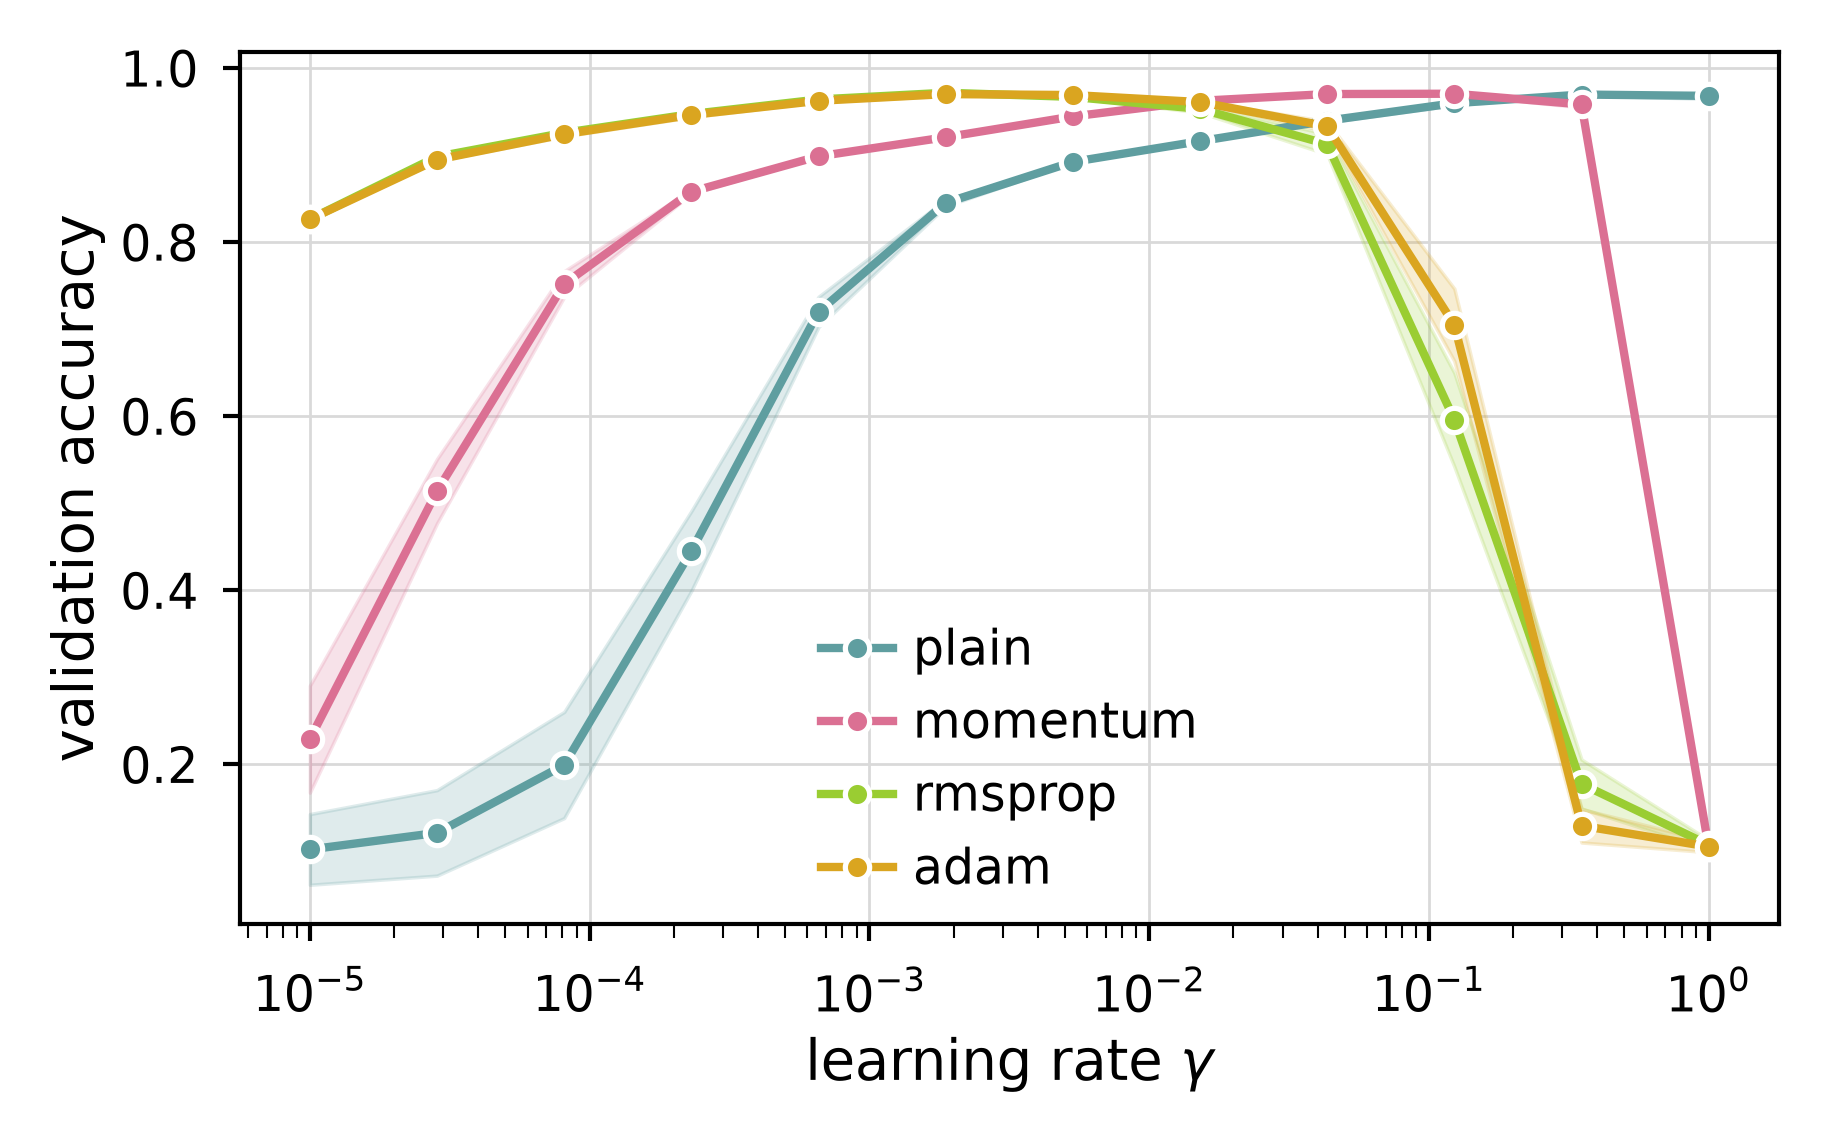

In [ ]:
SEEDS_E, EPOCHS_E = [0, 1, 2], 10
REF_ACTIVATION, REF_HIDDEN = "relu", (64,)
METHODS_E = ["plain", "momentum", "rmsprop", "adam"]
GAMMAS_OPT = np.geomspace(1e-5, 1.0, 12)    # wide: diverged run are fine

def compute_optimizer_sweep():
    shape = (len(METHODS_E), len(GAMMAS_OPT), len(SEEDS_E))
    val_accuracy = np.full(shape, np.nan)
    for m, g, s in np.ndindex(shape):
        with np.errstate(all="ignore"):
            _, history = run_one_mnist(REF_ACTIVATION, REF_HIDDEN, (0.0, 0.0),
                                       GAMMAS_OPT[g], EPOCHS_E, BATCH_E,
                                       seed=SEEDS_E[s], method=METHODS_E[m])
        val_accuracy[m, g, s] = history["val_metric"][-1]
    return {"val_accuracy": val_accuracy}

optimizer = u.cached_arrays(RESULTS_PATH / "e_optimizer.npz", compute_optimizer_sweep, RERUN)
optimizer_accuracy_mean = optimizer["val_accuracy"].mean(axis=-1)
optimizer_accuracy_std = optimizer["val_accuracy"].std(axis=-1)

best_optimizer = u.best_cell(optimizer_accuracy_mean, smallest=False,
                             method=METHODS_E, gamma=GAMMAS_OPT)
OPT_METHOD, OPT_GAMMA = best_optimizer["method"], best_optimizer["gamma"]
print(f"{OPT_METHOD}, learning rate {OPT_GAMMA:.1e}")

fig, ax = plt.subplots(figsize=(COL, 2.2))
colors = ["cadetblue", "palevioletred", "yellowgreen", "goldenrod"]
for m, (method, color) in enumerate(zip(METHODS_E, colors)):
    ax.fill_between(GAMMAS_OPT, optimizer_accuracy_mean[m] - optimizer_accuracy_std[m],
                    optimizer_accuracy_mean[m] + optimizer_accuracy_std[m],
                    color=color, alpha=0.2)
    sns.lineplot(x=GAMMAS_OPT, y=optimizer_accuracy_mean[m], marker="o", color=color,
                 label=method, ax=ax)
ax.set(xscale="log", xlabel=r"learning rate $\gamma$", ylabel="validation accuracy")
ax.legend()
fig.savefig(FIGURES_PATH / "E-optimizers.pdf")

Validation accuracy over depth and width. Every cell gets its best $\gamma$ from
a small grid around the optimizer's, so they're all judged at their own learning rate.

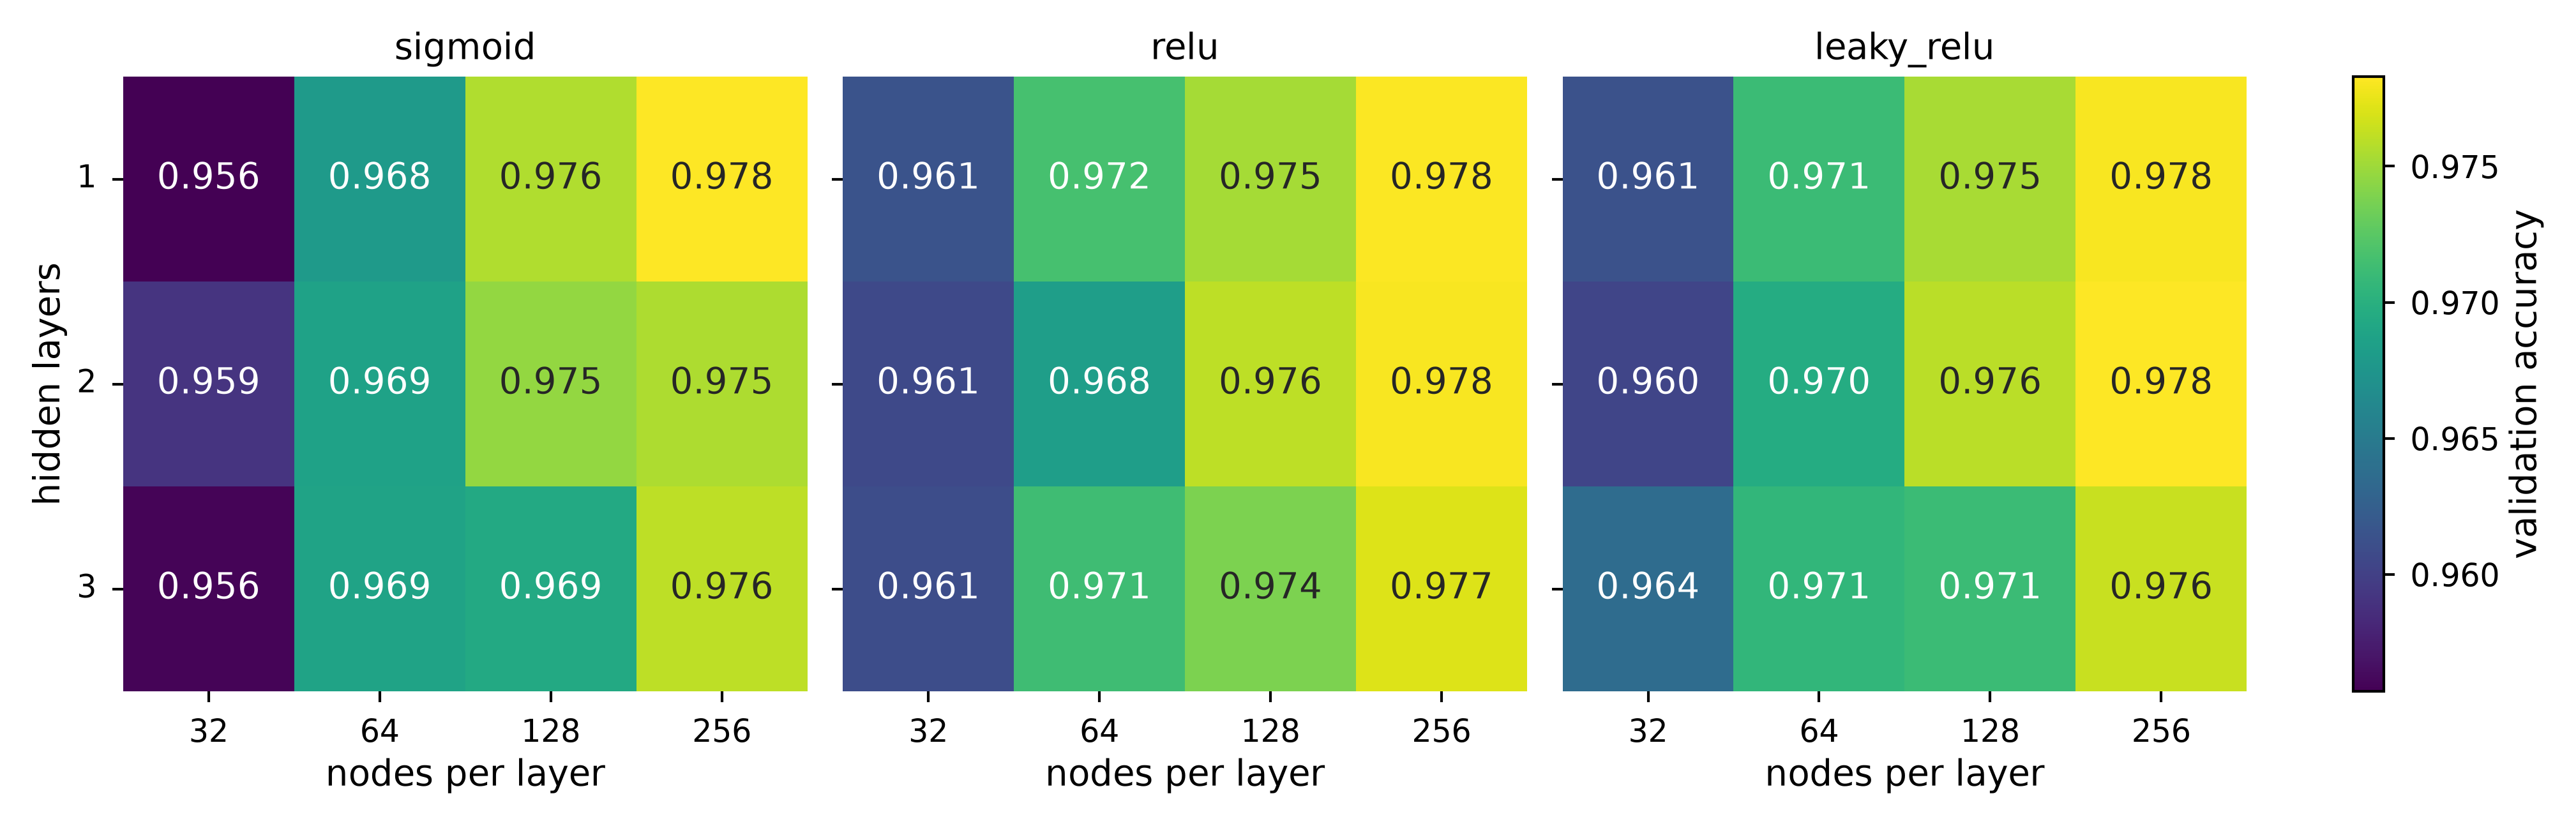

In [ ]:
ACTIVATIONS_E = ["sigmoid", "relu", "leaky_relu"]
DEPTHS_E = [1, 2, 3]
WIDTHS_E = [32, 64, 128, 256]
GAMMAS_ARCH = OPT_GAMMA * np.array([1/3, 1, 3])

def compute_architecture_sweep():
    shape = (len(ACTIVATIONS_E), len(DEPTHS_E), len(WIDTHS_E), len(GAMMAS_ARCH), len(SEEDS_E))
    val_accuracy = np.full(shape, np.nan)
    for a, d, w, g, s in np.ndindex(shape):
        hidden = (WIDTHS_E[w],) * DEPTHS_E[d]
        with np.errstate(all="ignore"):
            _, history = run_one_mnist(ACTIVATIONS_E[a], hidden, (0.0, 0.0),
                                       GAMMAS_ARCH[g], EPOCHS_E, BATCH_E,
                                       SEEDS_E[s], method=OPT_METHOD)
        val_accuracy[a, d, w, g, s] = history["val_metric"][-1]
    return {"val_accuracy": val_accuracy}

architecture = u.cached_arrays(RESULTS_PATH / "e_architectures.npz", compute_architecture_sweep, RERUN)
arch_accuracy_mean = architecture["val_accuracy"].mean(axis=-1)

# Best gamma in every (activation, depth, width) cell
finite = np.where(np.isfinite(arch_accuracy_mean), arch_accuracy_mean, -np.inf)
arch_accuracy_best = finite.max(axis=-1)
arch_accuracy_best[np.isinf(arch_accuracy_best)] = np.nan

best_architecture = {}
fig, axes = plt.subplots(1, 3, figsize=(8, 2.5), sharey=True)
for a, (ax, activation, grid) in enumerate(zip(axes, ACTIVATIONS_E, arch_accuracy_best)):
    sns.heatmap(grid, ax=ax, annot=True, fmt=".3f", cmap="viridis", cbar=False,
                vmin=np.nanmin(arch_accuracy_best), vmax=np.nanmax(arch_accuracy_best),
                xticklabels=WIDTHS_E, yticklabels=DEPTHS_E)
    ax.tick_params(axis="y", rotation=0)
    ax.set(title=activation, xlabel="nodes per layer")
    best_architecture[activation] = u.best_cell(arch_accuracy_mean[a], smallest=False,
                                                depth=DEPTHS_E, width=WIDTHS_E,
                                                gamma=GAMMAS_ARCH)
axes[0].set_ylabel("hidden layers")
fig.colorbar(axes[0].collections[0], ax=axes, label="validation accuracy")
fig.savefig(FIGURES_PATH / "E-architectures.pdf")

Pick out the best architecture from this run

In [ ]:
TOLERANCE = 0.001   # within ~1 standard error of the best cell
best_value = np.nanmax(arch_accuracy_best)

def n_weights(depth, width):
    return 784 * width + (depth - 1) * width * width + 10 * width

candidates = [(n_weights(DEPTHS_E[d], WIDTHS_E[w]), a, d, w)
              for a, d, w in np.ndindex(arch_accuracy_best.shape)
              if arch_accuracy_best[a, d, w] >= best_value - TOLERANCE]
_, a, d, w = min(candidates)        # fewest weights among the near-ties

ARCH_ACTIVATION, ARCH_DEPTH, ARCH_WIDTH = ACTIVATIONS_E[a], DEPTHS_E[d], WIDTHS_E[w]
ARCH_GAMMA = GAMMAS_ARCH[np.argmax(arch_accuracy_mean[a, d, w])]
print(f"{ARCH_ACTIVATION}, {ARCH_DEPTH} hidden layers x {ARCH_WIDTH} nodes, gamma {ARCH_GAMMA:.1e} "
      f"{len(candidates)} cells within {TOLERANCE} of the best")

sigmoid, 1 hidden layers x 256 nodes, gamma 5.6e-03 5 cells within 0.001 of the best


> **LLM note:** The following cell was aided by Claude (Level 2: Snippet).
>
> Per the previous cell's ucertain results, the first 4 lines in the following
> cell were generated by the LLM to get the cell started; the rest of the cell 
> was implemented independently, albeit with a suggestion from the LLM for what to look out for.

leaky_relu, 1 x 256, gamma 1.9e-03


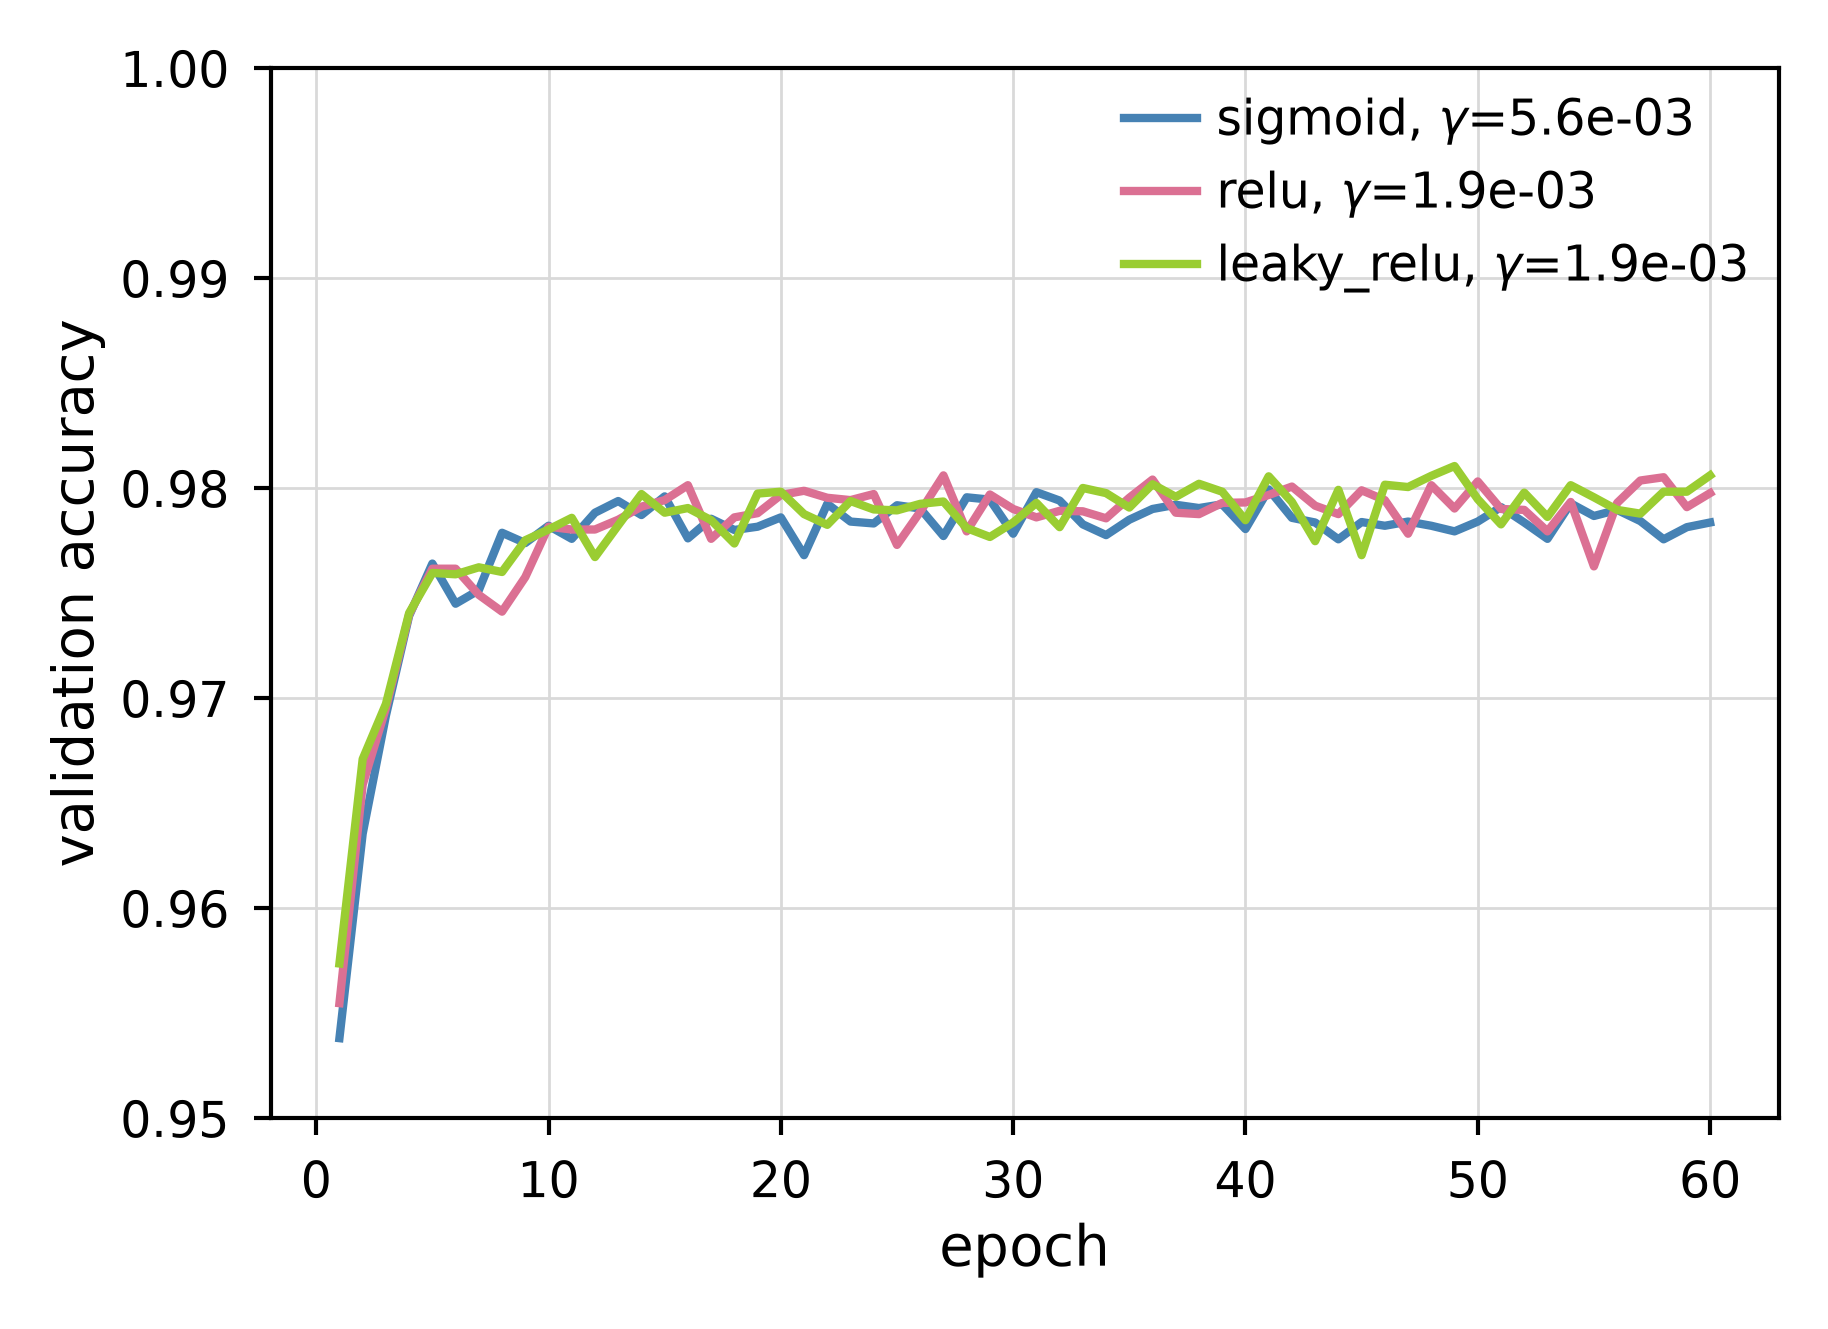

In [ ]:
min_weights = min(candidates)[0]
finalists = [(a, d, w) for n, a, d, w in candidates if n == min_weights]
finalist_gammas = [GAMMAS_ARCH[np.argmax(arch_accuracy_mean[a, d, w])] for a, d, w in finalists]
EPOCHS_LONG = 60

def compute_finalist_curves():
    val_accuracy = np.zeros((len(finalists), len(SEEDS_E), EPOCHS_LONG))
    for f, (a, d, w) in enumerate(finalists):
        for s, seed in enumerate(SEEDS_E):
            _, history = run_one_mnist(ACTIVATIONS_E[a], (WIDTHS_E[w],) * DEPTHS_E[d], (0.0, 0.0),
                                       finalist_gammas[f], EPOCHS_LONG, BATCH_E, seed,
                                       method=OPT_METHOD)
            val_accuracy[f, s] = history["val_metric"]
    return {"val_accuracy": val_accuracy}

finalist_curves = u.cached_arrays(RESULTS_PATH / "finalist_curves.npz", compute_finalist_curves, RERUN)
finalist_mean = finalist_curves["val_accuracy"].mean(axis=1)

fig, ax = plt.subplots()
for f, (a, d, w) in enumerate(finalists):
    sns.lineplot(x=np.arange(1, EPOCHS_LONG + 1), y=finalist_mean[f], ax=ax,
                 label=f"{ACTIVATIONS_E[a]}, $\\gamma$={finalist_gammas[f]:.1e}")
ax.set(xlabel="epoch", ylabel="validation accuracy", ylim=(0.95, 1.0))
fig.savefig(FIGURES_PATH / "E-finalists.pdf")

best_f = int(np.argmax(finalist_mean.max(axis=1)))
a, d, w = finalists[best_f]
ARCH_ACTIVATION, ARCH_DEPTH, ARCH_WIDTH = ACTIVATIONS_E[a], DEPTHS_E[d], WIDTHS_E[w]
ARCH_GAMMA = finalist_gammas[best_f]
print(f"{ARCH_ACTIVATION}, {ARCH_DEPTH} x {ARCH_WIDTH}, gamma {ARCH_GAMMA:.1e}")

Batch size x $\gamma$ sweep

batch size 256, gamma 1.9e-03, val acc 0.9779


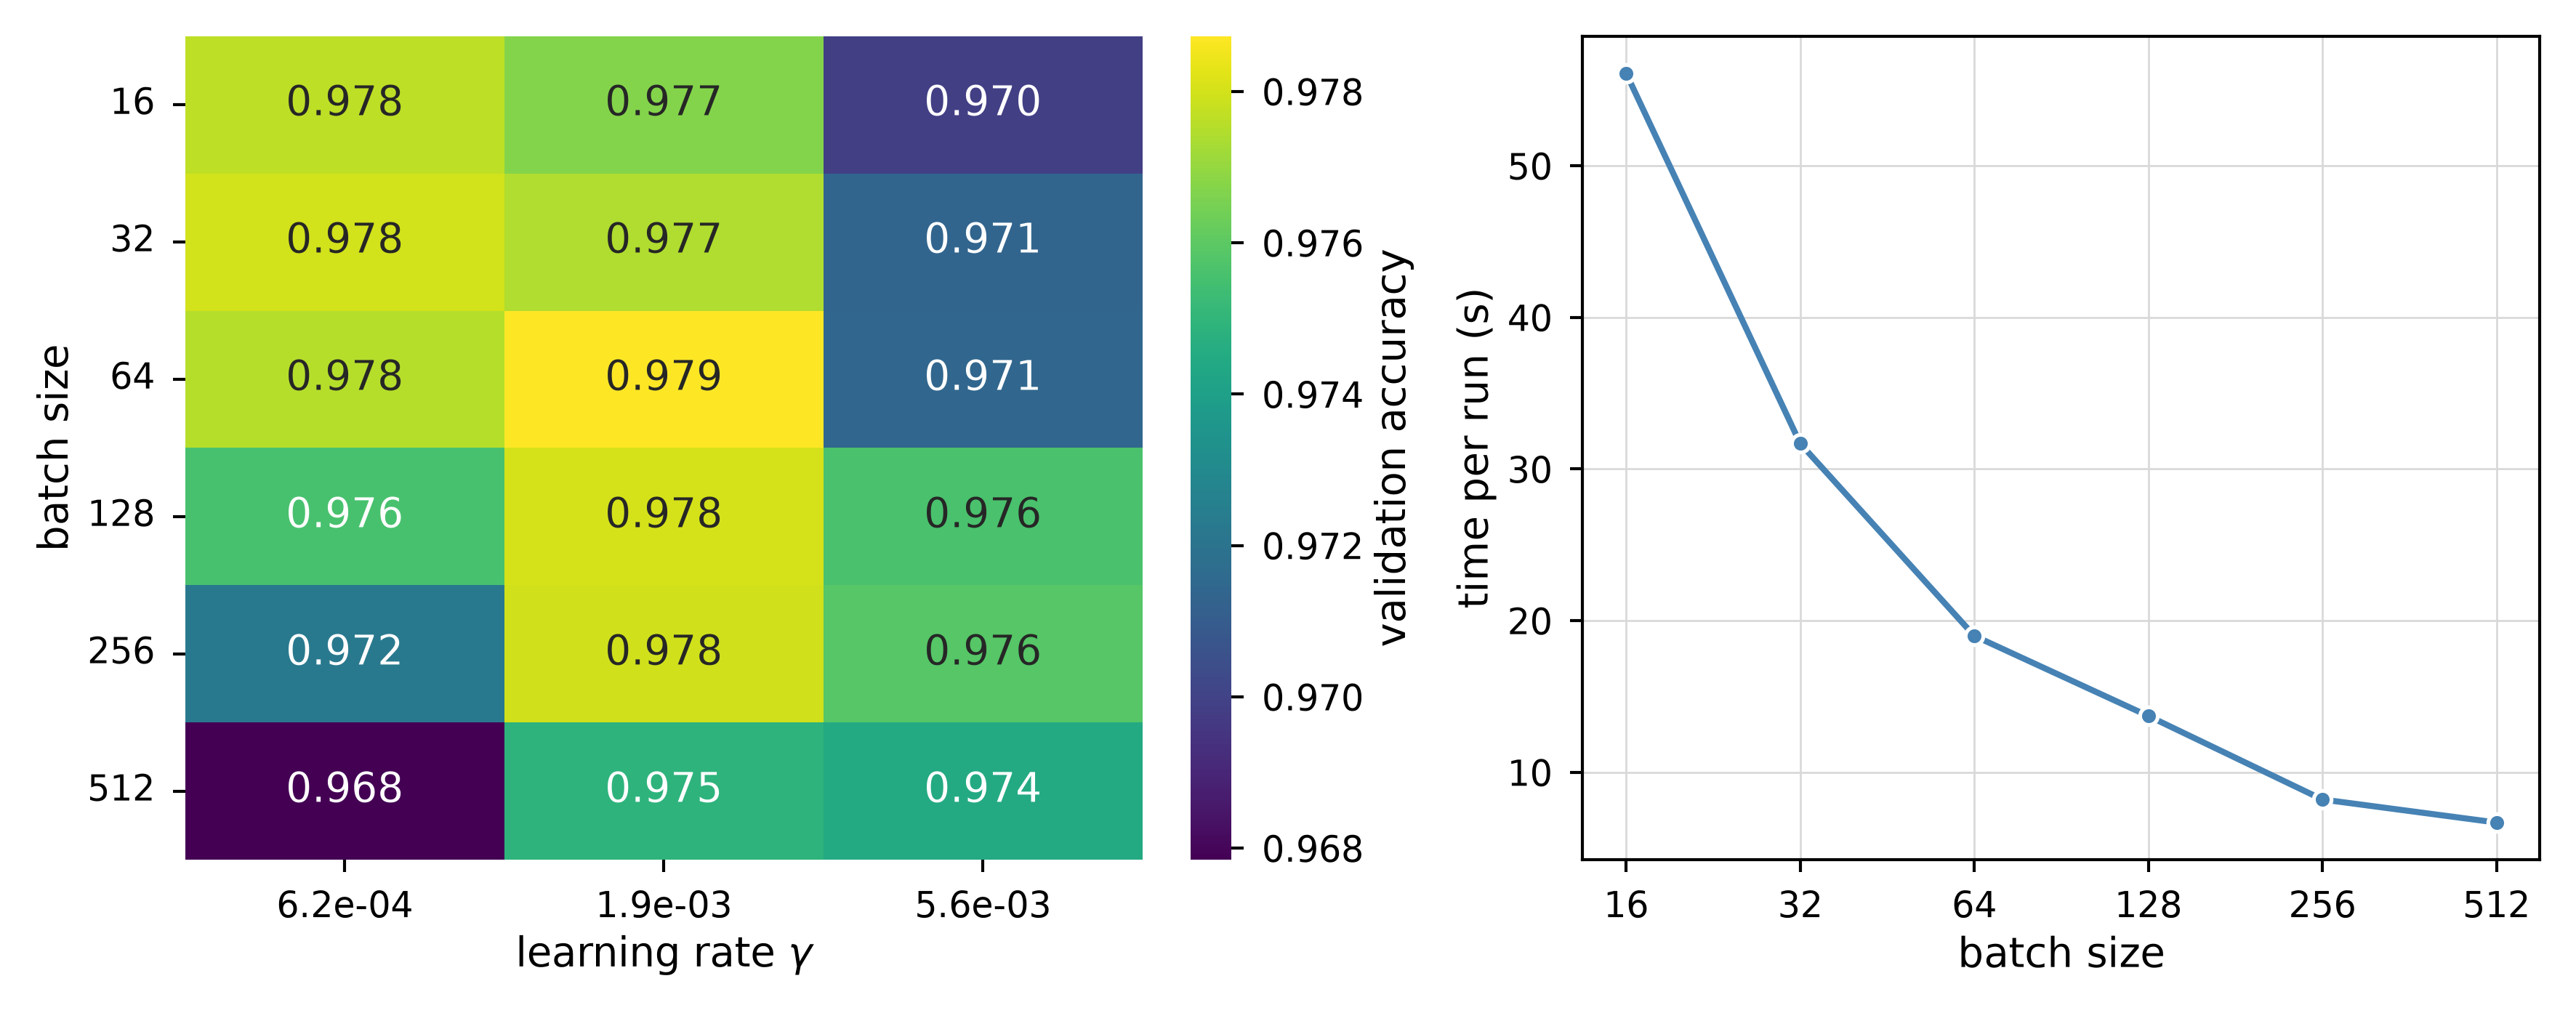

In [ ]:
BATCH_SIZES = [16, 32, 64, 128, 256, 512]
GAMMAS_BATCH = ARCH_GAMMA * np.array([1/3, 1, 3])

def compute_batch_sweep():
    shape = (len(BATCH_SIZES), len(GAMMAS_BATCH), len(SEEDS_E))
    val_accuracy, seconds = np.full(shape, np.nan), np.zeros(shape)
    for b, g, s in np.ndindex(shape):
        t0 = time.perf_counter()
        with np.errstate(all="ignore"):
            _, history = run_one_mnist(ARCH_ACTIVATION, (ARCH_WIDTH,) * ARCH_DEPTH,
                                       (0.0, 0.0), GAMMAS_BATCH[g], EPOCHS_E, BATCH_SIZES[b],
                                       SEEDS_E[s], method=OPT_METHOD)
        val_accuracy[b, g, s] = history["val_metric"][-1]
        seconds[b, g, s] = time.perf_counter() - t0
    return {"val_accuracy": val_accuracy, "seconds": seconds}

batch = u.cached_arrays(RESULTS_PATH / "e_batch.npz", compute_batch_sweep, RERUN)
acc_b = batch["val_accuracy"].mean(axis=-1)

# LLM (Claude): suggested method for how to account for time spent per run.
BATCH_TOL = 0.001
near_best = np.argwhere(acc_b >= acc_b.max() - BATCH_TOL)   # cells within noise of the best
b, g = min(near_best, key=lambda ix: batch["seconds"][ix[0], ix[1]].mean()) # cheapest of them
BATCH_E, ARCH_GAMMA = BATCH_SIZES[b], GAMMAS_BATCH[g]
print(f"batch size {BATCH_E}, gamma {ARCH_GAMMA:.1e}, val acc {acc_b[b, g]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(7, 2.7))
sns.heatmap(acc_b, ax=axes[0], annot=True, fmt=".3f", cmap="viridis",
            cbar_kws={"label": "validation accuracy"}, 
            xticklabels=[f"{g:.1e}" for g in GAMMAS_BATCH], yticklabels=BATCH_SIZES)
axes[0].set(xlabel=r"learning rate $\gamma$", ylabel="batch size")
axes[0].tick_params(axis="y", rotation=0)
sns.lineplot(x=BATCH_SIZES, y=batch["seconds"].mean(axis=(1, 2)), marker="o", ax=axes[1])
axes[1].set(xscale="log", xlabel="batch size", ylabel="time per run (s)", 
            xticks=BATCH_SIZES, xticklabels=BATCH_SIZES)
axes[1].minorticks_off()
fig.savefig(FIGURES_PATH / "E-batch_size.pdf")

Validation accuracy over penalty strength and learning rate on the chosen
architecture, for $\ell_1$ and $\ell_2$. A penalty is only used if it beats
no penalty by more than the noise

lambda (0.0, 0.0), gamma 1.9e-03


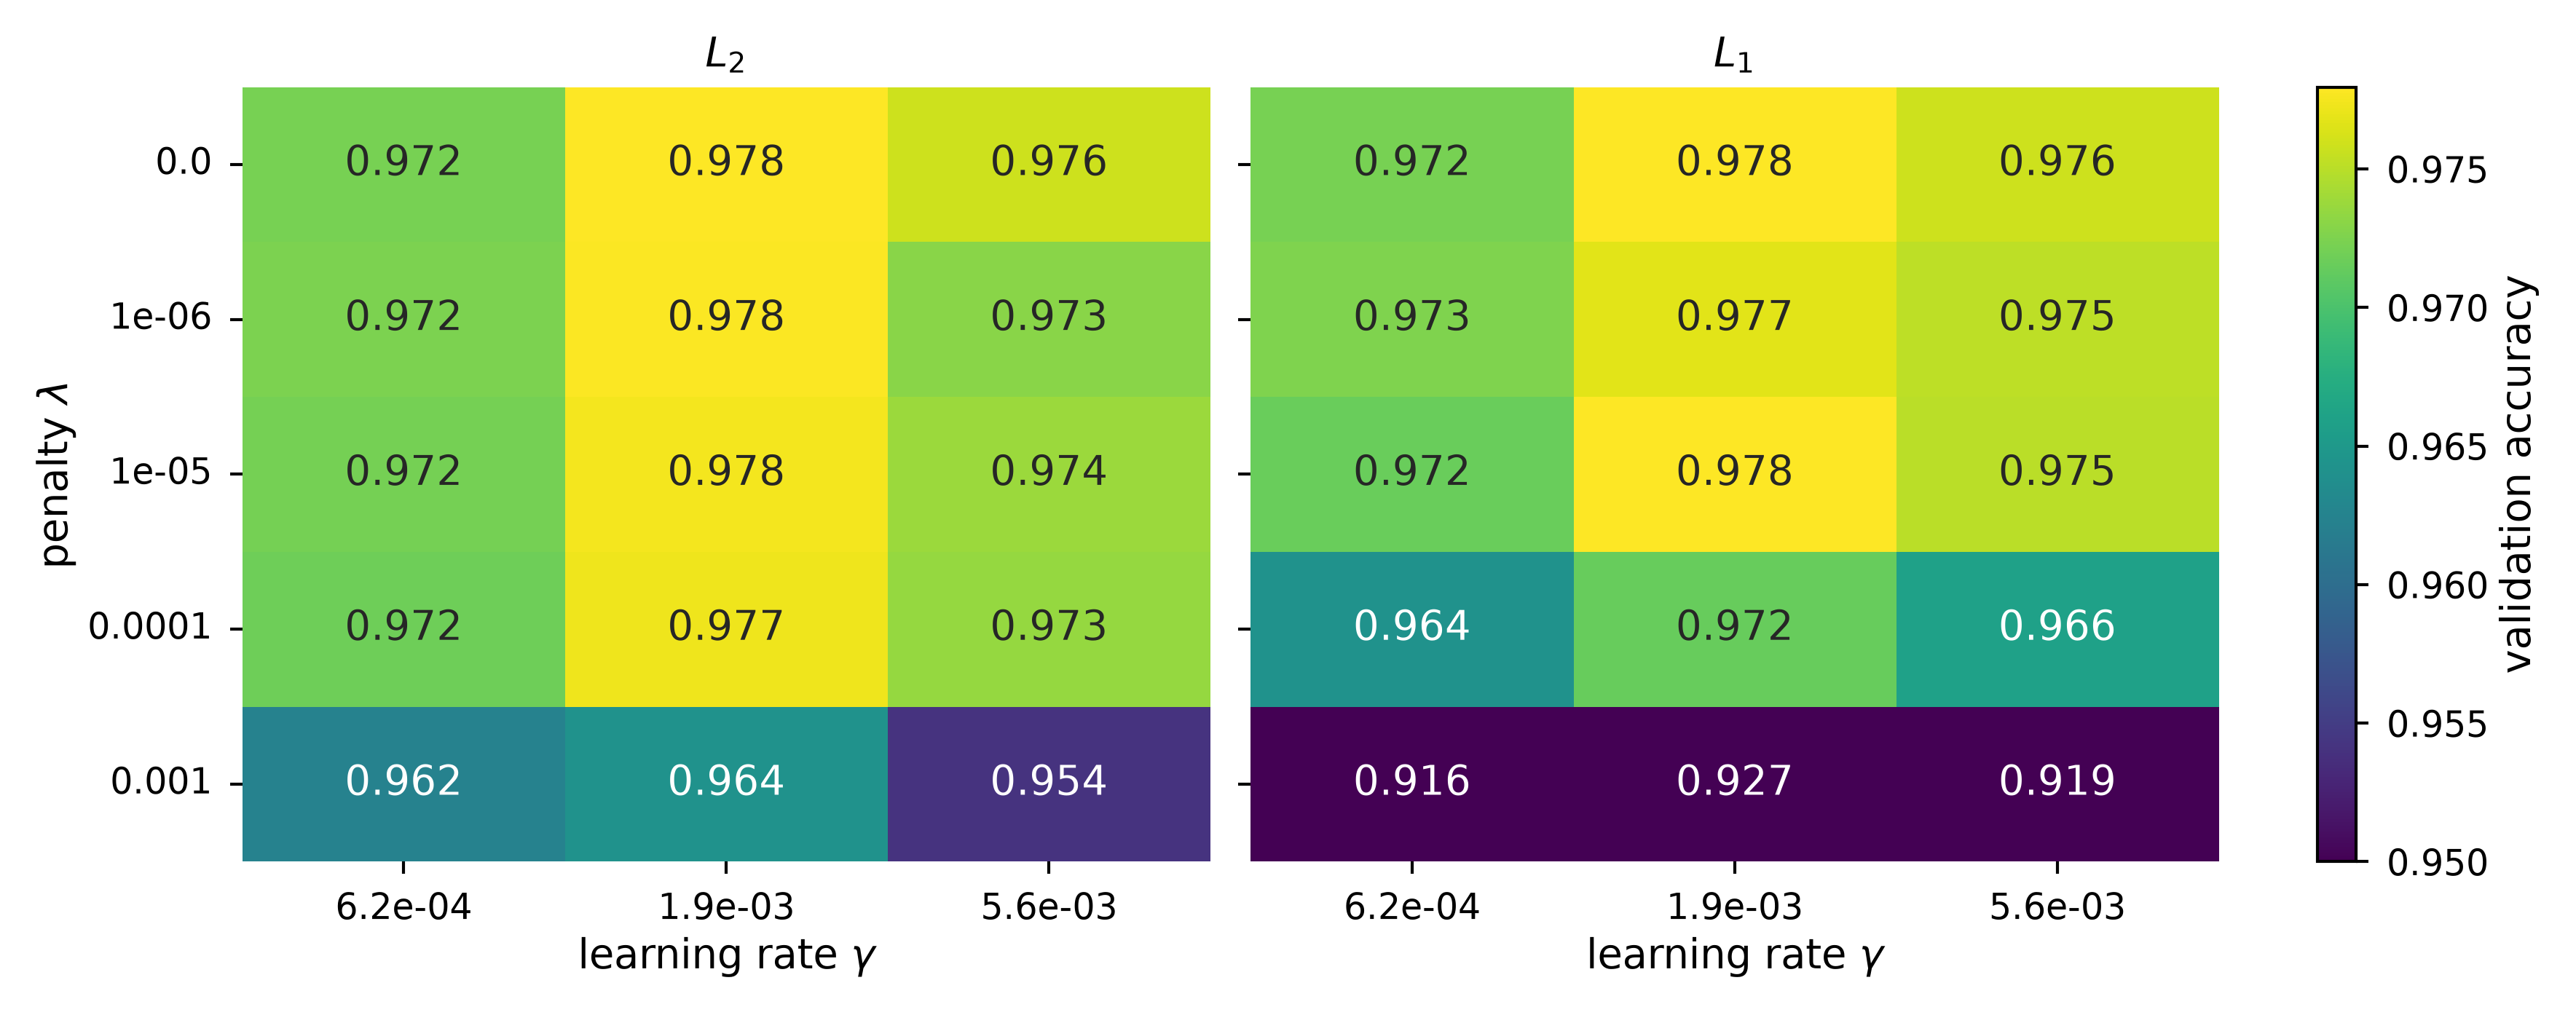

In [ ]:
LAMBDAS_E = np.array([0, 1e-6, 1e-5, 1e-4, 1e-3])
GAMMAS_PEN = ARCH_GAMMA * np.array([1/3, 1, 3])
NOISE = 0.002

def compute_penalty_sweep():
    shape = (len(NORMS), len(LAMBDAS_E), len(GAMMAS_PEN), len(SEEDS_E))
    val_accuracy = np.full(shape, np.nan)
    hidden = (ARCH_WIDTH,) * ARCH_DEPTH
    for n, l, g, s in np.ndindex(shape):
        lam = (LAMBDAS_E[l], 0.0) if NORMS[n] == "l1" else (0.0, LAMBDAS_E[l])
        with np.errstate(all="ignore"):
            _, history = run_one_mnist(ARCH_ACTIVATION, hidden, lam, GAMMAS_PEN[g],
                                       EPOCHS_E, BATCH_E, SEEDS_E[s], method=OPT_METHOD)
        val_accuracy[n, l, g, s] = history["val_metric"][-1]
    return {"val_accuracy": val_accuracy}

penalty = u.cached_arrays(RESULTS_PATH / "e_penalty.npz", compute_penalty_sweep, RERUN)
penalty_accuracy_mean = penalty["val_accuracy"].mean(axis=-1)

best_penalty = {}
fig, axes = plt.subplots(1, 2, figsize=(7, 2.7), sharey=True)
for ax, norm, grid in zip(axes, NORMS, penalty_accuracy_mean):
    sns.heatmap(grid, ax=ax, annot=True, fmt=".3f", cmap="viridis", cbar=False,
                vmin=0.95, vmax=np.nanmax(penalty_accuracy_mean),
                xticklabels=[f"{g:.1e}" for g in GAMMAS_PEN],
                yticklabels=LAMBDAS_E)
    ax.tick_params(axis="y", rotation=0)
    ax.set(title=f"$L_{norm[1]}$", xlabel=r"learning rate $\gamma$")
    best_penalty[norm] = u.best_cell(grid[1:], smallest=False, lam=LAMBDAS_E[1:],
                                     gamma=GAMMAS_PEN)
axes[0].set_ylabel(r"penalty $\lambda$")
fig.colorbar(axes[0].collections[0], ax=axes, label="validation accuracy")
fig.savefig(FIGURES_PATH / "E-penalty.pdf")

# Use a penalty only if it clearly beats lambda = 0
best_no_penalty = u.best_cell(penalty_accuracy_mean[0, 0], smallest=False, gamma=GAMMAS_PEN)
winner = max(best_penalty, key=lambda norm: best_penalty[norm]["value"])
if best_penalty[winner]["value"] > best_no_penalty["value"] + NOISE:
    lam_best = (best_penalty[winner]["lam"], 0.0) if winner == "l1" else (0.0, best_penalty[winner]["lam"])
    gamma_best = best_penalty[winner]["gamma"]
else:
    lam_best, gamma_best = (0.0, 0.0), best_no_penalty["gamma"]
print(f"lambda {lam_best}, gamma {gamma_best:.1e}")

Long run of the chosen configuration on the fit set. The validation curves
decide the number of epochs for the final model

best epoch 26, val accuracy 0.9808, min val cost at epoch 10


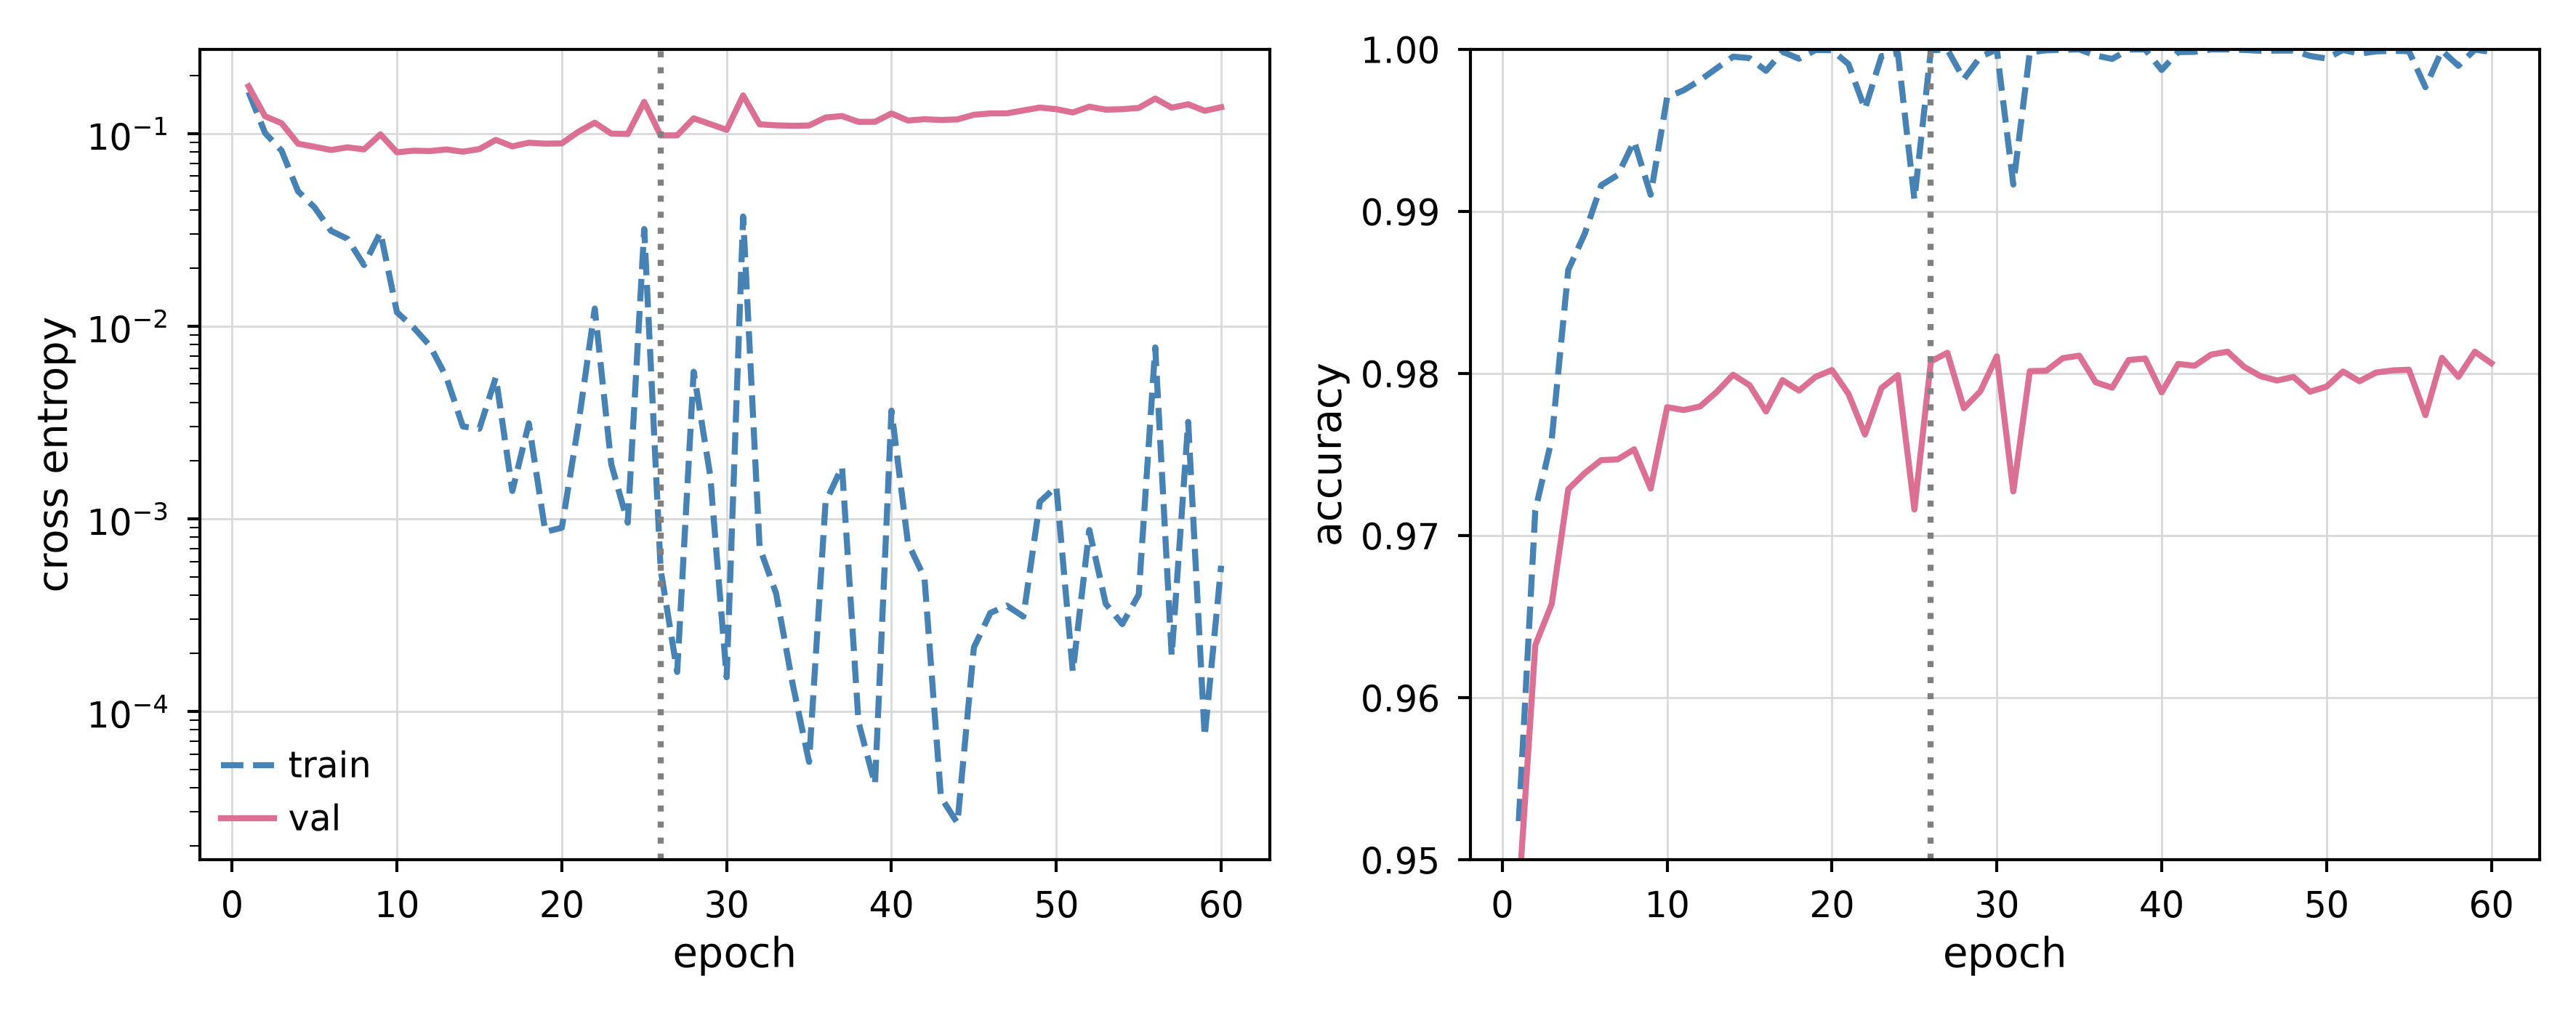

In [ ]:
FINAL = {"activation": ARCH_ACTIVATION,
         "hidden": (ARCH_WIDTH,) * ARCH_DEPTH,
         "lam": lam_best,
         "gamma": gamma_best,
         "method": OPT_METHOD}
EPOCHS_LONG = 60

def compute_final_val_curves():
    names = ("train_cost", "val_cost", "train_accuracy", "val_accuracy")
    curves = {name: np.zeros((len(SEEDS_E), EPOCHS_LONG)) for name in names}
    for s, seed in enumerate(SEEDS_E):
        _, history = run_one_mnist(FINAL["activation"], FINAL["hidden"], FINAL["lam"],
                                   FINAL["gamma"], EPOCHS_LONG, BATCH_E, seed,
                                   method=FINAL["method"])
        curves["train_cost"][s], curves["train_accuracy"][s] = history["train_cost"], history["train_metric"]
        curves["val_cost"][s], curves["val_accuracy"][s] = history["val_cost"], history["val_metric"]
    return curves

final_curves = u.cached_arrays(RESULTS_PATH / "e_final_val_curves.npz", compute_final_val_curves, RERUN)
epochs_long = np.arange(1, EPOCHS_LONG + 1)
val_accuracy_curve = final_curves["val_accuracy"].mean(axis=0)
val_cost_curve = final_curves["val_cost"].mean(axis=0)

# Fewest epochs that get within the noise of the best validation accuracy
best_epoch = int(np.argmax(val_accuracy_curve >= val_accuracy_curve.max() - NOISE / 2)) + 1
FINAL["epochs"] = best_epoch
print(f"best epoch {best_epoch}, val accuracy {val_accuracy_curve[best_epoch-1]:.4f}, "
      f"min val cost at epoch {int(np.argmin(val_cost_curve)) + 1}")

fig, axes = plt.subplots(1, 2, figsize=(7, 2.7))
for name, ax in zip(("cost", "accuracy"), axes):
    for split, ls in (("train", "--"), ("val", "-")):
        sns.lineplot(x=epochs_long, y=final_curves[f"{split}_{name}"].mean(axis=0), ls=ls,
                     label=split if name == "cost" else None, ax=ax)
    ax.axvline(best_epoch, color="gray", ls=":")
    ax.set(xlabel="epoch", ylabel="cross entropy" if name == "cost" else "accuracy")
axes[0].set_yscale("log")
axes[1].set_ylim(0.95, 1.0)
fig.savefig(FIGURES_PATH / "E-final_val_curves.pdf")

Retrain the whole training set, predict the test set

In [ ]:
SEEDS_FINAL = [0, 1, 2, 3, 4]

def train_on_full_train(hidden, activation, lam, gamma, epochs, method, seeds):
    '''Train on all 60k training images, return softmax outputs on the test set per seed'''
    l1, l2 = lam
    probs = np.zeros((len(seeds), len(x_test), 10))
    seconds = np.zeros(len(seeds))
    for s, seed in enumerate(seeds):
        net = NeuralNetwork([x_train.shape[1], *hidden, 10],
                            [activation] * len(hidden) + ["softmax"],
                            "cross_entropy", lmbd1=l1, lmbd2=l2, seed=seed)
        t0 = time.perf_counter()
        train(net, x_train, Y_train, method=method, gamma=gamma, epochs=epochs,
              batch_size=BATCH_E, seed=seed)
        seconds[s] = time.perf_counter() - t0
        probs[s] = net.predict(x_test)
    return {"probs": probs, "seconds": seconds}

final_nn = u.cached_arrays(RESULTS_PATH / "e_final_nn.npz", lambda: train_on_full_train(
    FINAL["hidden"], FINAL["activation"], FINAL["lam"], FINAL["gamma"],
    FINAL["epochs"], FINAL["method"], SEEDS_FINAL), RERUN)

# Same as baseline curves (no hidden layer, 20 epochs, adam)
final_lr = u.cached_arrays(RESULTS_PATH / "e_final_logreg_own.npz", lambda: train_on_full_train(
    (), "relu", (0.0, 0.0), 1e-3, EPOCHS_BASE, "adam", SEEDS_FINAL[:3]), RERUN)

Compare against same architecture in scikit-learn

In [ ]:
def compute_sklearn_mlp():
    t0 = time.perf_counter()
    mlp = MLPClassifier(hidden_layer_sizes=FINAL["hidden"], activation="relu",
                        solver="adam", batch_size=BATCH_E, learning_rate_init=FINAL["gamma"],
                        alpha=0.0, max_iter=FINAL["epochs"], n_iter_no_change=FINAL["epochs"],
                        random_state=SEED).fit(x_train, y_train)
    return {"probs": mlp.predict(x_test), "seconds": np.array(time.perf_counter() - t0)}

sk_mlp = u.cached_arrays(RESULTS_PATH / "e_sklearn_mlp.npz", compute_sklearn_mlp, RERUN)

table: test accuracy, with the two kinds of uncertainty

In [ ]:
preds_nn = final_nn["probs"].argmax(axis=2)
preds_lr = final_lr["probs"].argmax(axis=2)
acc_nn = np.array([accuracy(y_test, p) for p in preds_nn])
acc_lr = np.array([accuracy(y_test, p) for p in preds_lr])
se = lambda a: np.sqrt(a * (1 - a) / len(y_test))   # binomal standard error

rows = [("logistic, own code",          acc_lr.mean(), acc_lr.std(), final_lr["seconds"].mean()),
        ("logistic, sklearn (saga)",    accuracy(y_test, logreg_predictions), np.nan, np.nan),
        (f"NN {FINAL['hidden']}, own code", acc_nn.mean(), acc_nn.std(), final_nn["seconds"].mean()),
        ("MLP, sklearn",                accuracy(y_test, sk_mlp["probs"]), np.nan, float(sk_mlp["seconds"]))]
print(f"{'model':<34}{'test acc':>9}{'± SE':>8}{'seed std':>10}{'time (s)':>10}")
for name, a, sd, t in rows:
    print(f"{name:<34}{a:>9.4f}{se(a):>8.4f}{sd:>10.4f}{t:>10.1f}")

model                              test acc    ± SE  seed std  time (s)
logistic, own code                   0.9267  0.0026    0.0002       2.1
logistic, sklearn (saga)             0.9257  0.0026       nan       nan
NN (256,), own code                  0.9768  0.0015    0.0062      23.5
MLP, sklearn                         0.9830  0.0013       nan      43.4


Confusion matrix, full and errors only

true 9 -> predicted 4: 8 images
true 7 -> predicted 9: 7 images
true 7 -> predicted 2: 6 images
true 4 -> predicted 9: 6 images
true 5 -> predicted 3: 6 images

digit   precision   recall      F1
0           0.985    0.994   0.989
1           0.992    0.992   0.992
2           0.986    0.983   0.984
3           0.982    0.983   0.983
4           0.979    0.981   0.980
5           0.988    0.980   0.984
6           0.988    0.985   0.987
7           0.981    0.982   0.981
8           0.981    0.978   0.980
9           0.976    0.980   0.978
macro F1: NN 0.9838, logistic 0.9246


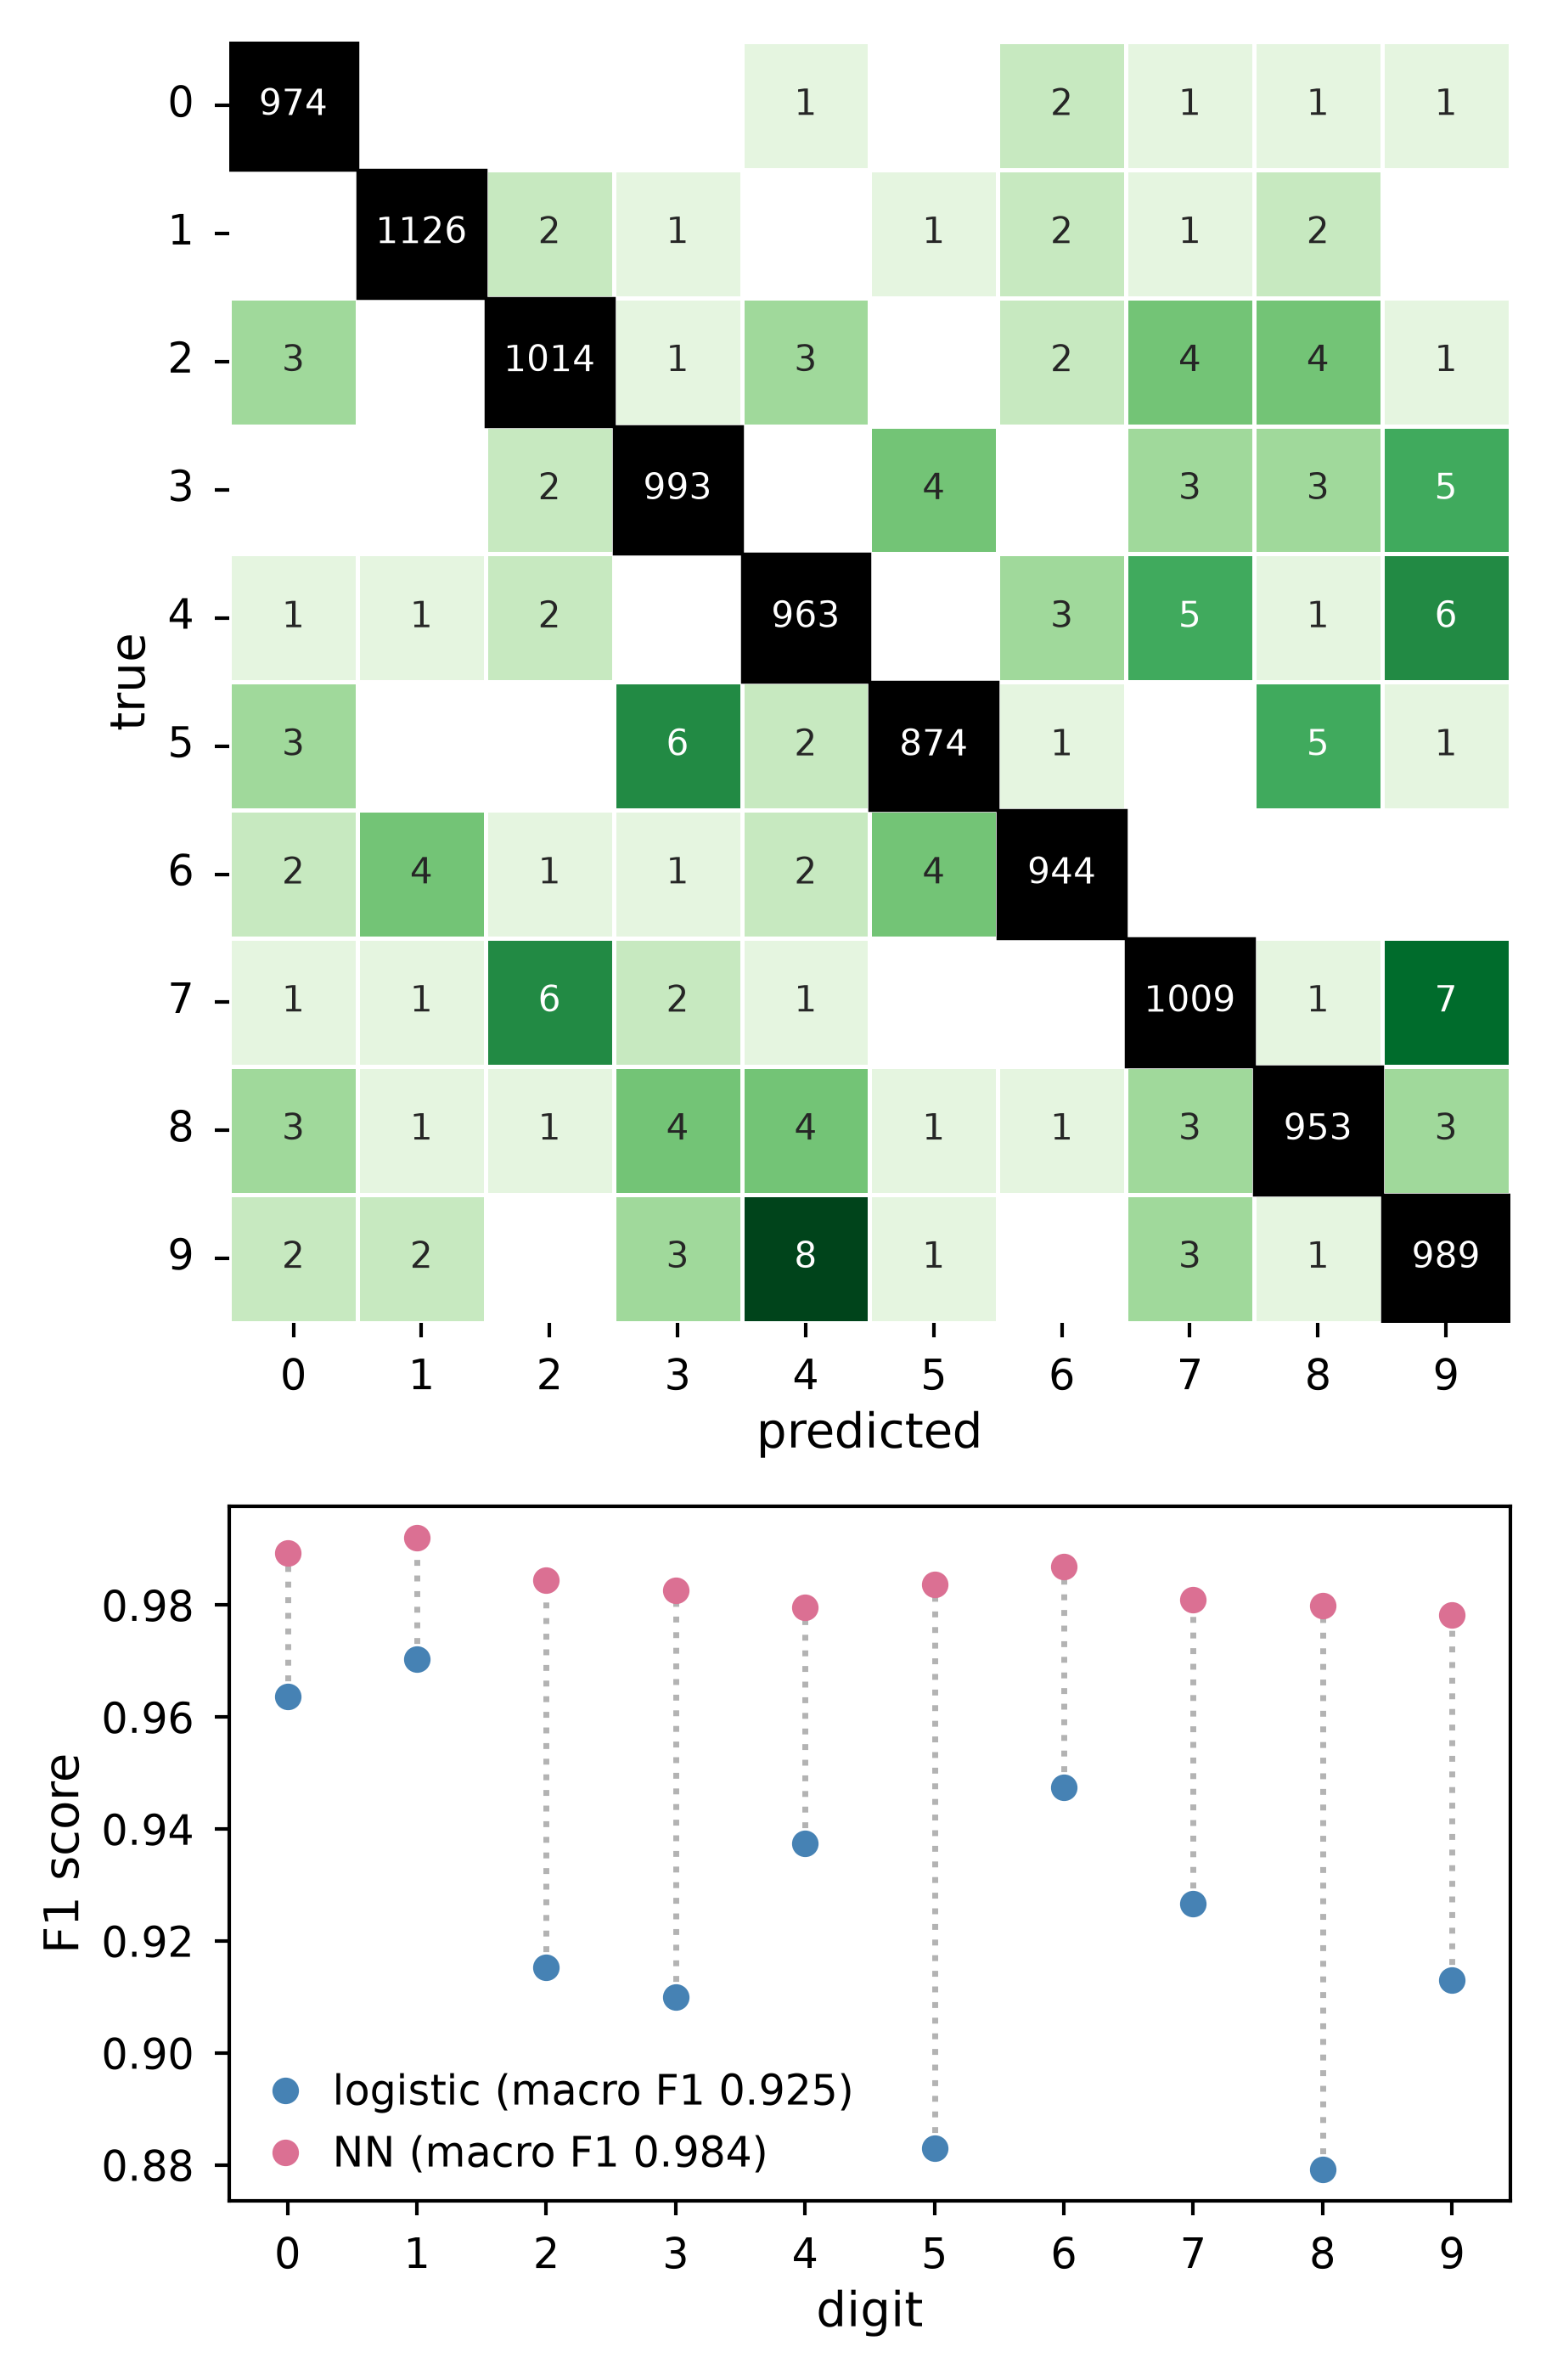

In [ ]:
C_nn = confusion_matrix(y_test, preds_nn[0])    # rows = true, columns = predicted
C_lr = confusion_matrix(y_test, logreg_predictions)
prec, rec, f1, macro_f1 = precision_recall_f1(C_nn)
_, _, f1_lr, macro_f1_lr = precision_recall_f1(C_lr)

fig, (ax_cm, ax_f1) = plt.subplots(2, 1, figsize=(COL, 5.6), gridspec_kw={"height_ratios": [3.3, 1.7]})

errors = C_nn.copy(); np.fill_diagonal(errors, 0)
sns.heatmap(errors, ax=ax_cm, mask=(errors == 0), cmap="Greens", vmin=0, cbar=False,
            square=True, annot=True, fmt="d", annot_kws={"size": 6}, linewidths=0.5,
            linecolor="white")
for k in range(10):
    ax_cm.add_patch(Rectangle((k, k), 1, 1, color="k"))
    ax_cm.text(k + 0.5, k + 0.5, f"{C_nn[k, k]}",
               ha="center", va="center", fontsize=6, color="white")
ax_cm.set(xlabel="predicted", ylabel="true")
ax_cm.tick_params(axis="y", rotation=0)
ax_cm.grid(False)

digits = np.arange(10)
ax_f1.vlines(digits, f1_lr, f1, color="0.7", lw=1, ls=":")
ax_f1.plot(digits, f1_lr, "o", color="steelblue", label=f"logistic (macro F1 {macro_f1_lr:.3f})")
ax_f1.plot(digits, f1, "o", color="palevioletred", label=f"NN (macro F1 {macro_f1:.3f})")
ax_f1.set(xticks=digits, xlabel="digit", ylabel="F1 score")
ax_f1.legend(loc="lower left")
ax_f1.grid(False)
fig.savefig(FIGURES_PATH / "E-confusion_and_f1.pdf")

for flat in np.argsort(errors, axis=None)[::-1][:5]:
    t, p = divmod(flat, 10)
    print(f"true {t} -> predicted {p}: {errors[t, p]} images")
    
print()
print(f"{'digit':<7}{'precision':>10}{'recall':>9}{'F1':>8}")
for k in range(10):
    print(f"{k:<7}{prec[k]:>10.3f}{rec[k]:>9.3f}{f1[k]:>8.3f}")
print(f"macro F1: NN {macro_f1:.4f}, logistic {macro_f1_lr:.4f}")

the most confident mistakes

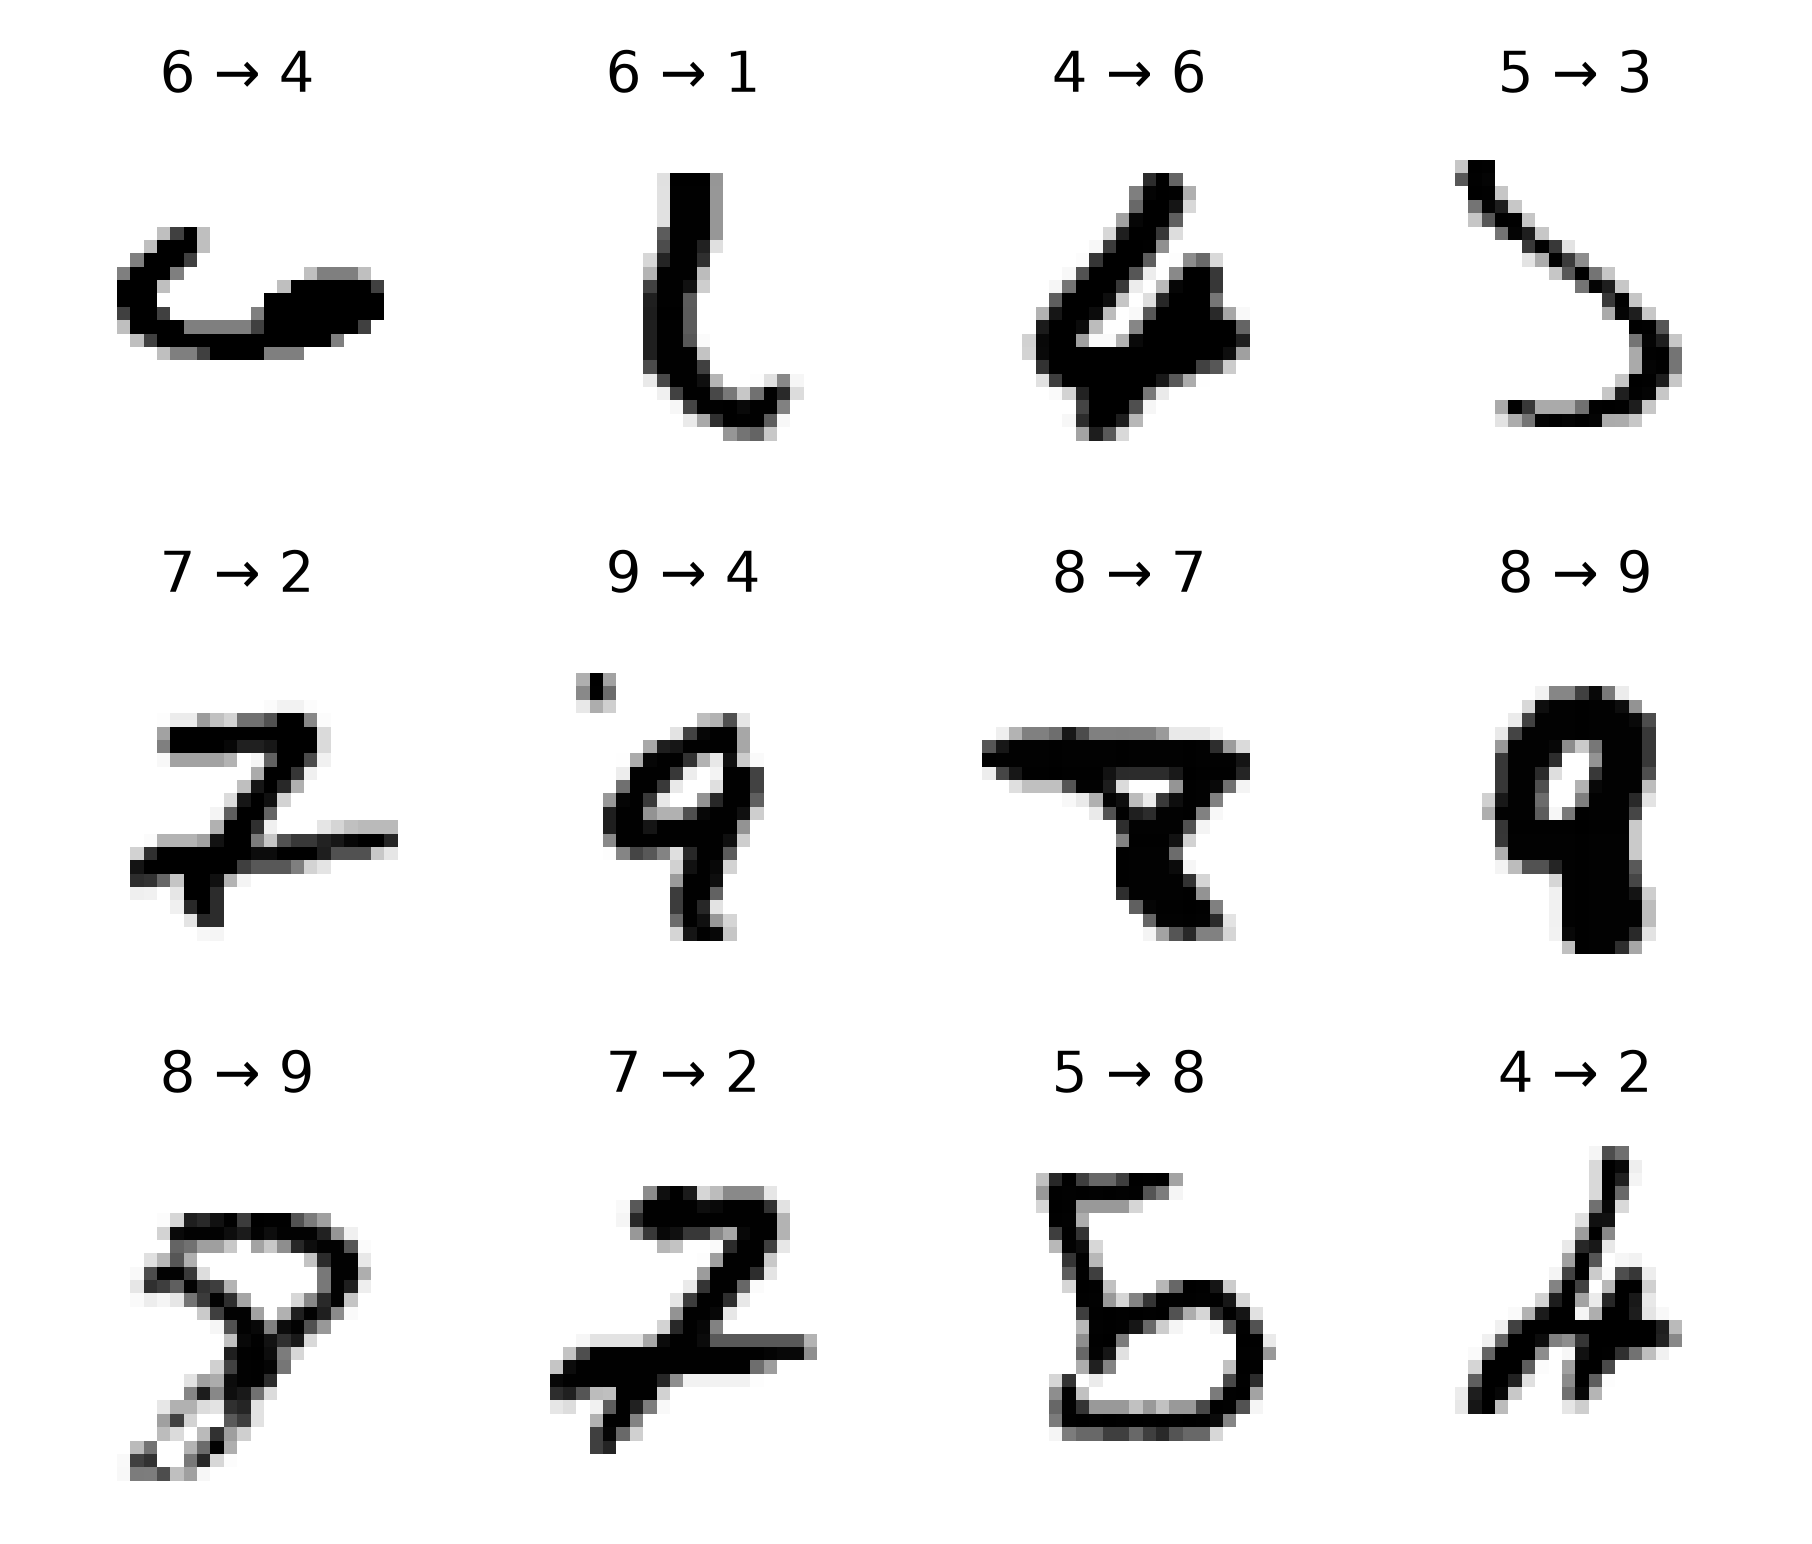

In [ ]:
probs0, pred0 = final_nn["probs"][0], preds_nn[0]
wrong = np.flatnonzero(pred0 != y_test)
worst = wrong[np.argsort(probs0[wrong, pred0[wrong]])[::-1][:12]]   # most confident wrong

fig, axes = plt.subplots(3, 4, figsize=(COL, 3))
for ax, i in zip(axes.ravel(), worst):
    ax.imshow(x_test[i].reshape(28, 28), cmap="gray_r")
    ax.set_title(f"{y_test[i]} → {pred0[i]}")
    ax.axis("off")
fig.savefig(FIGURES_PATH / "E-misclassified.pdf")

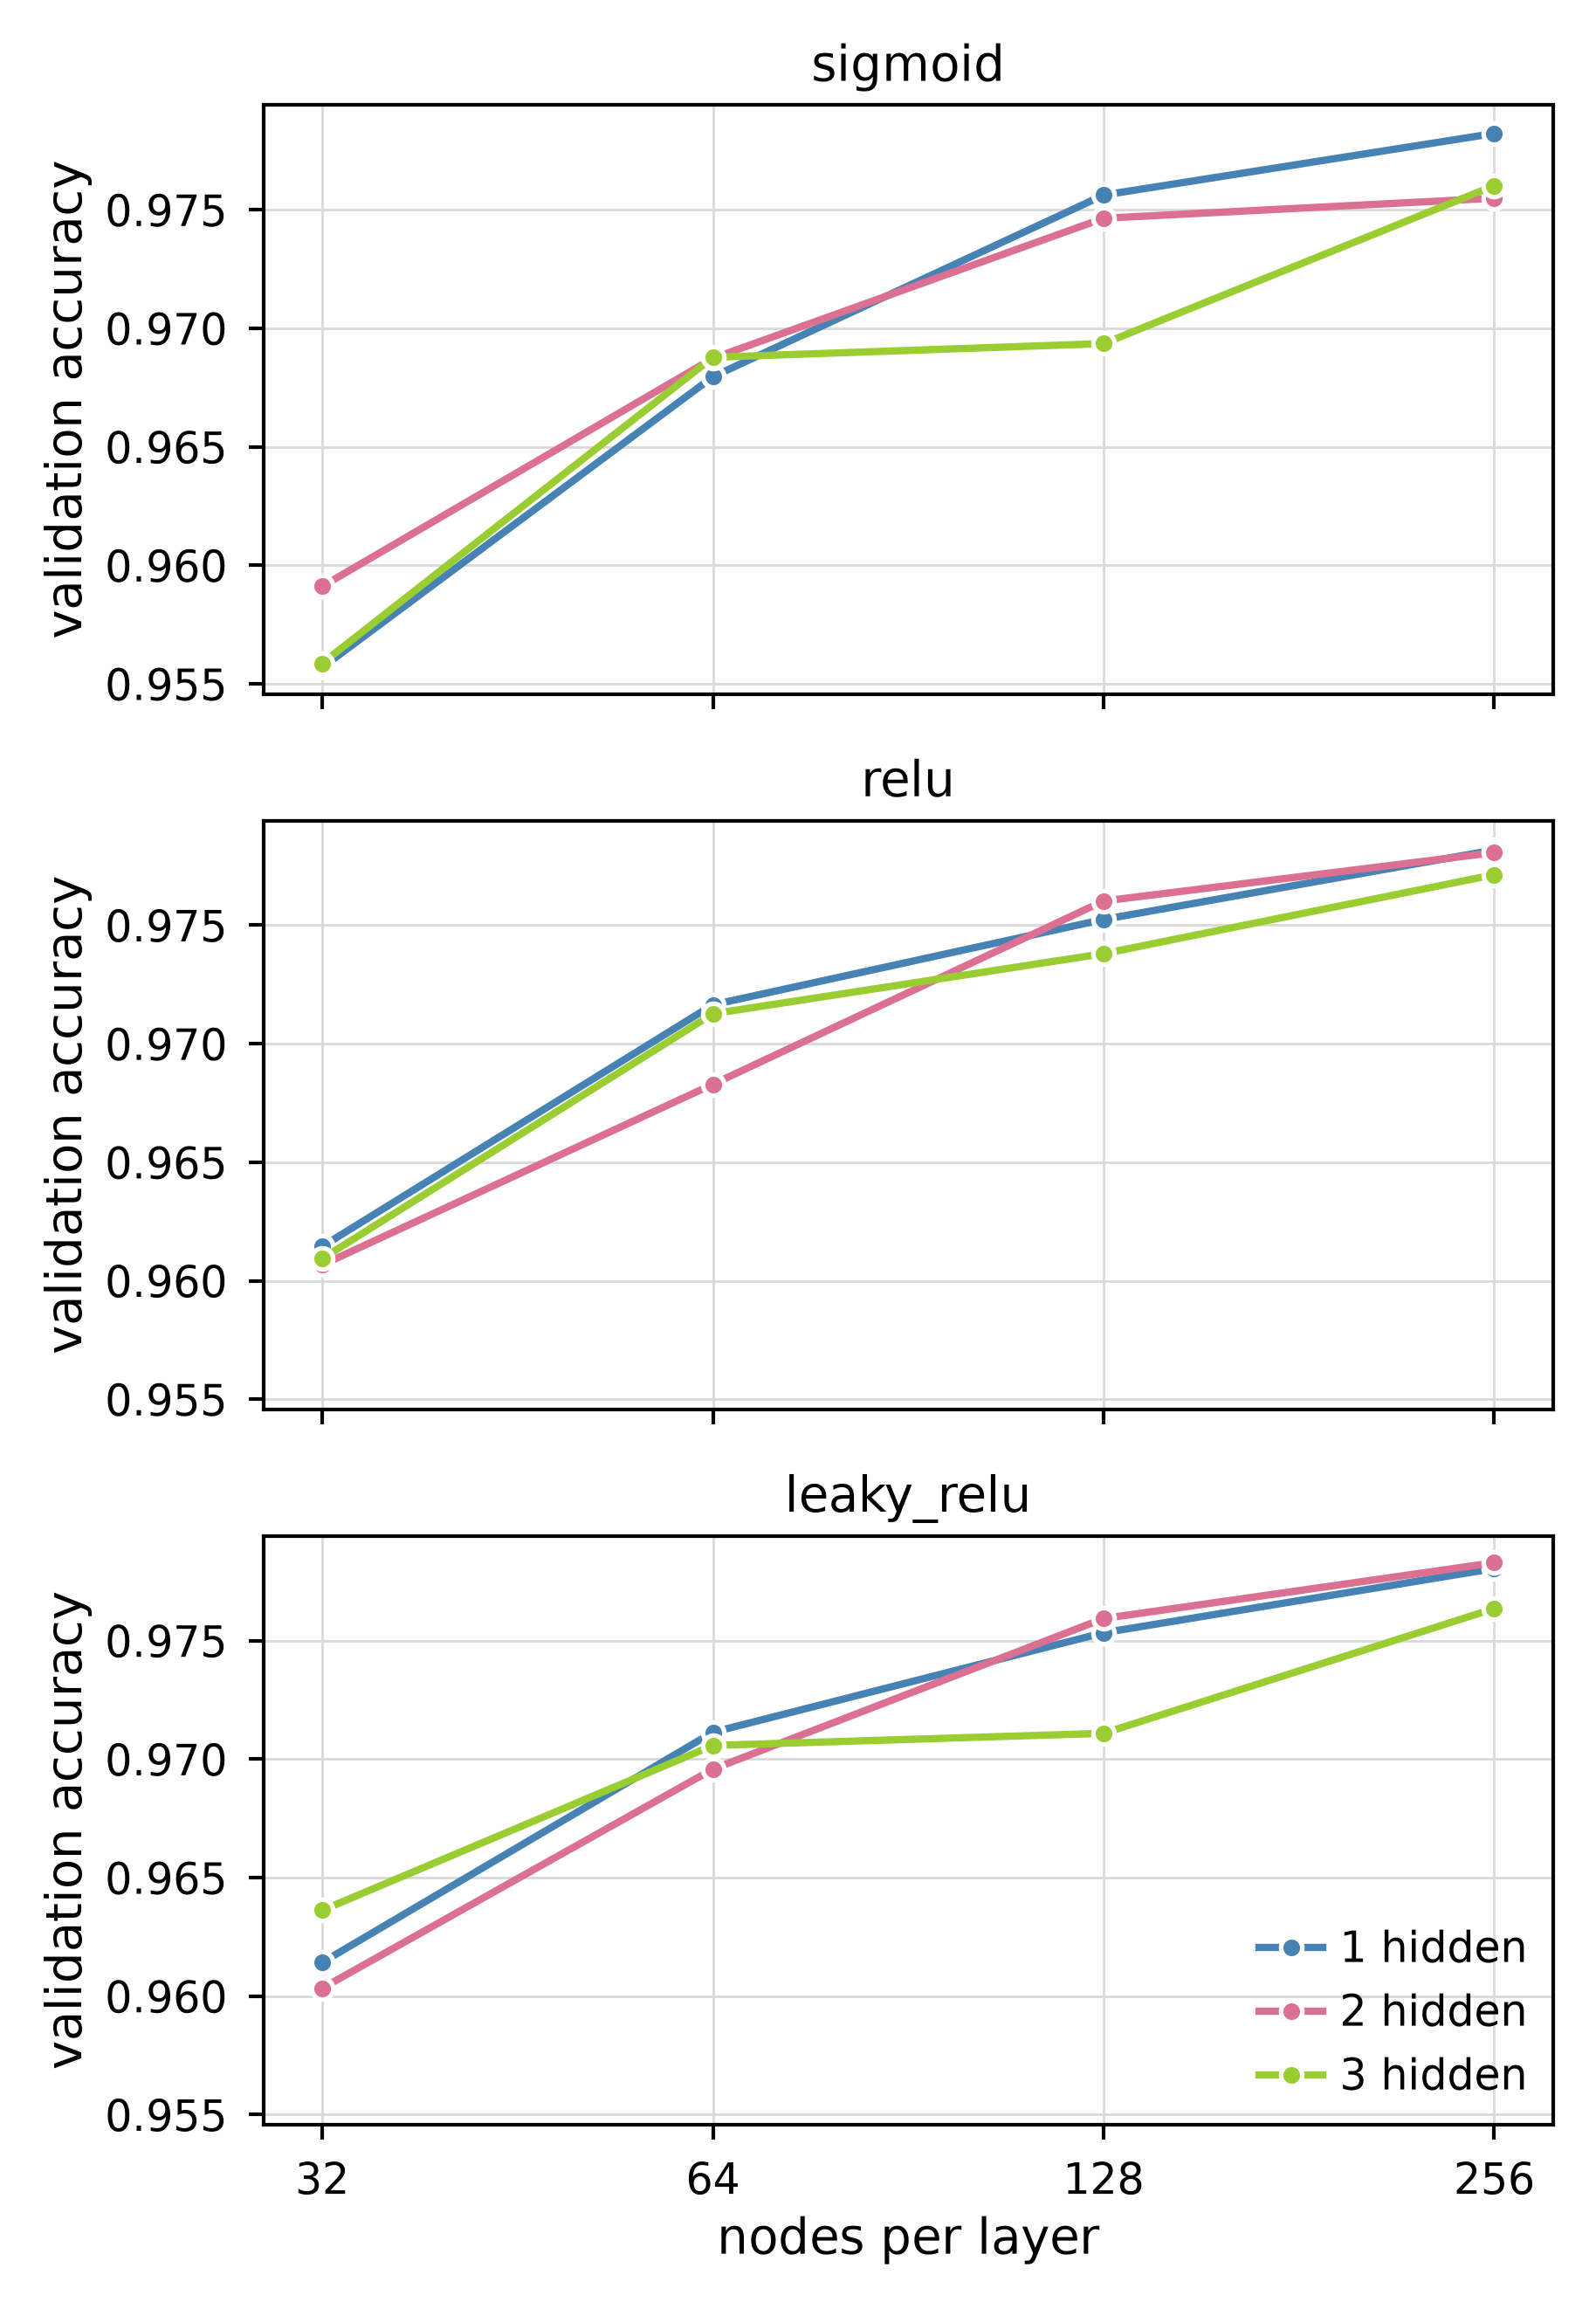

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(COL, 5.2), sharex=True, sharey=True)
for a, ax in enumerate(axes):
    for d, depth in enumerate(DEPTHS_E):
        sns.lineplot(x=WIDTHS_E, y=arch_accuracy_best[a, d], marker="o", label=f"{depth} hidden", ax=ax)
    #ax.axhline(baseline["val_accuracy"][0, -1], color="k", ls=":", label="no hidden layer")
    ax.set(ylabel="validation accuracy", title=ACTIVATIONS_E[a])
axes[-1].legend(loc="lower right")
axes[-1].set(xscale="log", xticks=WIDTHS_E, xticklabels=WIDTHS_E, xlabel="nodes per layer")
axes[-1].minorticks_off()
for ax in axes[:-1]:
    ax.get_legend().remove()        # one legend is enough
fig.savefig(FIGURES_PATH / "E-width_curves.pdf")

<div style="background-color:#F0DAE2; color:#823C55; border-radius:12px; padding:16px; width:90%;">

**Part f)** Various algorithms

</div>

In [ ]:
import pandas as pd

def n_params(sizes):
    return sum((a + 1) * b for a, b in zip(sizes[:-1], sizes[1:]))

def time_it(fn, repeats=3):
    best = np.inf
    for _ in range(repeats):
        t0 = time.perf_counter()
        fn()
        best = min(best, time.perf_counter() - t0)
    return best

# Regression network from part C
R_ACT, R_DEPTH, R_WIDTH = best_c["activation"], best_c["depth"], best_c["width"]
R_SIZES = [1] + [R_WIDTH] * R_DEPTH + [1]

def time_nn(lam, gamma):
    def fit():
        net = NeuralNetwork(R_SIZES, [R_ACT] * R_DEPTH + ["identity"], "mse",
                            lmbd1=lam[0], lmbd2=lam[1], seed=SEED)
        with np.errstate(all="ignore"):
            train(net, runge_X_train, runge_Y_train, method="rmsprop",
                  gamma=gamma, epochs=EPOCHS_D, batch_size=10, seed=SEED)
    return time_it(fit, repeats=2)

# Tuning effort = numer of fits / training runs used choose hyperparameters
effort_b = len(OPTIMIZERS) * len(LEARNING_RATES) + len(ARCHITECTURES) * len(LEARNING_RATES)
effort_c = depth_width["val_mse"].size
effort_d = penalty_sweep["val_mse"][0].size
effort = {"OLS": MAX_DEGREE * K,
          "Ridge": MAX_DEGREE * len(ALPHAS_P1) * K,
          "Lasso": MAX_DEGREE * len(ALPHAS_P1) * K,
          "NN, no penalty": effort_b + effort_c,
          "NN, L2": effort_b + effort_c + effort_d,
          "NN, L1": effort_b + effort_c + effort_d}

rows = []
for name, Model, extra in [("OLS", LinearRegression, {}), ("Ridge", Ridge, {}),
                           ("Lasso", Lasso, {"max_iter": 100_000})]:
    info = benchmarks[name]
    kw = {} if name == "OLS" else {"alpha": info["alpha"]}
    t = time_it(lambda: u.poly_model(info["degree"], Model(**kw, **extra)).fit(runge_X_train, runge_y_train))
    hyper = f"degree {info['degree']}" + ("" if name == "OLS" else rf", $\alpha$={info['alpha']:.0e}")
    rows.append([name, hyper, info["degree"] + 1, rf"{info['test_mse']:.4f}", f"{1e3 * t:.1f}", effort[name]])
    
for name, (lam, gamma) in nn_settings.items():
    mean, std, _ = nn_results[name]
    hyper = rf"{R_DEPTH}$\times${R_WIDTH} {R_ACT}, $\lambda$={max(lam):.0e}, $\gamma$={gamma:.0e}"
    rows.append([name, hyper, n_params(R_SIZES), rf"{mean:.4f} $\pm$ {std:.4f}",
    f"{1e3 * time_nn(lam, gamma):.1f}", effort[name]])
    
reg_df = pd.DataFrame(rows, columns=["Model", "Settings", "Parameters", "Test MSE", "Train time (ms)", "Tuning fits"])
print(reg_df.to_string(index=False))
print("noise floor sigma^2 = ", 0.1 ** 2)
reg_df.to_latex(RESULTS_PATH / "f_regression_table.tex", index=False, escape=False)

         Model                                          Settings  Parameters            Test MSE Train time (ms)  Tuning fits
           OLS                                         degree 12          13              0.0093             0.7          100
         Ridge                         degree 14, $\alpha$=4e-07          15              0.0105             0.6          600
         Lasso                         degree 14, $\alpha$=1e-08          15              0.0085            47.7          600
NN, no penalty 4$\times$25 relu, $\lambda$=0e+00, $\gamma$=1e-03        2026 0.0165 $\pm$ 0.0006           265.3          648
        NN, L2 4$\times$25 relu, $\lambda$=1e-03, $\gamma$=3e-04        2026 0.0074 $\pm$ 0.0009           267.1          816
        NN, L1 4$\times$25 relu, $\lambda$=3e-04, $\gamma$=3e-04        2026 0.0078 $\pm$ 0.0009           266.0          816
noise floor sigma^2 =  0.010000000000000002


In [ ]:
macro = lambda pred: precision_recall_f1(confusion_matrix(y_test, pred))[3]
se = lambda a: np.sqrt(a * (1 - a) / len(y_test))
sizes_nn = [x_train.shape[1], *FINAL["hidden"], 10]

# Tuning effort for the NN
effort_e = (optimizer["val_accuracy"].size + architecture["val_accuracy"].size
            + penalty["val_accuracy"].size + batch["val_accuracy"].size
            + int(np.prod(finalist_curves["val_accuracy"].shape[:2])))
sk_hidden = FINAL["hidden"]

rows = [
    ["Logistic, own code", acc_lr.mean(), macro(preds_lr[0]), n_params([x_train.shape[1], 10]),
     final_lr["seconds"].mean(), 0],
    ["Logistic, scikit-learn", accuracy(y_test, logreg_predictions), macro(logreg_predictions),
     n_params([x_train.shape[1], 10]), np.nan, 10],
    ["NN, own code", acc_nn.mean(), macro(preds_nn[0]), n_params(sizes_nn),
     final_nn["seconds"].mean(), effort_e],
    ["MLP, scikit-learn", accuracy(y_test, sk_mlp["probs"]), macro(sk_mlp["probs"]),
     n_params(sizes_nn), float(sk_mlp["seconds"]), 0]
]
cls_df = pd.DataFrame(rows, columns=["Model", "Accuracy", "Macro F1", "Parameters", "Train time (s)", "Tuning fits"])
cls_df["Accuracy"] = [rf"{a:.4f} $\pm$ {se(a):.4f}" for a in cls_df["Accuracy"]]
cls_df["Macro F1"] = cls_df["Macro F1"].map(":.4f".format)
cls_df["Train time (s)"] = cls_df["Train time (s)"].map(lambda t: "n/a" if np.isnan(t) else f"{t:.0f}")
print(cls_df.to_string(index=False))
cls_df.to_latex(RESULTS_PATH / "f_classification_table.tex", index=False, escape=False)

                 Model            Accuracy Macro F1  Parameters Train time (s)  Tuning fits
    Logistic, own code 0.9267 $\pm$ 0.0026     :.4f        7850              2            0
Logistic, scikit-learn 0.9257 $\pm$ 0.0026     :.4f        7850            n/a           10
          NN, own code 0.9768 $\pm$ 0.0015     :.4f      203530             23          621
     MLP, scikit-learn 0.9830 $\pm$ 0.0013     :.4f      203530             43            0


Comparison with jax

In [ ]:
net = NeuralNetwork([1, 8, 8, 1], ["sigmoid", "sigmoid", "identity"], "mse", lmbd2=1e-3, seed=SEED)
def cost_jax(params):
    a = jnp.asarray(runge_X_fit)
    for (W, b), name in zip(params, net.activation_names):
        z = a @ W + b
        a = jax.nn.sigmoid(z) if name == "sigmoid" else z
    return jnp.mean((a - runge_Y_fit) ** 2) + net.lmbd2 * sum(jnp.sum(W ** 2) for W, _ in params)

auto = jax.grad(cost_jax)([(jnp.asarray(W), jnp.asarray(b)) for W, b in net.layers])
ours = net.compute_gradient(runge_X_fit, runge_Y_fit)
for l, ((dW, db), (gW, gb)) in enumerate(zip(ours, auto), 1):
    print(l, np.abs(dW - gW).max(), np.abs(db - gb).max())
    
# linear network (no hidden layer) should land on the OLS solution
lin = NeuralNetwork([1, 1], ["identity"], "mse", seed=SEED)
train(lin, runge_X_train, runge_Y_train, method="plain", gamma=0.1, epochs=3000)
theta = u.closed_form(np.column_stack([np.ones(len(runge_x_train)), runge_x_train]), runge_y_train)
print(theta, lin.layers[0][1], lin.layers[0][0].ravel())

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


1 1.951563910473908e-18 1.3877787807814457e-17
2 2.7755575615628914e-17 5.551115123125783e-17
3 2.220446049250313e-16 2.220446049250313e-16
[-0.02589666  0.02235106] [-0.02589666] [0.02235106]
